<a href="https://colab.research.google.com/github/uniqueeee777/SML-stability-driven-energy/blob/main/SML01_%E2%80%94_Data_Exploration_%26_Preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Mount Drive dan Impor Data

## Mount Google Drive dan struktur proyek

In [ ]:
# ============================================================
# CELL 01 — GOOGLE DRIVE & PROJECT DIRECTORY
# ============================================================

from google.colab import drive
from pathlib import Path

# Mount Google Drive
drive.mount("/content/drive")

# Root project
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Stability_Driven_Energy"
)

# Struktur direktori penelitian
DIRS = {
    "raw": "00_raw_data",
    "eda": "01_eda",
    "processed": "02_preprocessed_data",
    "model_dev": "03_model_development",
    "bootstrap": "04_bootstrap",
    "stability": "05_stability_analysis",
    "shap": "06_shap",
    "testing": "07_final_test",
    "reports": "08_figures_tables",
    "metadata": "09_experiment_metadata",
    "notebooks": "notebooks"
}

# Buat folder jika belum tersedia
PATHS = {}

for key, folder in DIRS.items():
    path = PROJECT_ROOT / folder
    path.mkdir(parents=True, exist_ok=True)
    PATHS[key] = path

# Subfolder untuk eksperimen berikutnya
SUBDIRS = [
    "03_model_development/grid_search_results",
    "03_model_development/saved_models",
    "04_bootstrap/iid",
    "04_bootstrap/mbb",
    "04_bootstrap/stationary",
    "04_bootstrap/checkpoints"
]

for folder in SUBDIRS:
    (PROJECT_ROOT / folder).mkdir(
        parents=True, exist_ok=True
    )

print("PROJECT DIRECTORY:", PROJECT_ROOT)
print("\nFolder penelitian:")

for key, path in PATHS.items():
    print(f"{key:<12}: {path.name}")

print("\nProject setup completed.")

Mounted at /content/drive
PROJECT DIRECTORY: /content/drive/MyDrive/Stability_Driven_Energy

Folder penelitian:
raw         : 00_raw_data
eda         : 01_eda
processed   : 02_preprocessed_data
model_dev   : 03_model_development
bootstrap   : 04_bootstrap
stability   : 05_stability_analysis
shap        : 06_shap
testing     : 07_final_test
reports     : 08_figures_tables
metadata    : 09_experiment_metadata
notebooks   : notebooks

Project setup completed.


## Import library dan reproducibility setup

In [ ]:
# ============================================================
# CELL 02 — LIBRARIES & REPRODUCIBILITY
# ============================================================

import os
import sys
import json
import random
import platform
import importlib.metadata as metadata

from datetime import datetime
from zoneinfo import ZoneInfo

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# ------------------------------------------------------------
# 1. Random seed
# ------------------------------------------------------------

RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# ------------------------------------------------------------
# 2. Display configuration
# ------------------------------------------------------------

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", "{:.4f}".format)

sns.set_theme(style="whitegrid")

# ------------------------------------------------------------
# 3. Package versions
# ------------------------------------------------------------

packages = [
    "numpy",
    "pandas",
    "scipy",
    "matplotlib",
    "seaborn",
    "scikit-learn",
    "xgboost",
    "lightgbm",
    "shap"
]

package_versions = {}

for package in packages:
    try:
        package_versions[package] = metadata.version(package)
    except metadata.PackageNotFoundError:
        package_versions[package] = "Not installed"

# ------------------------------------------------------------
# 4. Experiment metadata
# ------------------------------------------------------------

environment_info = {
    "project": "Stability-Driven Appliance Energy Evaluation",
    "notebook": "01_Data_Exploration_and_Preparation",
    "timestamp": datetime.now(
        ZoneInfo("Asia/Jakarta")
    ).isoformat(),
    "python_version": sys.version,
    "platform": platform.platform(),
    "random_seed": RANDOM_SEED,
    "packages": package_versions
}

environment_path = (
    PATHS["metadata"] / "environment_notebook01.json"
)

with open(environment_path, "w", encoding="utf-8") as f:
    json.dump(environment_info, f, indent=4)

print("Python:", sys.version.split()[0])
print("Random seed:", RANDOM_SEED)
print("\nInstalled package versions:")

display(
    pd.DataFrame(
        package_versions.items(),
        columns=["Package", "Version"]
    )
)

print("\nEnvironment metadata saved.")

Python: 3.13.18
Random seed: 42

Installed package versions:


,Package,Version
0,numpy,2.4.6
1,pandas,2.2.3
2,scipy,1.16.3
3,matplotlib,3.10.0
4,seaborn,0.13.2
5,scikit-learn,1.6.1
6,xgboost,3.4.1
7,lightgbm,4.6.0
8,shap,0.54.1



Environment metadata saved.


## Load dataset UCI dari ZIP

In [ ]:

# ============================================================
# CELL 03 — DATA ACQUISITION & PERSISTENT STORAGE
# ============================================================

import zipfile
import shutil
from google.colab import files
from pathlib import Path

# ------------------------------------------------------------
# 1. Define persistent dataset path
# ------------------------------------------------------------

zip_path = PATHS["raw"] / "appliances+energy+prediction.zip"

# ------------------------------------------------------------
# 2. Upload only if dataset does not exist in Drive
# ------------------------------------------------------------

if zip_path.is_file():

    print("Dataset already exists in Google Drive.")
    print("Skipping upload.")

else:

    print("Dataset not found in Google Drive.")
    print("Please upload the original UCI ZIP file.")

    uploaded = files.upload()

    if len(uploaded) != 1:
        raise ValueError(
            "Please upload exactly one ZIP file."
        )

    uploaded_name = next(iter(uploaded))
    local_path = Path(uploaded_name)

    # Validate ZIP before saving
    if not zipfile.is_zipfile(local_path):
        raise ValueError(
            "Uploaded file is not a valid ZIP archive."
        )

    # Save original ZIP permanently in Google Drive
    shutil.copy2(local_path, zip_path)

    # Remove temporary local copy
    local_path.unlink()

    print("\nDataset successfully saved to Google Drive.")

print("\nDataset location:", zip_path)

# ------------------------------------------------------------
# 3. Inspect ZIP contents and load original CSV
# ------------------------------------------------------------

with zipfile.ZipFile(zip_path, "r") as z:

    file_names = z.namelist()

    print("\nFiles inside ZIP:")

    for name in file_names:
        print("-", name)

    csv_candidates = [
        name for name in file_names
        if Path(name).name.lower() == "energydata_complete.csv"
    ]

    if len(csv_candidates) != 1:
        raise ValueError(
            "Expected exactly one energydata_complete.csv "
            "inside the ZIP."
        )

    with z.open(csv_candidates[0]) as f:
        df_raw = pd.read_csv(f)

# ------------------------------------------------------------
# 4. Initial dataset inspection
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("ORIGINAL UCI DATASET")
print("=" * 55)

print("\nDataset shape:", df_raw.shape)
print("Number of rows:", df_raw.shape[0])
print("Number of columns:", df_raw.shape[1])

print("\nColumn names:")
print(df_raw.columns.tolist())

print("\nFirst 5 observations:")
display(df_raw.head())

print("\nLast 5 observations:")
display(df_raw.tail())

print("\nDataset loaded successfully.")
print("Original ZIP preserved in Google Drive.")


Dataset not found in Google Drive.
Please upload the original UCI ZIP file.


Saving appliances+energy+prediction.zip to appliances+energy+prediction.zip

Dataset successfully saved to Google Drive.

Dataset location: /content/drive/MyDrive/Stability_Driven_Energy/00_raw_data/appliances+energy+prediction.zip

Files inside ZIP:
- energydata_complete.csv

ORIGINAL UCI DATASET

Dataset shape: (19735, 29)
Number of rows: 19735
Number of columns: 29

Column names:
['date', 'Appliances', 'lights', 'T1', 'RH_1', 'T2', 'RH_2', 'T3', 'RH_3', 'T4', 'RH_4', 'T5', 'RH_5', 'T6', 'RH_6', 'T7', 'RH_7', 'T8', 'RH_8', 'T9', 'RH_9', 'T_out', 'Press_mm_hg', 'RH_out', 'Windspeed', 'Visibility', 'Tdewpoint', 'rv1', 'rv2']

First 5 observations:


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,RH_5,T6,RH_6,T7,RH_7,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
0,2016-01-11 17:00:00,60,30,19.8900,47.5967,19.2000,44.7900,19.7900,44.7300,19.0000,45.5667,17.1667,55.2000,7.0267,84.2567,17.2000,41.6267,18.2000,48.9000,17.0333,45.5300,6.6000,733.5000,92.0000,7.0000,63.0000,5.3000,13.2754,13.2754
1,2016-01-11 17:10:00,60,30,19.8900,46.6933,19.2000,44.7225,19.7900,44.7900,19.0000,45.9925,17.1667,55.2000,6.8333,84.0633,17.2000,41.5600,18.2000,48.8633,17.0667,45.5600,6.4833,733.6000,92.0000,6.6667,59.1667,5.2000,18.6062,18.6062
2,2016-01-11 17:20:00,50,30,19.8900,46.3000,19.2000,44.6267,19.7900,44.9333,18.9267,45.8900,17.1667,55.0900,6.5600,83.1567,17.2000,41.4333,18.2000,48.7300,17.0000,45.5000,6.3667,733.7000,92.0000,6.3333,55.3333,5.1000,28.6427,28.6427
3,2016-01-11 17:30:00,50,40,19.8900,46.0667,19.2000,44.5900,19.7900,45.0000,18.8900,45.7233,17.1667,55.0900,6.4333,83.4233,17.1333,41.2900,18.1000,48.5900,17.0000,45.4000,6.2500,733.8000,92.0000,6.0000,51.5000,5.0000,45.4104,45.4104
4,2016-01-11 17:40:00,60,40,19.8900,46.3333,19.2000,44.5300,19.7900,45.0000,18.8900,45.5300,17.2000,55.0900,6.3667,84.8933,17.2000,41.2300,18.1000,48.5900,17.0000,45.4000,6.1333,733.9000,92.0000,5.6667,47.6667,4.9000,10.0841,10.0841



Last 5 observations:


,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,RH_4,T5,RH_5,T6,RH_6,T7,RH_7,T8,RH_8,T9,RH_9,T_out,Press_mm_hg,RH_out,Windspeed,Visibility,Tdewpoint,rv1,rv2
19730,2016-05-27 17:20:00,100,0,25.5667,46.5600,25.8900,42.0257,27.2000,41.1633,24.7000,45.5900,23.2000,52.4000,24.7967,1.0000,24.5000,44.5000,24.7000,50.0740,23.2000,46.7900,22.7333,755.2000,55.6667,3.3333,23.6667,13.3333,43.0968,43.0968
19731,2016-05-27 17:30:00,90,0,25.5000,46.5000,25.7540,42.0800,27.1333,41.2233,24.7000,45.5900,23.2300,52.3267,24.1967,1.0000,24.5571,44.4143,24.7000,49.7900,23.2000,46.7900,22.6000,755.2000,56.0000,3.5000,24.5000,13.3000,49.2829,49.2829
19732,2016-05-27 17:40:00,270,10,25.5000,46.5967,25.6286,42.7686,27.0500,41.6900,24.7000,45.7300,23.2300,52.2667,23.6267,1.0000,24.5400,44.4000,24.7000,49.6600,23.2000,46.7900,22.4667,755.2000,56.3333,3.6667,25.3333,13.2667,29.1991,29.1991
19733,2016-05-27 17:50:00,420,10,25.5000,46.9900,25.4140,43.0360,26.8900,41.2900,24.7000,45.7900,23.2000,52.2000,22.4333,1.0000,24.5000,44.2957,24.6625,49.5187,23.2000,46.8175,22.3333,755.2000,56.6667,3.8333,26.1667,13.2333,6.3228,6.3228
19734,2016-05-27 18:00:00,430,10,25.5000,46.6000,25.2643,42.9714,26.8233,41.1567,24.7000,45.9633,23.2000,52.2000,21.0267,1.0000,24.5000,44.0540,24.7360,49.7360,23.2000,46.8450,22.2000,755.2000,57.0000,4.0000,27.0000,13.2000,34.1189,34.1189



Dataset loaded successfully.
Original ZIP preserved in Google Drive.


# EDA Before Preprocessing

## Audit struktur data dan timestamp

In [ ]:
# ============================================================
# CELL 04 — STRUCTURAL & TEMPORAL DATA AUDIT
# ============================================================

# ------------------------------------------------------------
# 1. Required columns
# ------------------------------------------------------------

required_columns = {"date", "Appliances"}

missing_required = required_columns - set(df_raw.columns)

if missing_required:
    raise ValueError(
        f"Required columns missing: {missing_required}"
    )

# ------------------------------------------------------------
# 2. Column-level audit
# ------------------------------------------------------------

column_audit = pd.DataFrame({
    "variable": df_raw.columns,
    "dtype": df_raw.dtypes.astype(str).values,
    "non_null": df_raw.notna().sum().values,
    "missing": df_raw.isna().sum().values,
    "missing_pct": (
        df_raw.isna().mean().values * 100
    ),
    "unique_values": df_raw.nunique(dropna=True).values
})

print("COLUMN STRUCTURE AUDIT")
display(column_audit)

# ------------------------------------------------------------
# 3. Timestamp parsing — diagnostic only
# ------------------------------------------------------------

parsed_dates = pd.to_datetime(
    df_raw["date"],
    errors="coerce"
)

valid_dates = parsed_dates.dropna()
sorted_dates = valid_dates.sort_values()

time_differences = sorted_dates.diff().dropna()

expected_interval = pd.Timedelta(minutes=10)

temporal_audit = {
    "n_observations": int(len(df_raw)),
    "n_variables": int(df_raw.shape[1]),

    "start_date": (
        str(valid_dates.min()) if not valid_dates.empty else None
    ),
    "end_date": (
        str(valid_dates.max()) if not valid_dates.empty else None
    ),

    "missing_timestamps": int(parsed_dates.isna().sum()),
    "duplicate_timestamps": int(
        parsed_dates.dropna().duplicated().sum()
    ),

    "original_order_chronological": bool(
        parsed_dates.is_monotonic_increasing
    ),

    "expected_interval_minutes": 10,

    "non_10min_intervals": int(
        (time_differences != expected_interval).sum()
    ),

    "intervals_gt_10min": int(
        (time_differences > expected_interval).sum()
    ),

    "intervals_lt_10min": int(
        (time_differences < expected_interval).sum()
    ),

    "fully_duplicated_rows": int(
        df_raw.duplicated().sum()
    )
}

print("\nTEMPORAL STRUCTURE AUDIT")

display(
    pd.DataFrame(
        temporal_audit.items(),
        columns=["Diagnostic", "Value"]
    )
)

# ------------------------------------------------------------
# 4. Target verification
# ------------------------------------------------------------

print("\nTARGET VARIABLE AUDIT")

print("Target:", "Appliances")
print("Unit: Wh")
print("Data type:", df_raw["Appliances"].dtype)

display(
    df_raw["Appliances"].describe().to_frame("Value")
)

# ------------------------------------------------------------
# 5. Save audit results
# ------------------------------------------------------------

column_audit.to_csv(
    PATHS["eda"] / "01_column_audit.csv",
    index=False
)

with open(
    PATHS["eda"] / "02_temporal_audit.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        temporal_audit,
        f,
        indent=4
    )

print("\nAudit results saved successfully.")
print("No preprocessing or filtering has been applied.")

COLUMN STRUCTURE AUDIT


,variable,dtype,non_null,missing,missing_pct,unique_values
0,date,object,19735,0,0.0000,19735
1,Appliances,int64,19735,0,0.0000,92
2,lights,int64,19735,0,0.0000,8
3,T1,float64,19735,0,0.0000,722
4,RH_1,float64,19735,0,0.0000,2547
5,T2,float64,19735,0,0.0000,1650
6,RH_2,float64,19735,0,0.0000,3376
7,T3,float64,19735,0,0.0000,1426
8,RH_3,float64,19735,0,0.0000,2618
9,T4,float64,19735,0,0.0000,1390



TEMPORAL STRUCTURE AUDIT


,Diagnostic,Value
0,n_observations,19735
1,n_variables,29
2,start_date,2016-01-11 17:00:00
3,end_date,2016-05-27 18:00:00
4,missing_timestamps,0
5,duplicate_timestamps,0
6,original_order_chronological,True
7,expected_interval_minutes,10
8,non_10min_intervals,0
9,intervals_gt_10min,0



TARGET VARIABLE AUDIT
Target: Appliances
Unit: Wh
Data type: int64


,Value
count,19735.0000
mean,97.6950
std,102.5249
min,10.0000
25%,50.0000
50%,60.0000
75%,100.0000
max,1080.0000



Audit results saved successfully.
No preprocessing or filtering has been applied.


## Advanced Data Quality Assessment

In [ ]:

# ============================================================
# CELL 05 — ADVANCED DATA QUALITY ASSESSMENT
# ============================================================

import hashlib
import itertools
import json

# ------------------------------------------------------------
# 1. Numeric data integrity
# ------------------------------------------------------------

numeric_cols = df_raw.select_dtypes(
    include=[np.number]
).columns.tolist()

numeric_array = df_raw[numeric_cols].to_numpy(
    dtype=np.float64
)

nonfinite_count = int(
    (~np.isfinite(numeric_array)).sum()
)

constant_cols = [
    col for col in numeric_cols
    if df_raw[col].nunique(dropna=True) <= 1
]

# ------------------------------------------------------------
# 2. Exact duplicate feature detection
# ------------------------------------------------------------

duplicate_feature_pairs = []

for col_a, col_b in itertools.combinations(
    numeric_cols, 2
):
    if df_raw[col_a].equals(df_raw[col_b]):
        duplicate_feature_pairs.append(
            [col_a, col_b]
        )

# ------------------------------------------------------------
# 3. Physical plausibility checks
# ------------------------------------------------------------

rh_cols = [
    col for col in numeric_cols
    if col.startswith("RH_")
]

physical_checks = {
    "negative_appliances": int(
        (df_raw["Appliances"] < 0).sum()
    ),
    "negative_lights": int(
        (df_raw["lights"] < 0).sum()
    ),
    "negative_windspeed": int(
        (df_raw["Windspeed"] < 0).sum()
    ),
    "negative_visibility": int(
        (df_raw["Visibility"] < 0).sum()
    ),
    "humidity_outside_0_100": int(
        ((df_raw[rh_cols] < 0) |
         (df_raw[rh_cols] > 100)).sum().sum()
    )
}

# ------------------------------------------------------------
# 4. Dataset fingerprint (SHA-256)
# ------------------------------------------------------------

sha256 = hashlib.sha256()

with open(zip_path, "rb") as f:
    for chunk in iter(
        lambda: f.read(1024 * 1024), b""
    ):
        sha256.update(chunk)

dataset_hash = sha256.hexdigest()

# ------------------------------------------------------------
# 5. Quality summary
# ------------------------------------------------------------

quality_summary = {
    "total_rows": int(len(df_raw)),
    "total_columns": int(df_raw.shape[1]),
    "numeric_columns": len(numeric_cols),
    "missing_cells": int(df_raw.isna().sum().sum()),
    "nonfinite_numeric_cells": nonfinite_count,
    "duplicate_full_rows": int(
        df_raw.duplicated().sum()
    ),
    "duplicate_rows_excluding_date": int(
        df_raw.drop(columns=["date"]).duplicated().sum()
    ),
    "constant_columns": constant_cols,
    "exact_duplicate_feature_pairs": duplicate_feature_pairs,
    "physical_checks": physical_checks,
    "dataset_sha256": dataset_hash
}

print("=" * 60)
print("ADVANCED DATA QUALITY ASSESSMENT")
print("=" * 60)

for key, value in quality_summary.items():
    print(f"{key}: {value}")

# ------------------------------------------------------------
# 6. Save audit report
# ------------------------------------------------------------

output_path = (
    PATHS["eda"] / "03_advanced_quality_audit.json"
)

with open(output_path, "w", encoding="utf-8") as f:
    json.dump(quality_summary, f, indent=4)

print("\nQuality audit saved.")
print("No observations or variables were removed.")


ADVANCED DATA QUALITY ASSESSMENT
total_rows: 19735
total_columns: 29
numeric_columns: 28
missing_cells: 0
nonfinite_numeric_cells: 0
duplicate_full_rows: 0
duplicate_rows_excluding_date: 0
constant_columns: []
exact_duplicate_feature_pairs: [['rv1', 'rv2']]
physical_checks: {'negative_appliances': 0, 'negative_lights': 0, 'negative_windspeed': 0, 'negative_visibility': 0, 'humidity_outside_0_100': 0}
dataset_sha256: 2fccf354445d886e7917620b0195db1f3e3e34d5a067a93b844694a4c561255a

Quality audit saved.
No observations or variables were removed.


## Target Distribution Analysis

TARGET DISTRIBUTION SUMMARY


,Statistic,Value
0,count,19735.0000
1,mean,97.6950
2,median,60.0000
3,std,102.5249
4,min,10.0000
5,q1,50.0000
6,q3,100.0000
7,max,1080.0000
8,skewness,3.3864
9,excess_kurtosis,13.6679


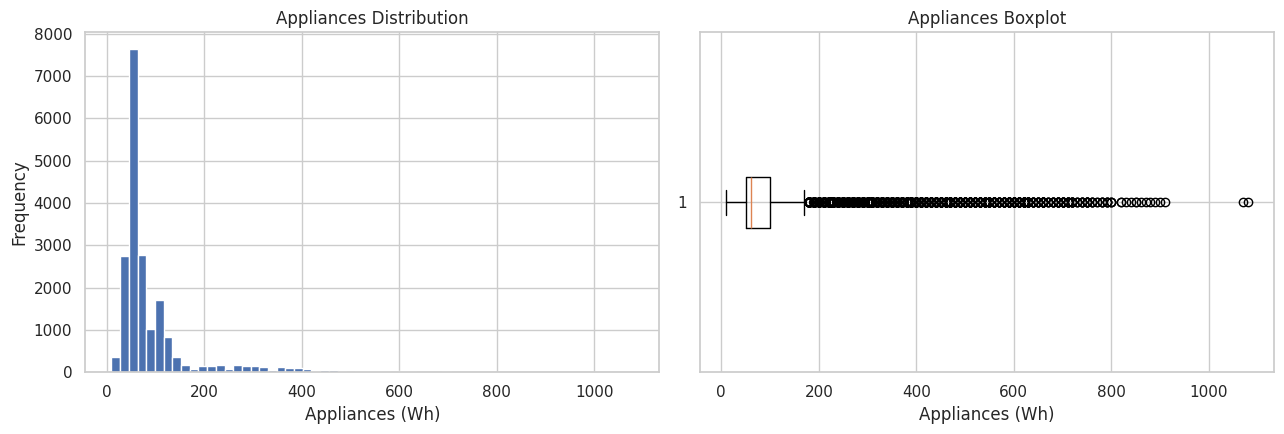


Target analysis saved.
IQR flags are diagnostic only.
No outliers have been removed.


In [ ]:

# ============================================================
# CELL 06 — TARGET DISTRIBUTION ANALYSIS
# ============================================================

# ------------------------------------------------------------
# 1. Original target
# ------------------------------------------------------------

y = df_raw["Appliances"]

q1 = y.quantile(0.25)
q3 = y.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

iqr_flags = (
    (y < lower_bound) | (y > upper_bound)
)

# ------------------------------------------------------------
# 2. Descriptive statistics
# ------------------------------------------------------------

target_summary = {
    "count": int(y.count()),
    "mean": float(y.mean()),
    "median": float(y.median()),
    "std": float(y.std()),
    "min": float(y.min()),
    "q1": float(q1),
    "q3": float(q3),
    "max": float(y.max()),
    "skewness": float(y.skew()),
    "excess_kurtosis": float(y.kurt()),
    "coefficient_of_variation": float(
        y.std() / y.mean()
    ),
    "iqr_lower_bound": float(lower_bound),
    "iqr_upper_bound": float(upper_bound),
    "iqr_flagged_count": int(iqr_flags.sum()),
    "iqr_flagged_pct": float(
        iqr_flags.mean() * 100
    )
}

print("TARGET DISTRIBUTION SUMMARY")
display(
    pd.DataFrame(
        target_summary.items(),
        columns=["Statistic", "Value"]
    )
)

# ------------------------------------------------------------
# 3. Distribution visualization
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2, figsize=(13, 4.5)
)

axes[0].hist(
    y, bins=60, edgecolor="white"
)
axes[0].set_title("Appliances Distribution")
axes[0].set_xlabel("Appliances (Wh)")
axes[0].set_ylabel("Frequency")

axes[1].boxplot(
    y, vert=False
)
axes[1].set_title("Appliances Boxplot")
axes[1].set_xlabel("Appliances (Wh)")

plt.tight_layout()

figure_path = (
    PATHS["eda"] / "03_target_distribution.png"
)

plt.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 4. Save descriptive results
# ------------------------------------------------------------

with open(
    PATHS["eda"] / "04_target_summary.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(target_summary, f, indent=4)

print("\nTarget analysis saved.")
print("IQR flags are diagnostic only.")
print("No outliers have been removed.")


## Predictor Distribution and Outlier Diagnostics

PREDICTOR DISTRIBUTION SUMMARY


,variable,mean,std,median,min,max,skewness,excess_kurtosis,zero_pct,iqr_flagged_pct,unique_values
0,lights,3.8019,7.9360,0.0000,0.0000,70.0000,2.1952,4.4621,77.2840,22.7160,8
1,T1,21.6866,1.6061,21.6000,16.7900,26.2600,0.1209,0.1616,0.0000,2.6096,722
2,RH_1,40.2597,3.9793,39.6567,27.0233,63.3600,0.4658,0.1126,0.0000,0.7398,2547
3,T2,20.3412,2.1930,20.0000,16.1000,29.8567,0.8897,0.9334,0.0000,2.7667,1650
4,RH_2,40.4204,4.0698,40.5000,20.4633,56.0267,-0.2682,0.6710,0.0000,1.1908,3376
5,T3,22.2676,2.0061,22.1000,17.2000,29.2360,0.4508,-0.0071,0.0000,1.0996,1426
6,RH_3,39.2425,3.2546,38.5300,28.7667,50.1633,0.4676,-0.5831,0.0000,0.0760,2618
7,T4,20.8553,2.0429,20.6667,15.1000,26.2000,0.1704,-0.0376,0.0000,0.9425,1390
8,RH_4,39.0269,4.3413,38.4000,27.6600,51.0900,0.4446,-0.6140,0.0000,0.0000,2987
9,T5,19.5921,1.8446,19.3900,15.3300,25.7950,0.5582,0.1127,0.0000,0.9070,2263



TOP 10 MOST SKEWED PREDICTORS


,variable,mean,std,median,min,max,skewness,excess_kurtosis,zero_pct,iqr_flagged_pct,unique_values,abs_skew
0,lights,3.8019,7.9360,0.0000,0.0000,70.0000,2.1952,4.4621,77.2840,22.7160,8,2.1952
10,RH_5,50.9493,9.0220,49.0900,29.8150,96.3217,1.8668,4.5034,0.0000,6.7393,7571,1.8668
21,RH_out,79.7504,14.9011,83.6667,24.0000,100.0000,-0.9230,0.2569,0.0000,1.2110,566,0.9230
3,T2,20.3412,2.1930,20.0000,16.1000,29.8567,0.8897,0.9334,0.0000,2.7667,1650,0.8897
22,Windspeed,4.0398,2.4512,3.6667,0.0000,14.0000,0.8600,0.2500,0.0304,1.0844,189,0.8600
11,T6,7.9109,6.0903,7.3000,-6.0650,28.2900,0.5975,0.4255,0.1317,2.6096,4446,0.5975
9,T5,19.5921,1.8446,19.3900,15.3300,25.7950,0.5582,0.1127,0.0000,0.9070,2263,0.5582
19,T_out,7.4117,5.3174,6.9167,-5.0000,26.1000,0.5343,0.3643,0.1368,2.2093,1730,0.5343
6,RH_3,39.2425,3.2546,38.5300,28.7667,50.1633,0.4676,-0.5831,0.0000,0.0760,2618,0.4676
2,RH_1,40.2597,3.9793,39.6567,27.0233,63.3600,0.4658,0.1126,0.0000,0.7398,2547,0.4658



TOP 10 PREDICTORS BY IQR FLAG RATE


,variable,mean,std,median,min,max,skewness,excess_kurtosis,zero_pct,iqr_flagged_pct,unique_values
0,lights,3.8019,7.9360,0.0000,0.0000,70.0000,2.1952,4.4621,77.2840,22.7160,8
23,Visibility,38.3308,11.7947,40.0000,1.0000,66.0000,0.4416,0.1658,0.0000,12.7793,413
10,RH_5,50.9493,9.0220,49.0900,29.8150,96.3217,1.8668,4.5034,0.0000,6.7393,7571
3,T2,20.3412,2.1930,20.0000,16.1000,29.8567,0.8897,0.9334,0.0000,2.7667,1650
1,T1,21.6866,1.6061,21.6000,16.7900,26.2600,0.1209,0.1616,0.0000,2.6096,722
11,T6,7.9109,6.0903,7.3000,-6.0650,28.2900,0.5975,0.4255,0.1317,2.6096,4446
19,T_out,7.4117,5.3174,6.9167,-5.0000,26.1000,0.5343,0.3643,0.1368,2.2093,1730
21,RH_out,79.7504,14.9011,83.6667,24.0000,100.0000,-0.9230,0.2569,0.0000,1.2110,566
4,RH_2,40.4204,4.0698,40.5000,20.4633,56.0267,-0.2682,0.6710,0.0000,1.1908,3376
20,Press_mm_hg,755.5226,7.3994,756.1000,729.3000,772.3000,-0.4204,0.0718,0.0000,1.1097,2189


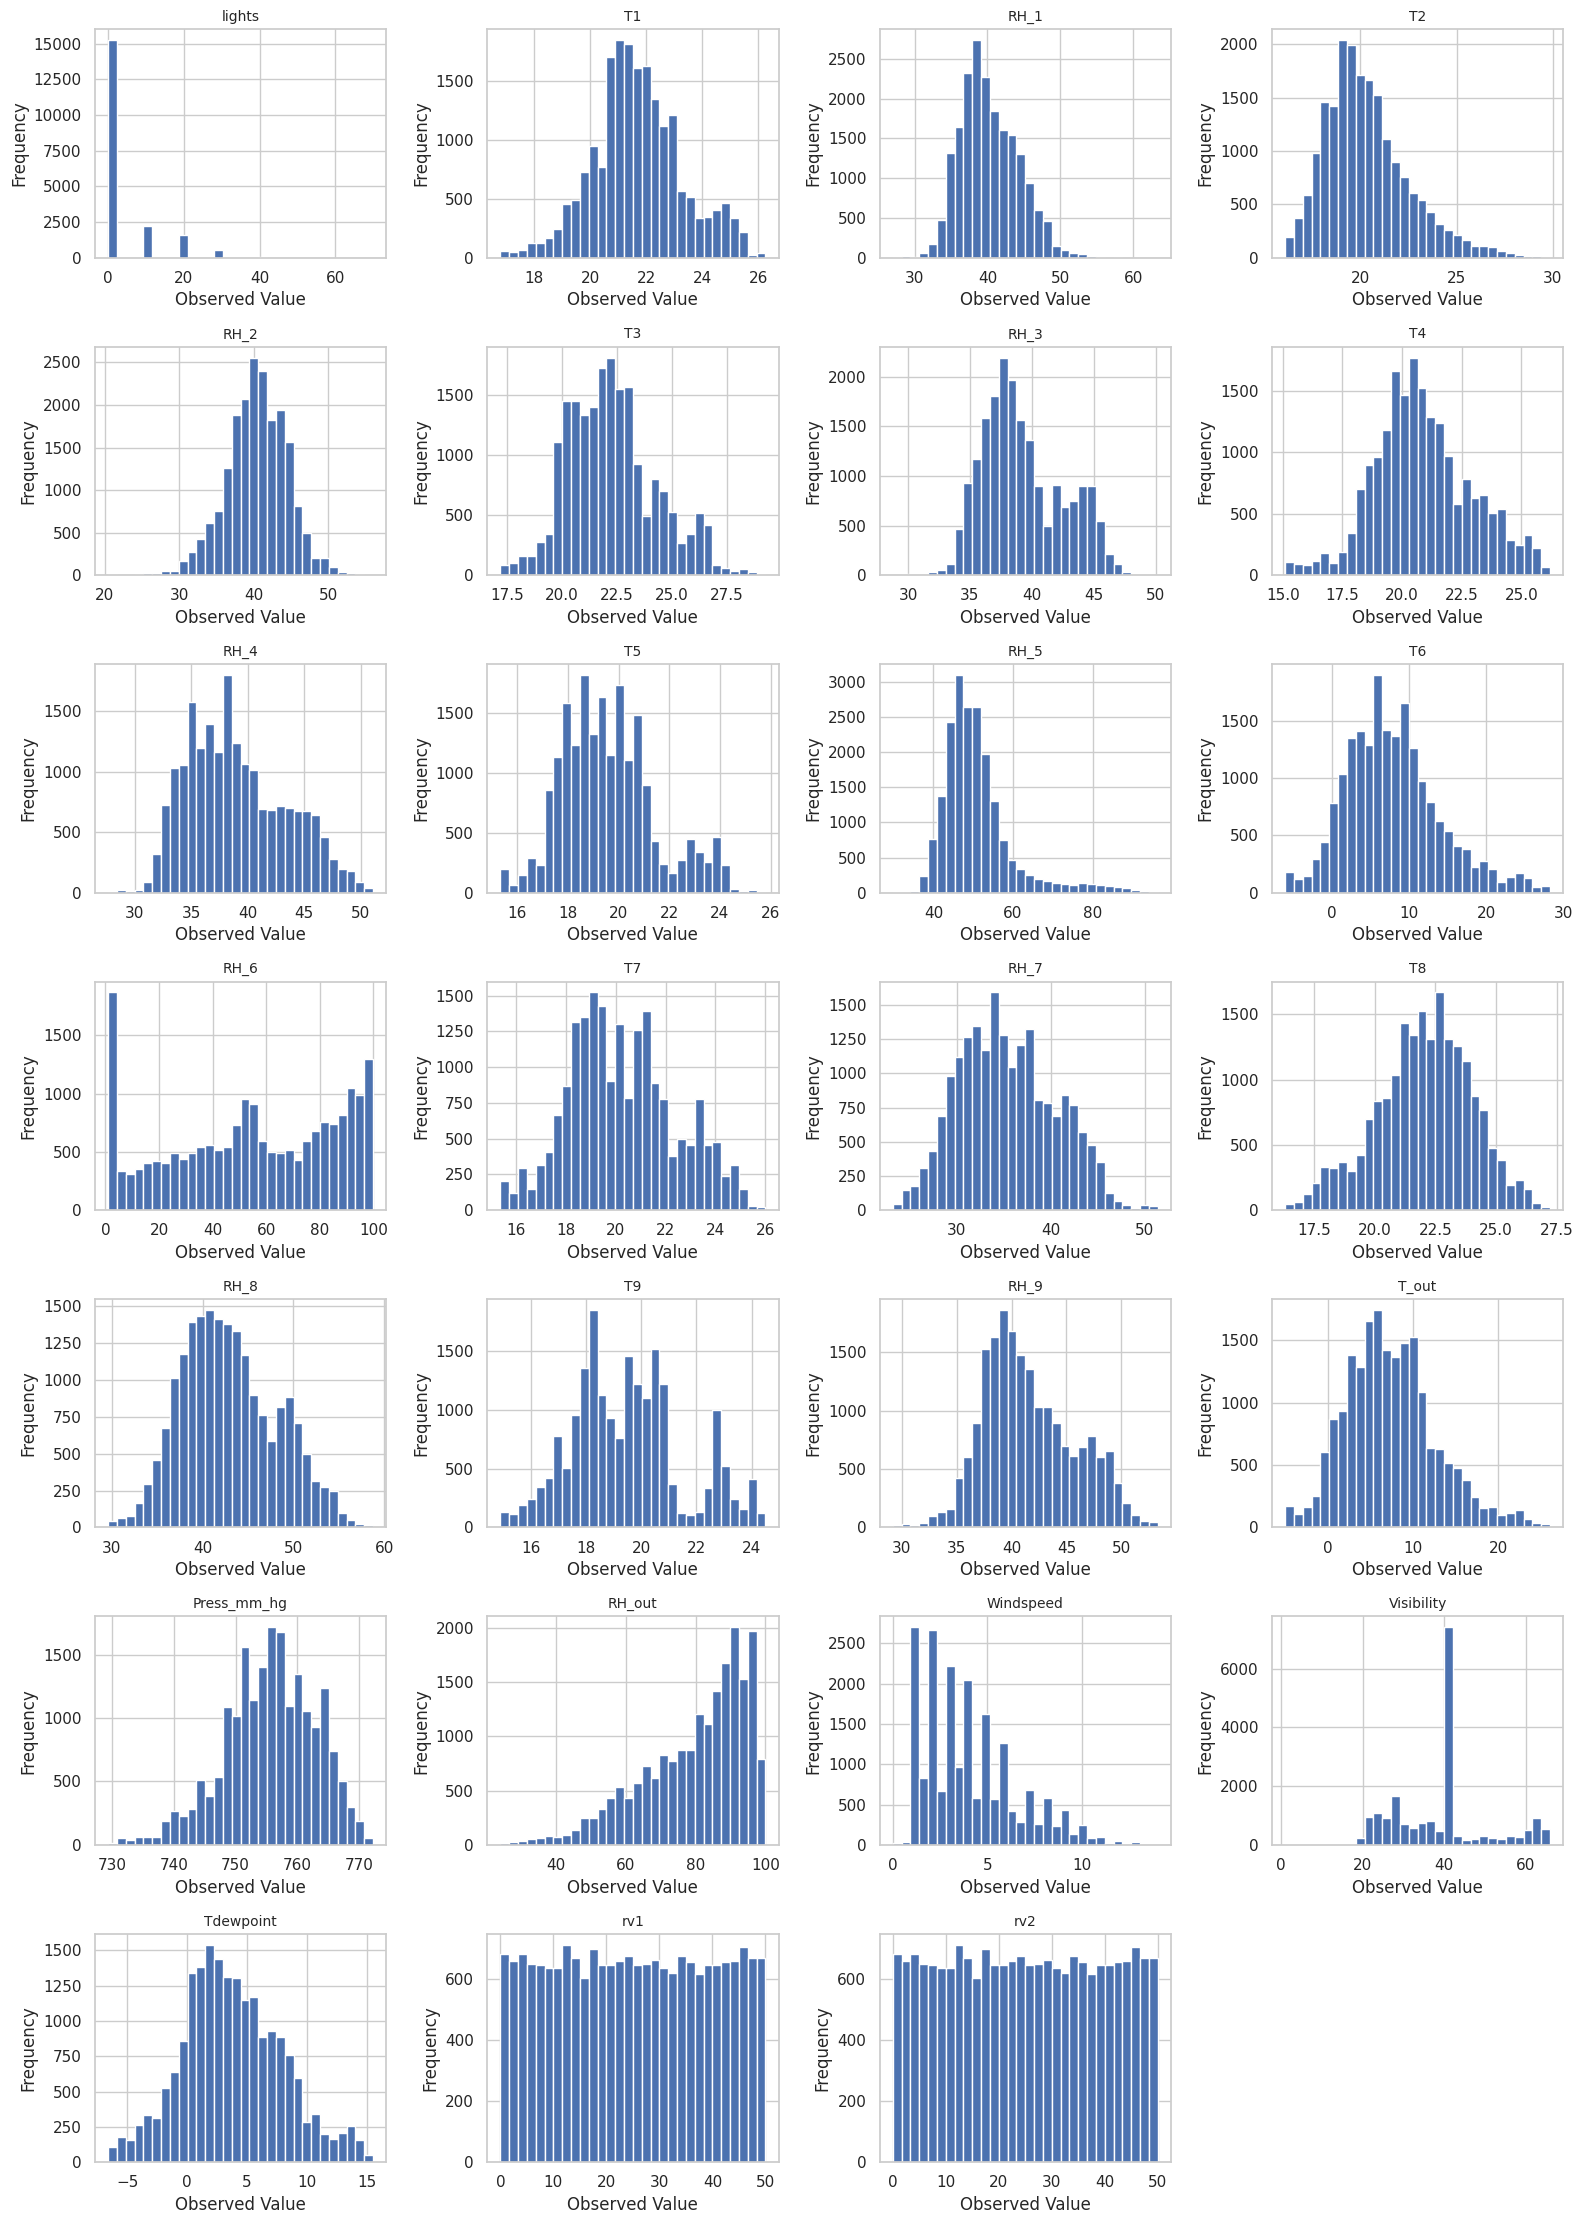

/tmp/ipykernel_2854/2166328564.py:132: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


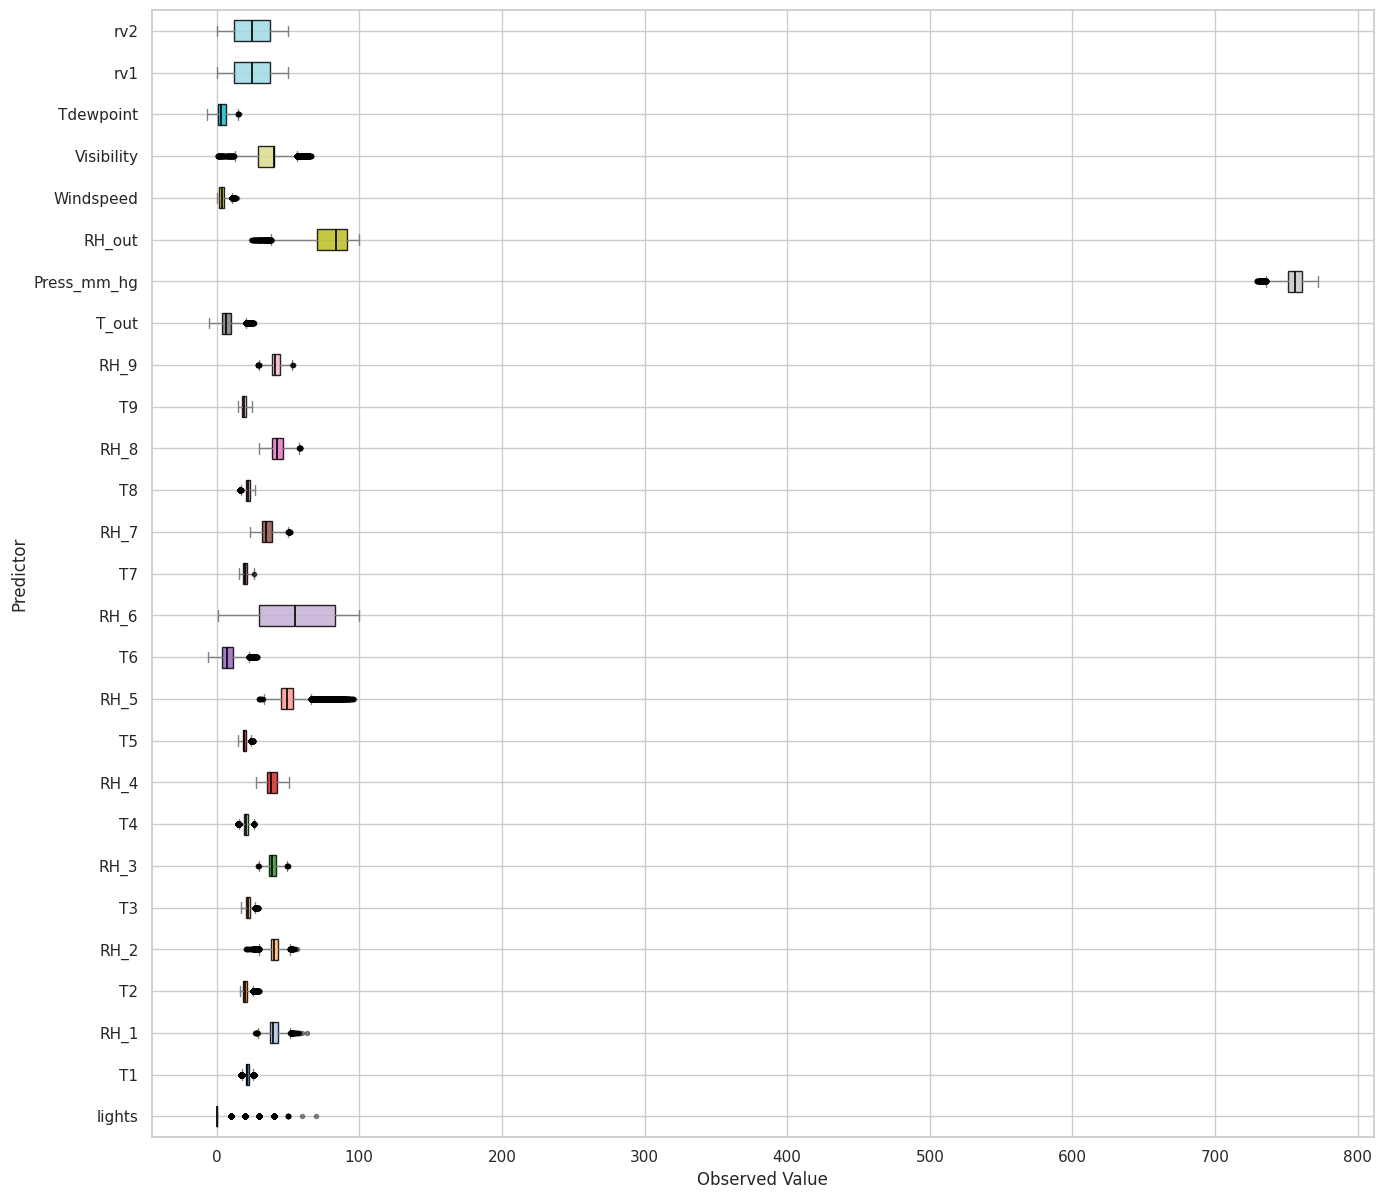


Predictor diagnostics saved.
- Histogram figure : 05_predictor_distributions.png
- Boxplot figure   : 06_predictor_boxplots_horizontal.png
- Summary table    : 05_predictor_descriptive.csv
No feature transformation or removal performed.


In [ ]:
# ============================================================
# CELL 07 — PREDICTOR DISTRIBUTION DIAGNOSTICS
# ============================================================

# ------------------------------------------------------------
# 1. Define numeric predictors
# ------------------------------------------------------------

predictor_cols = [
    col for col in numeric_cols
    if col != "Appliances"
]

# ------------------------------------------------------------
# 2. Distribution diagnostics
# ------------------------------------------------------------

records = []

for col in predictor_cols:

    x = df_raw[col]

    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    flagged = (x < lower) | (x > upper)

    records.append({
        "variable": col,
        "mean": x.mean(),
        "std": x.std(),
        "median": x.median(),
        "min": x.min(),
        "max": x.max(),
        "skewness": x.skew(),
        "excess_kurtosis": x.kurt(),
        "zero_pct": (x == 0).mean() * 100,
        "iqr_flagged_pct": flagged.mean() * 100,
        "unique_values": x.nunique()
    })

predictor_summary = pd.DataFrame(records)

# ------------------------------------------------------------
# 3. Summary tables
# ------------------------------------------------------------

print("PREDICTOR DISTRIBUTION SUMMARY")
display(predictor_summary)

print("\nTOP 10 MOST SKEWED PREDICTORS")
display(
    predictor_summary.assign(
        abs_skew=lambda d: d["skewness"].abs()
    )
    .sort_values("abs_skew", ascending=False)
    .head(10)
)

print("\nTOP 10 PREDICTORS BY IQR FLAG RATE")
display(
    predictor_summary.sort_values(
        "iqr_flagged_pct", ascending=False
    ).head(10)
)

# ------------------------------------------------------------
# 4A. Histogram distributions
# ------------------------------------------------------------

ncols = 4
nrows = int(np.ceil(len(predictor_cols) / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(16, nrows * 3.2)
)

axes = np.asarray(axes).ravel()

for i, col in enumerate(predictor_cols):

    axes[i].hist(
        df_raw[col],
        bins=30,
        edgecolor="white"
    )

    # nama variabel tetap perlu agar subplot bisa dikenali
    axes[i].set_title(col, fontsize=10)

    # label sumbu harus jelas
    axes[i].set_xlabel("Observed Value")
    axes[i].set_ylabel("Frequency")

for j in range(len(predictor_cols), len(axes)):
    axes[j].axis("off")

plt.tight_layout()

hist_path = PATHS["eda"] / "05_predictor_distributions.png"

plt.savefig(
    hist_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 4B. Horizontal boxplots for outlier diagnostics
# ------------------------------------------------------------

boxplot_data = [
    df_raw[col].dropna().values
    for col in predictor_cols
]

fig_height = max(8, len(predictor_cols) * 0.45)

fig, ax = plt.subplots(
    figsize=(14, fig_height)
)

bp = ax.boxplot(
    boxplot_data,
    vert=False,
    labels=predictor_cols,
    patch_artist=True,
    showfliers=True,
    flierprops=dict(
        marker="o",
        markersize=3,
        markerfacecolor="black",
        markeredgecolor="black",
        alpha=0.40
    ),
    medianprops=dict(
        color="black",
        linewidth=1.2
    ),
    whiskerprops=dict(
        color="gray",
        linewidth=1.0
    ),
    capprops=dict(
        color="gray",
        linewidth=1.0
    ),
    boxprops=dict(
        linewidth=1.0
    )
)

# warna berbeda untuk tiap box
colors = plt.cm.tab20(
    np.linspace(0, 1, len(predictor_cols))
)

for patch, color in zip(bp["boxes"], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.85)

# label sumbu harus jelas
ax.set_xlabel("Observed Value")
ax.set_ylabel("Predictor")

plt.tight_layout()

boxplot_path = (
    PATHS["eda"] / "06_predictor_boxplots_horizontal.png"
)

plt.savefig(
    boxplot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 5. Save diagnostic table
# ------------------------------------------------------------

predictor_summary.to_csv(
    PATHS["eda"] / "05_predictor_descriptive.csv",
    index=False
)

print("\nPredictor diagnostics saved.")
print(f"- Histogram figure : {hist_path.name}")
print(f"- Boxplot figure   : {boxplot_path.name}")
print("- Summary table    : 05_predictor_descriptive.csv")
print("No feature transformation or removal performed.")

## Temporal Diagnostics and Autocorrelation Analysis

TEMPORAL DATA STRUCTURE
Start: 2016-01-11 17:00:00
End: 2016-05-27 18:00:00
Observations: 19735

DAILY COMPLETENESS
Total calendar days: 138
Complete days: 136
Incomplete days: 2

Incomplete days (if any):


,count,mean,median
date,,,
2016-01-11,42,136.6667,100.0000
2016-05-27,109,136.3303,70.0000



MONTHLY TARGET SUMMARY


,count,mean,median,std,min,max
date,,,,,,
2016-01,2922,97.0260,50.0000,123.0151,10,1080
2016-02,4176,100.9459,60.0000,102.3543,10,770
2016-03,4464,96.9534,60.0000,99.0071,20,880
2016-04,4320,98.8889,60.0000,103.8966,20,900
2016-05,3853,94.1993,60.0000,86.7952,20,850



HOURLY TARGET SUMMARY


,count,mean,median
date,,,
0,822,52.7859,50.0000
1,822,51.3260,50.0000
2,822,49.0754,50.0000
3,822,48.2360,50.0000
4,822,49.3552,50.0000
5,822,52.7372,50.0000
6,822,57.7129,50.0000
7,822,78.6496,60.0000
8,822,106.1436,60.0000



WEEKDAY TARGET SUMMARY


,count,mean,median
Mon,2778,111.4507,60.0000
Tue,2880,87.1250,60.0000
Wed,2880,89.9306,70.0000
Thu,2880,90.4340,60.0000
Fri,2845,104.6221,60.0000
Sat,2736,106.2463,70.0000
Sun,2736,94.9159,60.0000


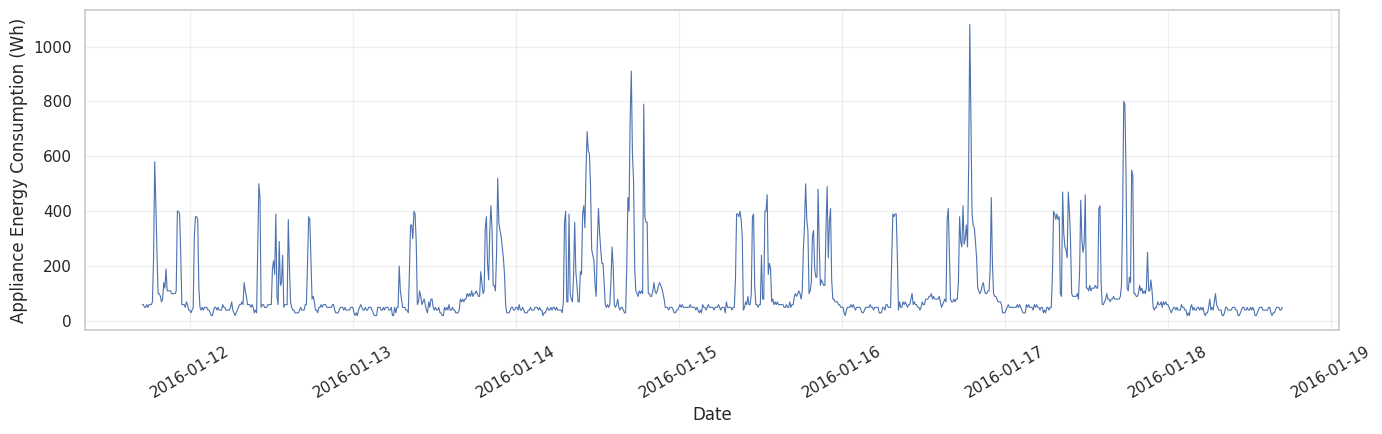

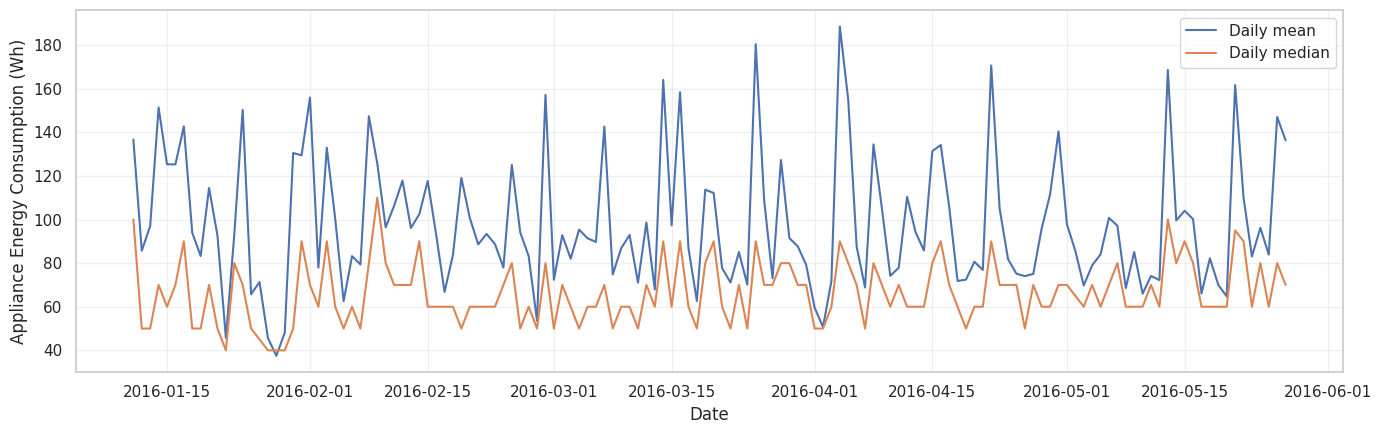

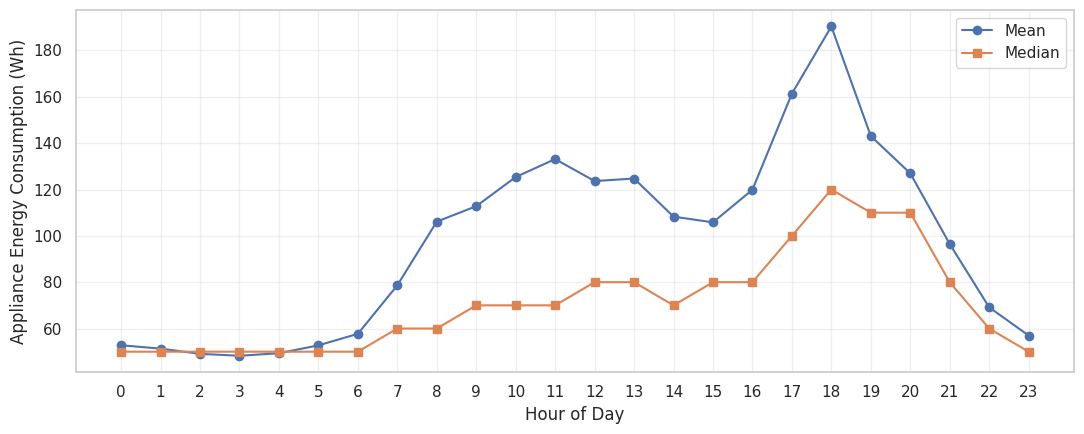

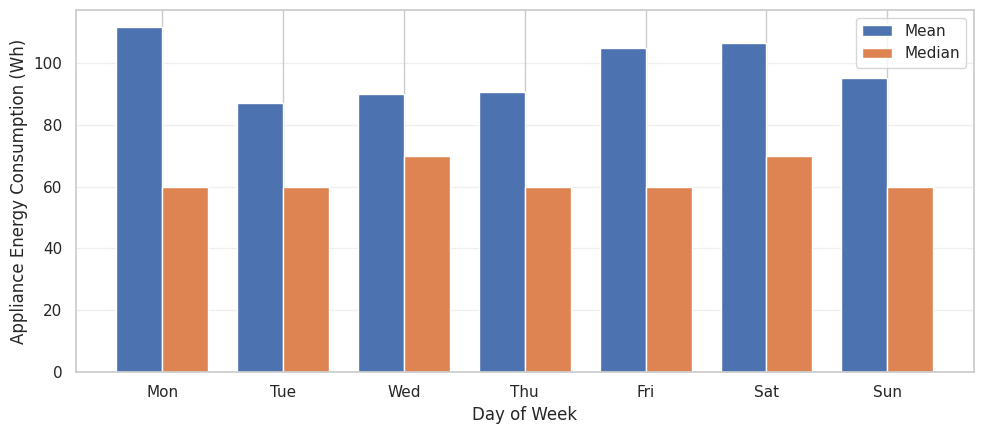


AUTOCORRELATION SUMMARY — ALL VARIABLES


,variable,lag_1,lag_6,lag_144,lag_1008
0,Appliances,0.7530,0.3235,0.2147,0.2056
1,lights,0.7838,0.5234,0.2032,0.2003
2,T1,0.9994,0.9910,0.8503,0.5462
3,RH_1,0.9924,0.9345,0.6999,0.1636
4,T2,0.9989,0.9757,0.8382,0.5325
5,RH_2,0.9977,0.9625,0.7019,0.1860
6,T3,0.9993,0.9893,0.8358,0.5856
7,RH_3,0.9982,0.9744,0.7953,0.3791
8,T4,0.9991,0.9866,0.8638,0.5785
9,RH_4,0.9991,0.9883,0.7881,0.2809


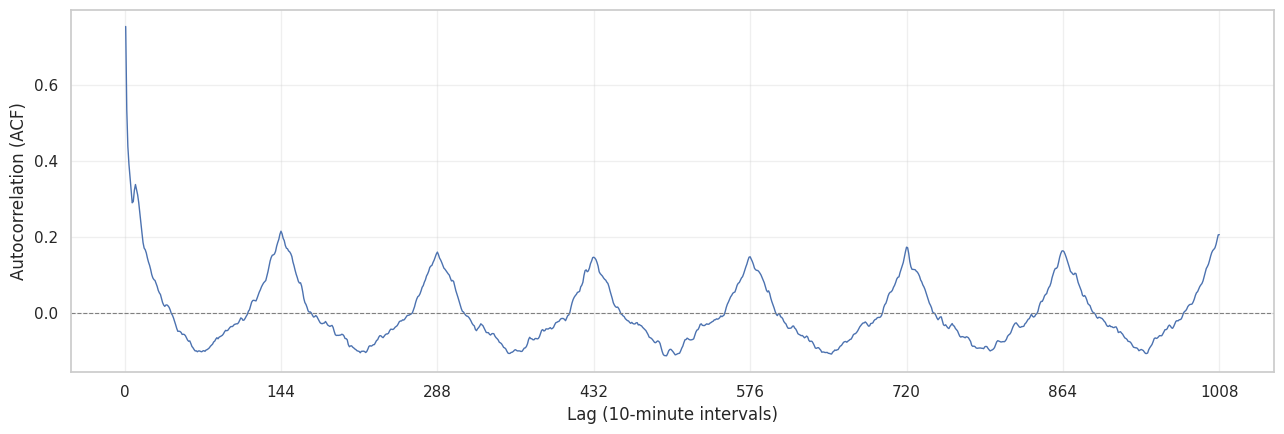

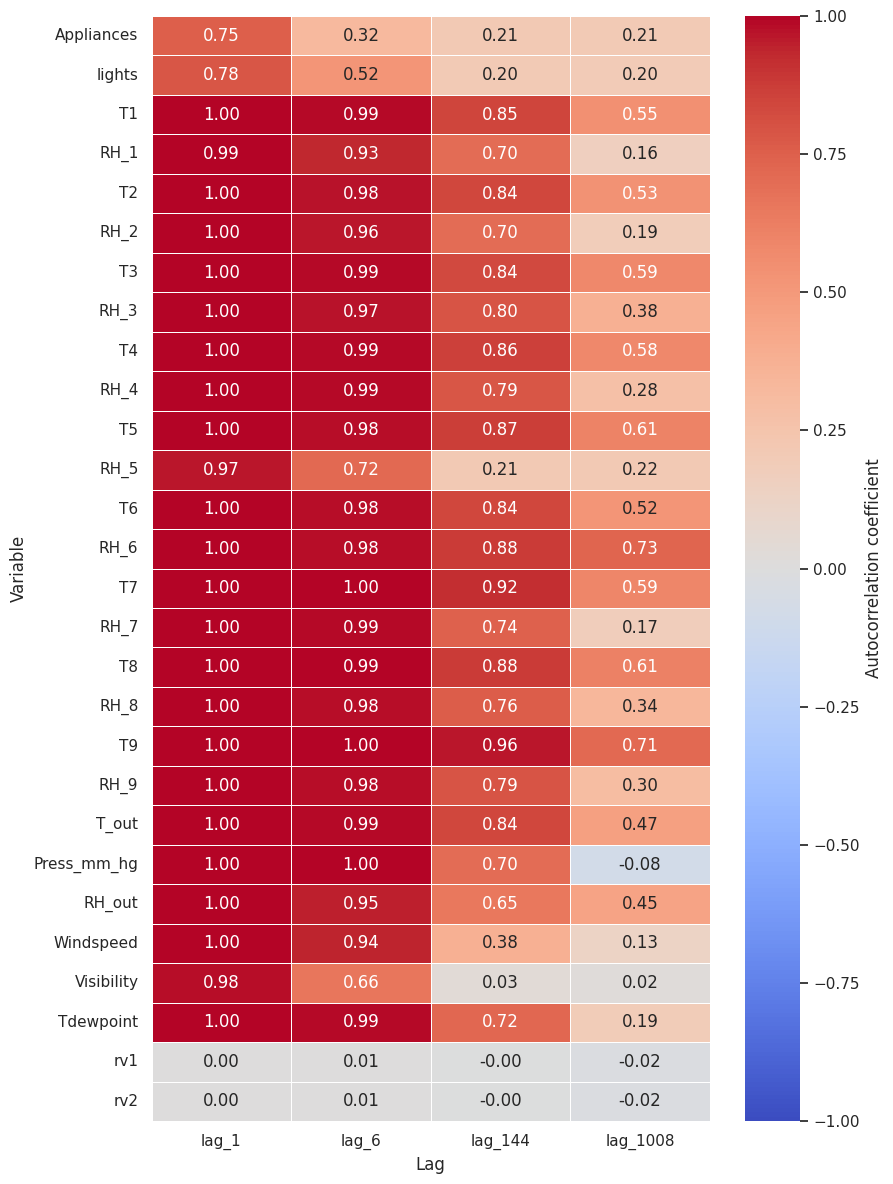


TEMPORAL DIAGNOSTICS COMPLETED
All tables and figures saved in 01_eda.
Original dataset remains unchanged.
No bootstrap block length has been selected.


In [11]:

# ============================================================
# CELL 08 — TEMPORAL DIAGNOSTICS & AUTOCORRELATION
# ============================================================

from statsmodels.tsa.stattools import acf

# ------------------------------------------------------------
# 1. Prepare temporal data (diagnostic copy)
# ------------------------------------------------------------

df_temporal = df_raw.copy()

df_temporal["date"] = pd.to_datetime(
    df_temporal["date"],
    errors="raise"
)

assert df_temporal["date"].is_monotonic_increasing, \
    "Timestamp is not chronologically ordered."

assert df_temporal["date"].is_unique, \
    "Duplicate timestamps detected."

df_temporal = df_temporal.set_index("date")

target = "Appliances"

# Full data are used here for descriptive EDA only.
# No data-dependent model selection is performed.

print("=" * 60)
print("TEMPORAL DATA STRUCTURE")
print("=" * 60)

print("Start:", df_temporal.index.min())
print("End:", df_temporal.index.max())
print("Observations:", len(df_temporal))

# ------------------------------------------------------------
# 2. Daily observation completeness
# ------------------------------------------------------------

daily_summary = df_temporal[target].resample("D").agg(
    ["count", "mean", "median", "std", "min", "max"]
)

EXPECTED_DAILY_COUNT = 144

daily_summary["complete_day"] = (
    daily_summary["count"] == EXPECTED_DAILY_COUNT
)

print("\nDAILY COMPLETENESS")

print("Total calendar days:", len(daily_summary))
print(
    "Complete days:",
    int(daily_summary["complete_day"].sum())
)
print(
    "Incomplete days:",
    int((~daily_summary["complete_day"]).sum())
)

print("\nIncomplete days (if any):")

display(
    daily_summary.loc[
        ~daily_summary["complete_day"],
        ["count", "mean", "median"]
    ]
)

# ------------------------------------------------------------
# 3. Monthly descriptive summary
# ------------------------------------------------------------

monthly_summary = df_temporal[target].resample("MS").agg(
    ["count", "mean", "median", "std", "min", "max"]
)

monthly_summary.index = (
    monthly_summary.index.strftime("%Y-%m")
)

print("\nMONTHLY TARGET SUMMARY")
display(monthly_summary)

# ------------------------------------------------------------
# 4. Hourly and weekday patterns
# ------------------------------------------------------------

hourly_summary = df_temporal.groupby(
    df_temporal.index.hour
)[target].agg(["count", "mean", "median"])

weekday_summary = df_temporal.groupby(
    df_temporal.index.dayofweek
)[target].agg(["count", "mean", "median"])

weekday_summary = weekday_summary.reindex(range(7))

weekday_labels = [
    "Mon", "Tue", "Wed", "Thu",
    "Fri", "Sat", "Sun"
]

print("\nHOURLY TARGET SUMMARY")
display(hourly_summary)

print("\nWEEKDAY TARGET SUMMARY")
display(
    weekday_summary.set_axis(
        weekday_labels, axis=0
    )
)

# ------------------------------------------------------------
# 5. Temporal visualization — first seven days
# ------------------------------------------------------------

start_time = df_temporal.index.min()
end_time = start_time + pd.Timedelta(days=7)

sample_week = df_temporal.loc[
    (df_temporal.index >= start_time) &
    (df_temporal.index < end_time)
]

fig, ax = plt.subplots(figsize=(14, 4.5))

ax.plot(
    sample_week.index,
    sample_week[target],
    linewidth=0.8
)

ax.set_xlabel("Date")
ax.set_ylabel("Appliance Energy Consumption (Wh)")

ax.tick_params(axis="x", rotation=30)
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    PATHS["eda"] / "07_target_first_week.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 6. Daily trend — mean and median
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(14, 4.5))

ax.plot(
    daily_summary.index,
    daily_summary["mean"],
    label="Daily mean",
    linewidth=1.5
)

ax.plot(
    daily_summary.index,
    daily_summary["median"],
    label="Daily median",
    linewidth=1.5
)

ax.set_xlabel("Date")
ax.set_ylabel("Appliance Energy Consumption (Wh)")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    PATHS["eda"] / "08_target_daily_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 7. Hour-of-day pattern
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 4.5))

ax.plot(
    hourly_summary.index,
    hourly_summary["mean"],
    marker="o",
    label="Mean"
)

ax.plot(
    hourly_summary.index,
    hourly_summary["median"],
    marker="s",
    label="Median"
)

ax.set_xlabel("Hour of Day")
ax.set_ylabel("Appliance Energy Consumption (Wh)")

ax.set_xticks(range(24))
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    PATHS["eda"] / "09_hourly_energy_pattern.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 8. Day-of-week pattern
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 4.5))

positions = np.arange(7)

width = 0.38

ax.bar(
    positions - width / 2,
    weekday_summary["mean"],
    width=width,
    label="Mean"
)

ax.bar(
    positions + width / 2,
    weekday_summary["median"],
    width=width,
    label="Median"
)

ax.set_xticks(positions)
ax.set_xticklabels(weekday_labels)

ax.set_xlabel("Day of Week")
ax.set_ylabel("Appliance Energy Consumption (Wh)")

ax.legend()
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

plt.savefig(
    PATHS["eda"] / "10_weekday_energy_pattern.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 9. Autocorrelation analysis — all numeric variables
# ------------------------------------------------------------

acf_columns = df_temporal.select_dtypes(
    include=[np.number]
).columns.tolist()

selected_lags = {
    "lag_1": 1,       # 10 minutes
    "lag_6": 6,       # 1 hour
    "lag_144": 144,   # 1 day
    "lag_1008": 1008  # 7 days
}

max_lag = max(selected_lags.values())

if len(df_temporal) <= max_lag:
    raise ValueError(
        "Not enough observations for selected ACF lags."
    )

acf_results = {}
acf_records = []

for col in acf_columns:

    values = df_temporal[col].to_numpy(
        dtype=float
    )

    acf_values = acf(
        values,
        nlags=max_lag,
        fft=True,
        missing="raise"
    )

    acf_results[col] = acf_values

    record = {"variable": col}

    for label, lag in selected_lags.items():
        record[label] = float(acf_values[lag])

    acf_records.append(record)

acf_summary = pd.DataFrame(acf_records)

print("\nAUTOCORRELATION SUMMARY — ALL VARIABLES")
display(acf_summary)

# ------------------------------------------------------------
# 10. Target ACF visualization
# ------------------------------------------------------------

target_acf = acf_results[target]

fig, ax = plt.subplots(figsize=(13, 4.5))

ax.plot(
    np.arange(1, max_lag + 1),
    target_acf[1:],
    linewidth=1
)

ax.axhline(
    y=0,
    linestyle="--",
    linewidth=0.8,
    color="gray"
)

ax.set_xlabel("Lag (10-minute intervals)")
ax.set_ylabel("Autocorrelation (ACF)")

ax.set_xticks(
    np.arange(0, max_lag + 1, 144)
)

ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    PATHS["eda"] / "11_target_acf.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 11. ACF heatmap — all predictors and target
# ------------------------------------------------------------

acf_heatmap = acf_summary.set_index("variable")[
    list(selected_lags.keys())
]

fig, ax = plt.subplots(figsize=(9, 12))

sns.heatmap(
    acf_heatmap,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.4,
    cbar_kws={
        "label": "Autocorrelation coefficient"
    },
    ax=ax
)

ax.set_xlabel("Lag")
ax.set_ylabel("Variable")

plt.tight_layout()

plt.savefig(
    PATHS["eda"] / "12_acf_heatmap_all_variables.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 12. Save all temporal diagnostic results
# ------------------------------------------------------------

daily_summary.to_csv(
    PATHS["eda"] / "06_daily_temporal_summary.csv"
)

monthly_summary.to_csv(
    PATHS["eda"] / "07_monthly_temporal_summary.csv"
)

hourly_summary.to_csv(
    PATHS["eda"] / "08_hourly_temporal_summary.csv"
)

weekday_summary.to_csv(
    PATHS["eda"] / "09_weekday_temporal_summary.csv"
)

acf_summary.to_csv(
    PATHS["eda"] / "10_acf_all_variables.csv",
    index=False
)

print("\n" + "=" * 60)
print("TEMPORAL DIAGNOSTICS COMPLETED")
print("=" * 60)

print("All tables and figures saved in 01_eda.")
print("Original dataset remains unchanged.")
print("No bootstrap block length has been selected.")


## Predictor Correlation and Redundancy Diagnostics

PREDICTOR CORRELATION & REDUNDANCY
Observations: 19735
Predictors: 27
No predictors removed.

PAIRWISE CORRELATION SUMMARY
Total predictor pairs: 351

STRONG CORRELATION PAIRS
Diagnostic threshold: 0.9
Number of flagged pairs: 5


,predictor_1,predictor_2,pearson_r,spearman_r,first_difference_r
0,rv1,rv2,1.0000,1.0000,1.0000
1,T6,T_out,0.9748,0.9762,0.5089
2,T7,T9,0.9448,0.9239,0.0617
3,T5,T9,0.9111,0.8851,-0.0036
4,T3,T9,0.9013,0.8875,0.0204



RV1–RV2 REDUNDANCY CHECK
Exact equality: True
Pearson correlation: 1.0
Spearman correlation: 1.0


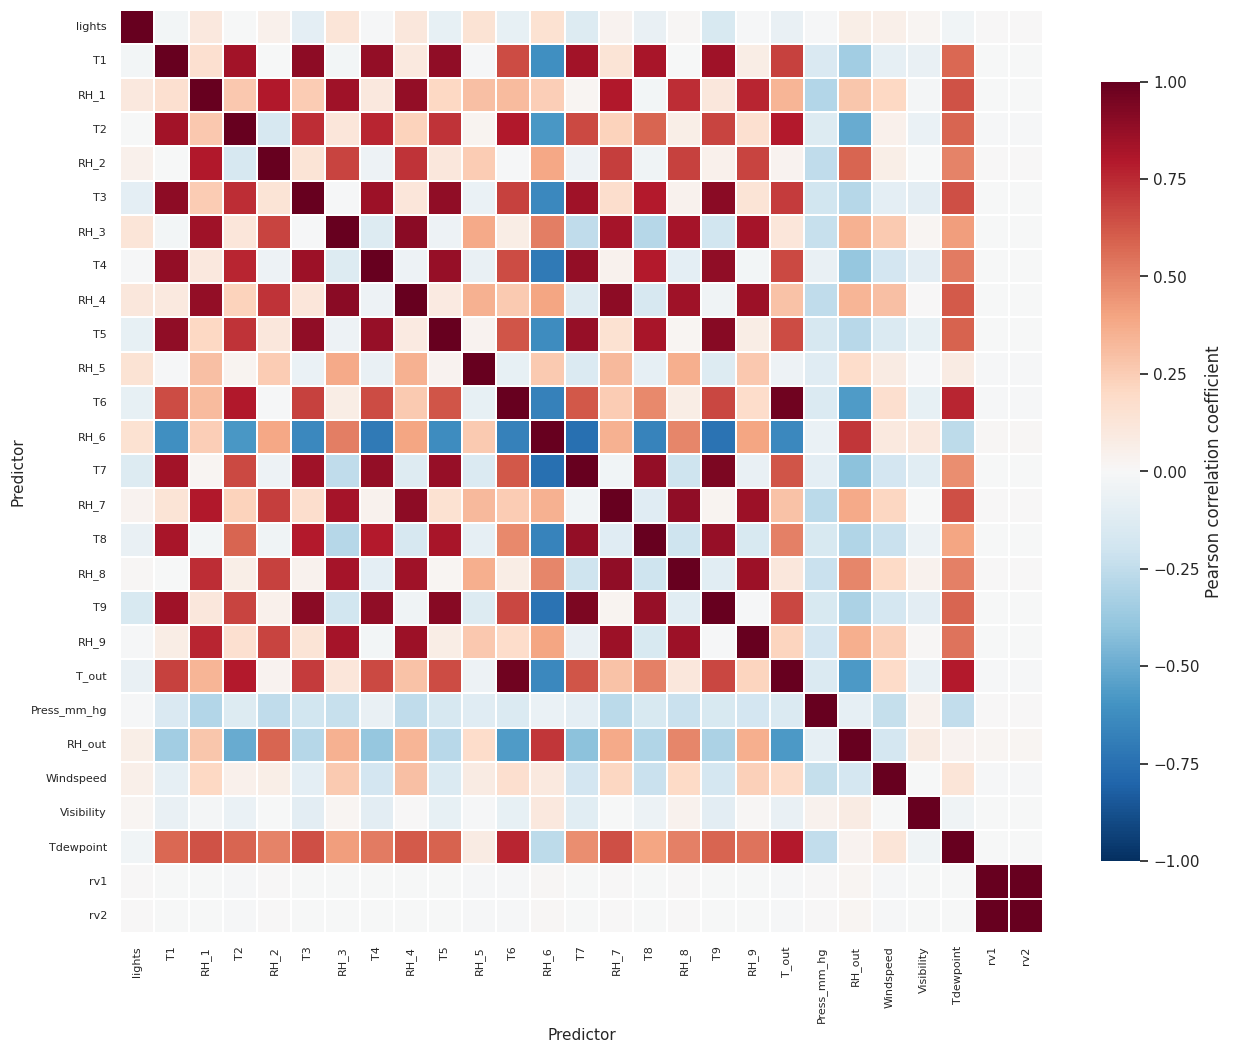

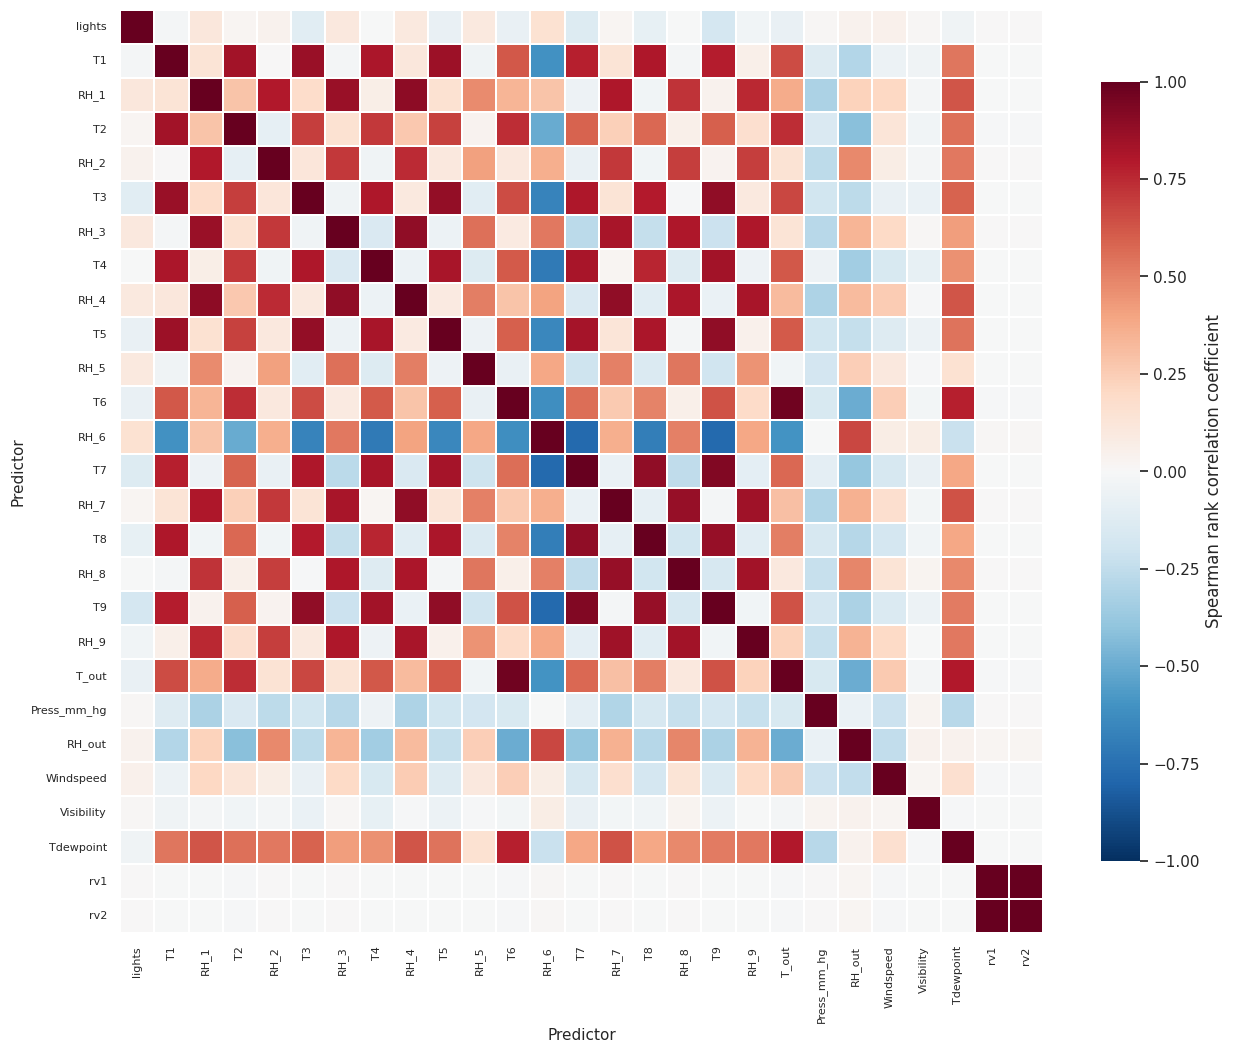

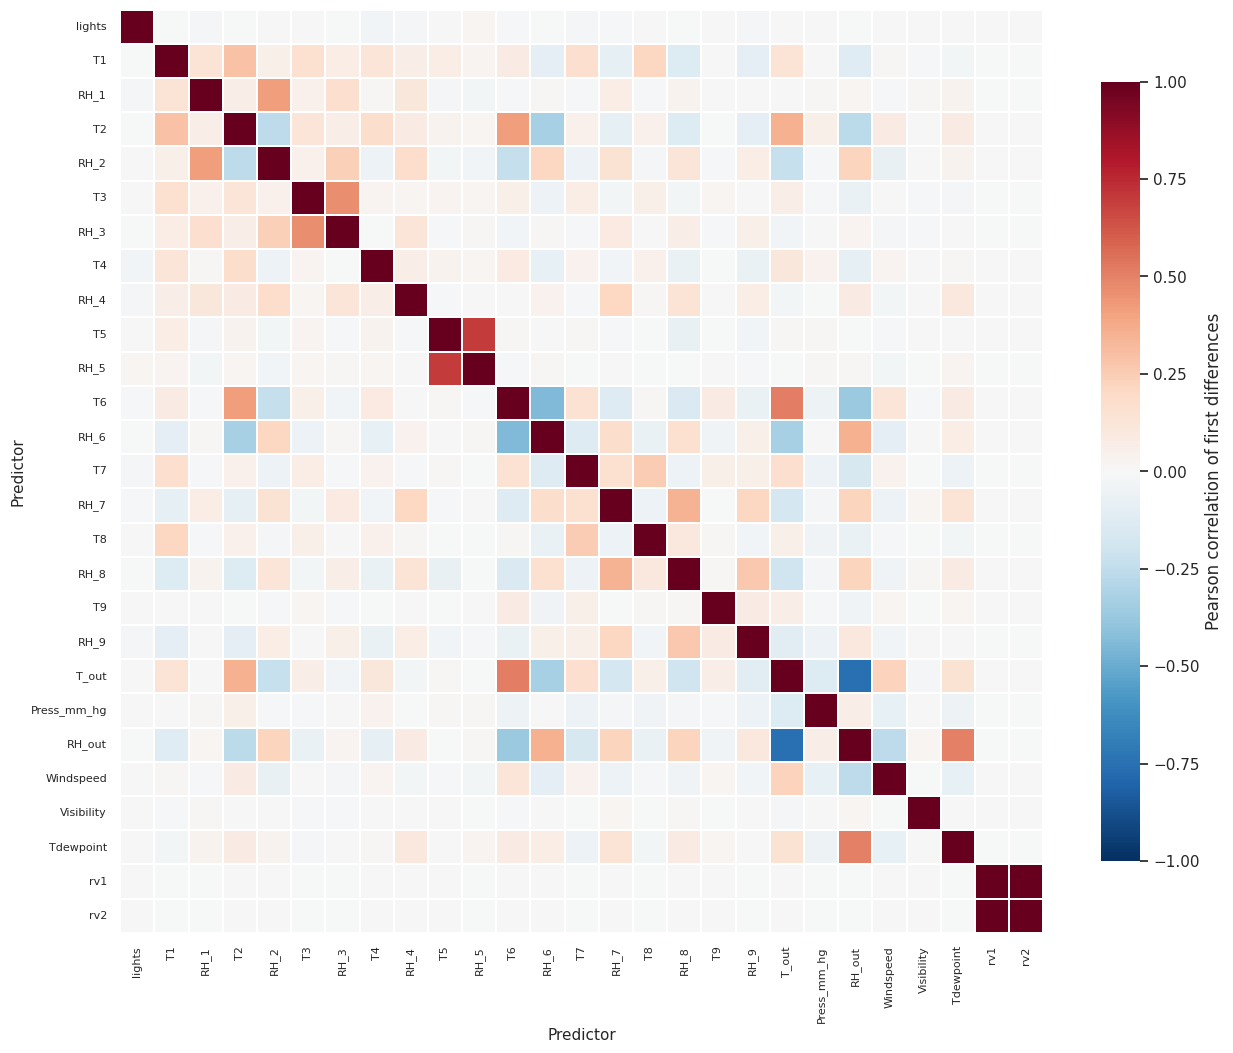


CORRELATION DIAGNOSTICS COMPLETED
All 27 predictors retained for EDA.
Correlation matrices and tables saved.
No feature selection performed.
No model preprocessing performed.


In [12]:

# ============================================================
# CELL 09 — PREDICTOR CORRELATION & REDUNDANCY
# ============================================================

from itertools import combinations

# ------------------------------------------------------------
# 1. Prepare predictors (descriptive EDA only)
# ------------------------------------------------------------

X_eda = df_raw[predictor_cols].copy()

assert len(predictor_cols) == 27, (
    "Unexpected number of original predictors."
)

print("=" * 60)
print("PREDICTOR CORRELATION & REDUNDANCY")
print("=" * 60)

print("Observations:", len(X_eda))
print("Predictors:", X_eda.shape[1])
print("No predictors removed.")

# ------------------------------------------------------------
# 2. Pearson and Spearman correlations
# ------------------------------------------------------------

pearson_corr = X_eda.corr(method="pearson")

spearman_corr = X_eda.corr(method="spearman")

# First differences for additional diagnostics.
# This is NOT a preprocessing transformation.

X_diff = X_eda.diff().dropna()

diff_corr = X_diff.corr(method="pearson")

# ------------------------------------------------------------
# 3. Pairwise correlation summary
# ------------------------------------------------------------

pair_records = []

for col_a, col_b in combinations(predictor_cols, 2):

    r_p = pearson_corr.loc[col_a, col_b]
    r_s = spearman_corr.loc[col_a, col_b]
    r_d = diff_corr.loc[col_a, col_b]

    pair_records.append({
        "predictor_1": col_a,
        "predictor_2": col_b,
        "pearson_r": r_p,
        "spearman_r": r_s,
        "first_difference_r": r_d,
        "abs_pearson": abs(r_p),
        "abs_spearman": abs(r_s)
    })

correlation_pairs = pd.DataFrame(pair_records)

correlation_pairs["max_abs_correlation"] = (
    correlation_pairs[
        ["abs_pearson", "abs_spearman"]
    ].max(axis=1)
)

correlation_pairs = correlation_pairs.sort_values(
    "max_abs_correlation",
    ascending=False
).reset_index(drop=True)

print("\nPAIRWISE CORRELATION SUMMARY")

print(
    "Total predictor pairs:",
    len(correlation_pairs)
)

# ------------------------------------------------------------
# 4. Strong correlation diagnostics
# ------------------------------------------------------------

CORRELATION_THRESHOLD = 0.90

strong_pairs = correlation_pairs.loc[
    correlation_pairs["max_abs_correlation"]
    >= CORRELATION_THRESHOLD
].copy()

print("\nSTRONG CORRELATION PAIRS")
print("Diagnostic threshold:", CORRELATION_THRESHOLD)
print("Number of flagged pairs:", len(strong_pairs))

display(
    strong_pairs[
        [
            "predictor_1",
            "predictor_2",
            "pearson_r",
            "spearman_r",
            "first_difference_r"
        ]
    ]
)

# ------------------------------------------------------------
# 5. Verify exact duplicate pair
# ------------------------------------------------------------

print("\nRV1–RV2 REDUNDANCY CHECK")

print(
    "Exact equality:",
    df_raw["rv1"].equals(df_raw["rv2"])
)

print(
    "Pearson correlation:",
    pearson_corr.loc["rv1", "rv2"]
)

print(
    "Spearman correlation:",
    spearman_corr.loc["rv1", "rv2"]
)

# ------------------------------------------------------------
# 6. Heatmap visualization function
# ------------------------------------------------------------

def save_correlation_heatmap(
    matrix,
    filename,
    colorbar_label
):

    fig, ax = plt.subplots(
        figsize=(13, 11)
    )

    sns.heatmap(
        matrix,
        cmap="RdBu_r",
        vmin=-1,
        vmax=1,
        center=0,
        annot=False,
        square=True,
        linewidths=0.25,
        linecolor="white",
        cbar_kws={
            "label": colorbar_label,
            "shrink": 0.80
        },
        ax=ax
    )

    # Axis labels
    ax.set_xlabel("Predictor", fontsize=11)
    ax.set_ylabel("Predictor", fontsize=11)

    # All predictor names remain visible
    ax.tick_params(
        axis="x",
        labelrotation=90,
        labelsize=8
    )

    ax.tick_params(
        axis="y",
        labelrotation=0,
        labelsize=8
    )

    plt.tight_layout()

    plt.savefig(
        PATHS["eda"] / filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

# ------------------------------------------------------------
# 7. Pearson correlation heatmap
# ------------------------------------------------------------

save_correlation_heatmap(
    pearson_corr,
    "13_pearson_predictor_heatmap.png",
    "Pearson correlation coefficient"
)

# ------------------------------------------------------------
# 8. Spearman correlation heatmap
# ------------------------------------------------------------

save_correlation_heatmap(
    spearman_corr,
    "14_spearman_predictor_heatmap.png",
    "Spearman rank correlation coefficient"
)

# ------------------------------------------------------------
# 9. First-difference correlation heatmap
# ------------------------------------------------------------

save_correlation_heatmap(
    diff_corr,
    "15_first_difference_correlation.png",
    "Pearson correlation of first differences"
)

# ------------------------------------------------------------
# 10. Save all results
# ------------------------------------------------------------

pearson_corr.to_csv(
    PATHS["eda"] / "11_pearson_correlation.csv"
)

spearman_corr.to_csv(
    PATHS["eda"] / "12_spearman_correlation.csv"
)

diff_corr.to_csv(
    PATHS["eda"] / "13_first_difference_correlation.csv"
)

correlation_pairs.to_csv(
    PATHS["eda"] / "14_all_predictor_pairs.csv",
    index=False
)

strong_pairs.to_csv(
    PATHS["eda"] / "15_strong_correlation_pairs.csv",
    index=False
)

print("\n" + "=" * 60)
print("CORRELATION DIAGNOSTICS COMPLETED")
print("=" * 60)

print("All 27 predictors retained for EDA.")
print("Correlation matrices and tables saved.")
print("No feature selection performed.")
print("No model preprocessing performed.")


## Multicollinearity Diagnostics

MULTICOLLINEARITY DIAGNOSTICS
Observations: 19735
Original predictors: 27

EXACT DUPLICATE PREDICTORS
{'rv2': 'rv1'}

VIF SUMMARY — ALL 27 PREDICTORS


,variable,auxiliary_r2,tolerance,vif,status
0,rv1,1.0000,0.0000,inf,Exact duplicate
1,rv2,1.0000,0.0000,inf,Exact duplicate
2,T_out,0.9932,0.0068,146.8437,High
3,Tdewpoint,0.9884,0.0116,86.1294,High
4,RH_out,0.9797,0.0203,49.2349,High
5,T6,0.9701,0.0299,33.4666,High
6,T2,0.9653,0.0347,28.8060,High
7,T9,0.9646,0.0354,28.2797,High
8,RH_2,0.9543,0.0457,21.8953,High
9,T1,0.9492,0.0508,19.6717,High



MULTICOLLINEARITY LEVEL SUMMARY


,category,count
0,Low (VIF < 5),5
1,Moderate (5 <= VIF < 10),5
2,"High (VIF >= 10, finite)",15
3,Infinite VIF,2


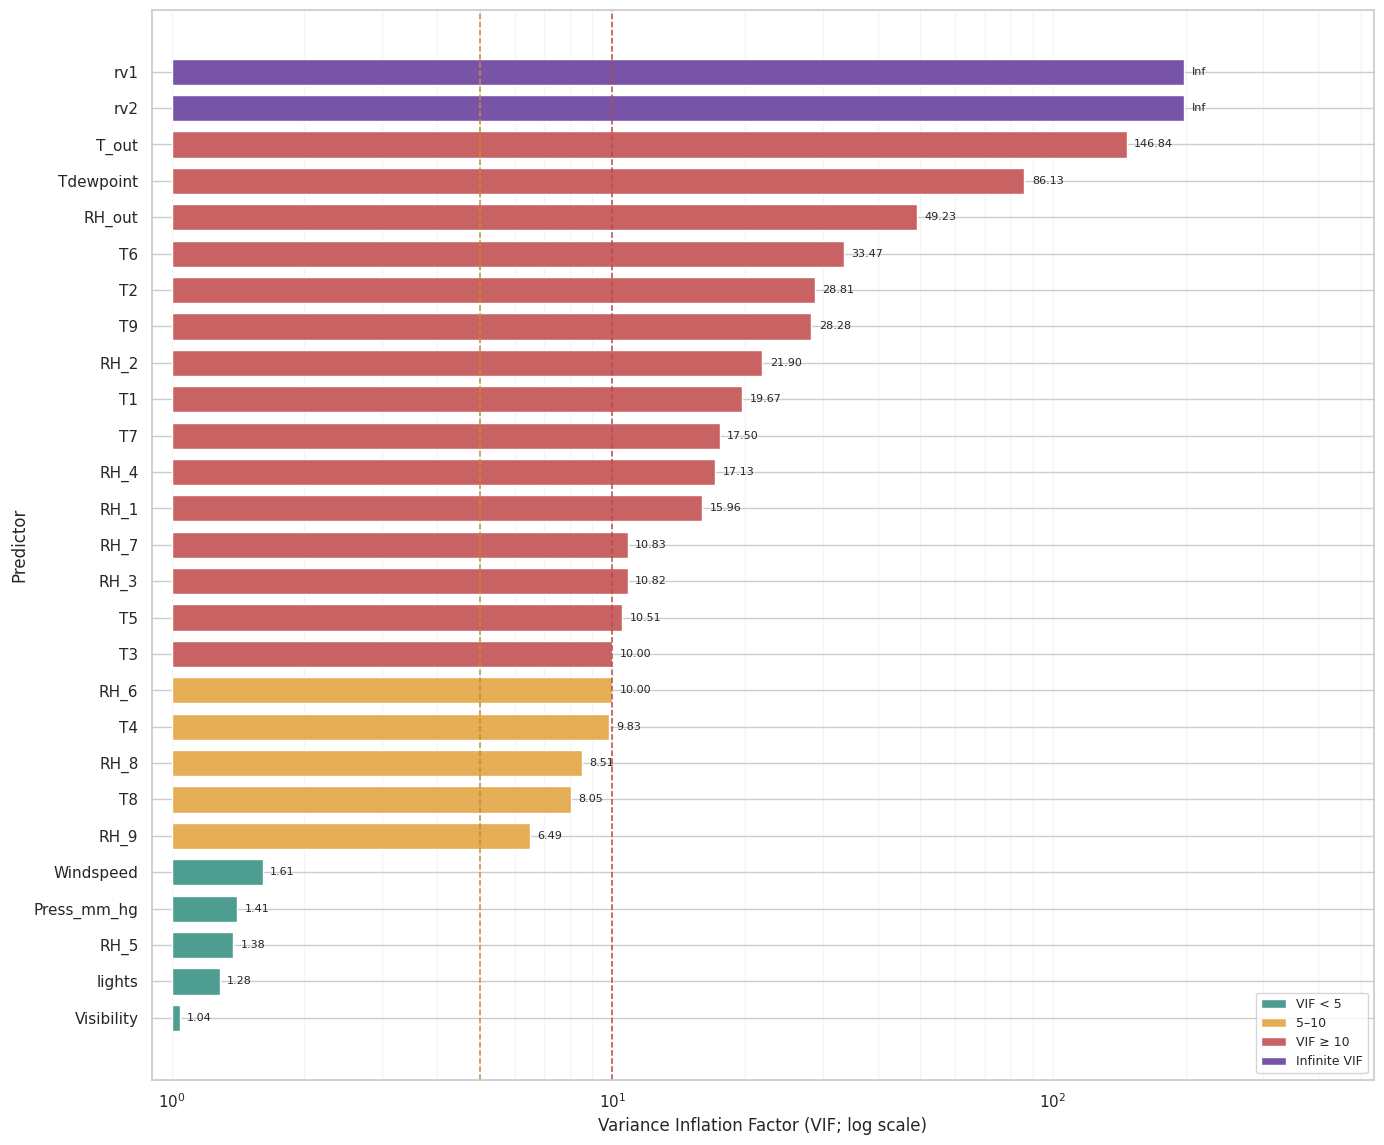

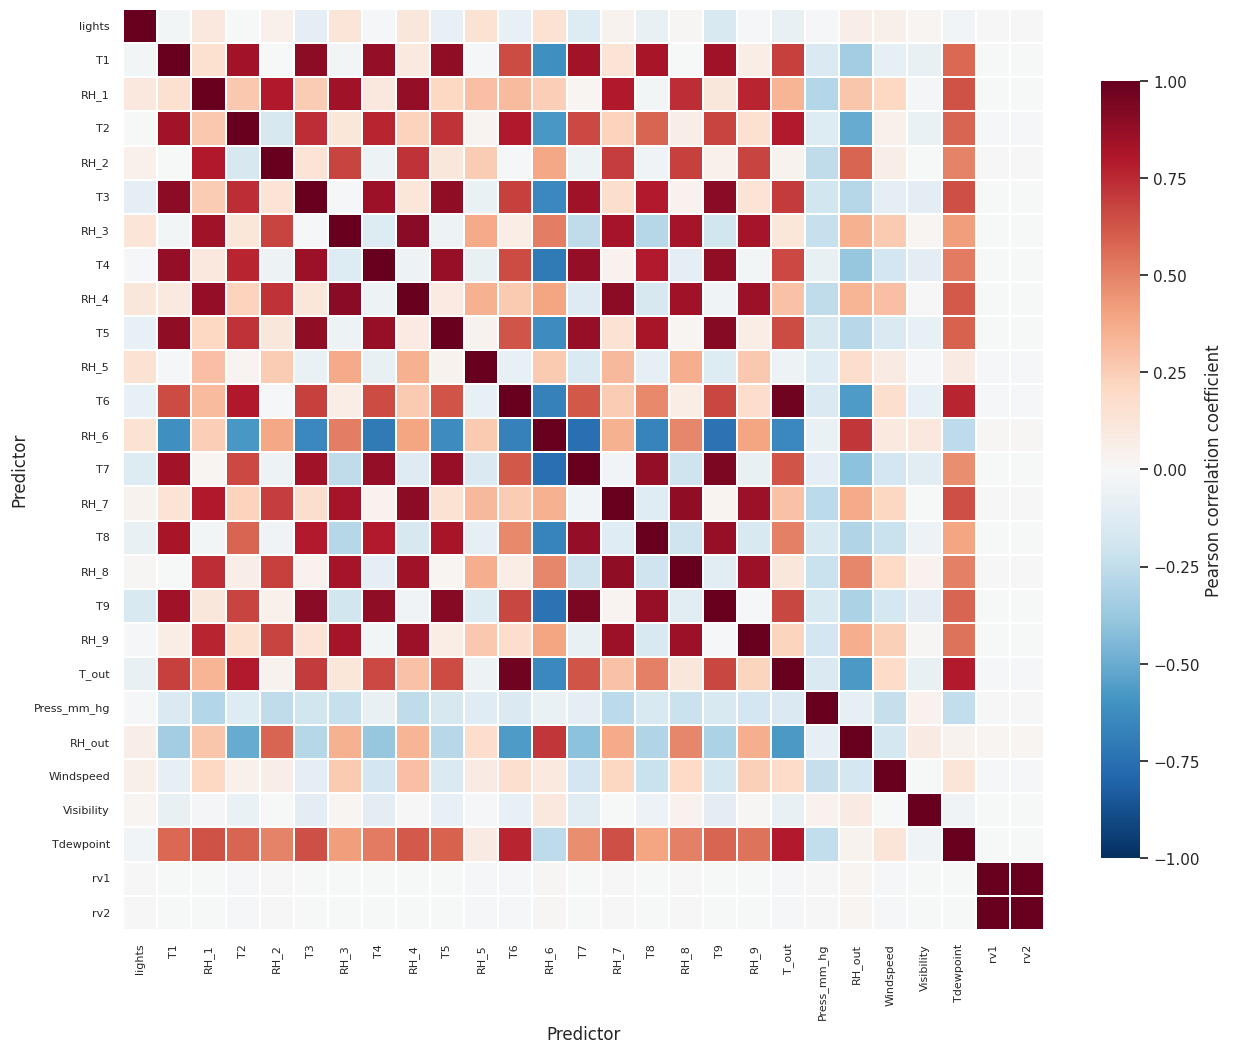


MULTICOLLINEARITY DIAGNOSTICS COMPLETED
Original predictors assessed: 27
Predictors used in numerical VIF: 26
Perfect duplicates: {'rv2': 'rv1'}

Results saved in 01_eda.
No feature selection performed.
Original dataframe remains unchanged.


In [13]:

# ============================================================
# CELL 09B — MULTICOLLINEARITY DIAGNOSTICS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from matplotlib.patches import Patch

# ------------------------------------------------------------
# 1. Prepare all original numerical predictors
# ------------------------------------------------------------

X_multi = df_raw.select_dtypes(
    include=[np.number]
).drop(columns=["Appliances"]).copy()

all_predictors = X_multi.columns.tolist()

assert len(all_predictors) == 27
assert X_multi.notna().all().all()
assert np.isfinite(X_multi.to_numpy()).all().all()

print("=" * 65)
print("MULTICOLLINEARITY DIAGNOSTICS")
print("=" * 65)
print("Observations:", len(X_multi))
print("Original predictors:", len(all_predictors))

# ------------------------------------------------------------
# 2. Detect exact duplicate predictors
# ------------------------------------------------------------

unique_cols = []
duplicate_map = {}

for col in all_predictors:

    identical_to = next(
        (
            existing for existing in unique_cols
            if X_multi[col].equals(X_multi[existing])
        ),
        None
    )

    if identical_to is None:
        unique_cols.append(col)
    else:
        duplicate_map[col] = identical_to

print("\nEXACT DUPLICATE PREDICTORS")
print(duplicate_map)

# Exclude one copy ONLY for numerical VIF calculation.
# Original predictors remain unchanged.

X_vif = X_multi[unique_cols].copy()

# ------------------------------------------------------------
# 3. Calculate VIF via auxiliary regressions
# ------------------------------------------------------------

# Internal standardization improves numerical conditioning.
# It is used ONLY for calculating VIF.
# No transformed dataset is saved or used for modeling.

X_array = X_vif.to_numpy(dtype=float)

mean_values = X_array.mean(axis=0)
std_values = X_array.std(axis=0, ddof=0)

if np.any(std_values == 0):
    raise ValueError("Constant predictor detected.")

Z = (X_array - mean_values) / std_values

vif_records = []

for j, col in enumerate(unique_cols):

    y_aux = Z[:, j]
    X_aux = np.delete(Z, j, axis=1)

    aux_model = LinearRegression()
    aux_model.fit(X_aux, y_aux)

    r_squared = float(aux_model.score(X_aux, y_aux))
    r_squared = min(max(r_squared, 0.0), 1.0)

    tolerance = 1.0 - r_squared

    vif_value = (
        np.inf if tolerance <= 1e-10
        else 1.0 / tolerance
    )

    vif_records.append({
        "variable": col,
        "auxiliary_r2": r_squared,
        "tolerance": tolerance,
        "vif": vif_value
    })

vif_unique = pd.DataFrame(vif_records)

# ------------------------------------------------------------
# 4. Restore full 27-variable diagnostic report
# ------------------------------------------------------------

# When both identical columns are retained, each member
# of the duplicate pair has infinite VIF.

duplicate_members = set(duplicate_map.keys())
duplicate_members.update(duplicate_map.values())

vif_lookup = vif_unique.set_index("variable")

full_records = []

for col in all_predictors:

    if col in duplicate_members:

        full_records.append({
            "variable": col,
            "auxiliary_r2": 1.0,
            "tolerance": 0.0,
            "vif": np.inf,
            "status": "Exact duplicate"
        })

    else:

        value = vif_lookup.loc[col, "vif"]

        if not np.isfinite(value):
            status = "Perfect/near-perfect dependency"
        elif value >= 10:
            status = "High"
        elif value >= 5:
            status = "Moderate"
        else:
            status = "Low"

        full_records.append({
            "variable": col,
            "auxiliary_r2": float(
                vif_lookup.loc[col, "auxiliary_r2"]
            ),
            "tolerance": float(
                vif_lookup.loc[col, "tolerance"]
            ),
            "vif": float(value),
            "status": status
        })

vif_summary = pd.DataFrame(full_records)

vif_summary = vif_summary.sort_values(
    "vif",
    ascending=False,
    kind="stable"
).reset_index(drop=True)

print("\nVIF SUMMARY — ALL 27 PREDICTORS")
display(vif_summary)

# ------------------------------------------------------------
# 5. Summarize multicollinearity levels
# ------------------------------------------------------------

vif_values = vif_summary["vif"]

vif_counts = pd.DataFrame({
    "category": [
        "Low (VIF < 5)",
        "Moderate (5 <= VIF < 10)",
        "High (VIF >= 10, finite)",
        "Infinite VIF"
    ],
    "count": [
        int((vif_values < 5).sum()),
        int((
            (vif_values >= 5) &
            (vif_values < 10)
        ).sum()),
        int((
            (vif_values >= 10) &
            np.isfinite(vif_values)
        ).sum()),
        int(np.isinf(vif_values).sum())
    ]
})

print("\nMULTICOLLINEARITY LEVEL SUMMARY")
display(vif_counts)

# ------------------------------------------------------------
# 6. Visualization — horizontal VIF barplot
# ------------------------------------------------------------

finite_values = vif_values[
    np.isfinite(vif_values)
]

max_finite = max(
    10.0,
    float(finite_values.max())
)

# Position for infinite values is only for display.
# Their actual VIF remains infinity in the saved table.
inf_plot_position = max_finite * 1.35

plot_values = vif_values.replace(
    np.inf, inf_plot_position
).to_numpy(dtype=float)

colors = []

for v in vif_values:

    if np.isinf(v):
        colors.append("#7854A8")
    elif v >= 10:
        colors.append("#C96363")
    elif v >= 5:
        colors.append("#E5AD55")
    else:
        colors.append("#4D9D91")

fig, ax = plt.subplots(
    figsize=(14, max(9, len(vif_summary) * 0.43))
)

y_pos = np.arange(len(vif_summary))

ax.barh(
    y_pos,
    plot_values - 1,
    left=1,
    color=colors,
    edgecolor="white",
    height=0.72
)

ax.set_yticks(y_pos)
ax.set_yticklabels(vif_summary["variable"])
ax.invert_yaxis()

# Reference thresholds
ax.axvline(
    5, color="#C58C30",
    linestyle="--", linewidth=1.1
)

ax.axvline(
    10, color="#B74B4B",
    linestyle="--", linewidth=1.1
)

# Log scale improves readability for widely varying VIFs
ax.set_xscale("log")
ax.set_xlim(0.9, inf_plot_position * 2.7)

ax.set_xlabel("Variance Inflation Factor (VIF; log scale)")
ax.set_ylabel("Predictor")

# Annotate exact values
for i, (actual, displayed) in enumerate(
    zip(vif_values, plot_values)
):

    label = (
        "Inf" if np.isinf(actual)
        else f"{actual:.2f}"
    )

    ax.text(
        displayed * 1.04,
        i,
        label,
        va="center",
        fontsize=8
    )

legend_items = [
    Patch(facecolor="#4D9D91", label="VIF < 5"),
    Patch(facecolor="#E5AD55", label="5–10"),
    Patch(facecolor="#C96363", label="VIF ≥ 10"),
    Patch(facecolor="#7854A8", label="Infinite VIF")
]

ax.legend(
    handles=legend_items,
    loc="lower right",
    fontsize=9
)

ax.grid(
    axis="x",
    alpha=0.2,
    which="both"
)

ax.set_axisbelow(True)

plt.tight_layout()

vif_figure_path = (
    PATHS["eda"] / "16_vif_all_predictors.png"
)

plt.savefig(
    vif_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 7. Correlation heatmap — all original predictors
# ------------------------------------------------------------

corr_matrix = X_multi.corr(method="pearson")

fig, ax = plt.subplots(figsize=(13, 11))

sns.heatmap(
    corr_matrix,
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.25,
    annot=False,
    cbar_kws={
        "label": "Pearson correlation coefficient",
        "shrink": 0.8
    },
    ax=ax
)

ax.set_xlabel("Predictor")
ax.set_ylabel("Predictor")

ax.tick_params(
    axis="x", labelrotation=90, labelsize=8
)

ax.tick_params(
    axis="y", labelrotation=0, labelsize=8
)

plt.tight_layout()

corr_figure_path = (
    PATHS["eda"] / "17_multicollinearity_correlation.png"
)

plt.savefig(
    corr_figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 8. Save diagnostic results
# ------------------------------------------------------------

vif_summary.to_csv(
    PATHS["eda"] / "16_vif_all_predictors.csv",
    index=False
)

vif_unique.to_csv(
    PATHS["eda"] / "17_vif_numerically_unique.csv",
    index=False
)

vif_counts.to_csv(
    PATHS["eda"] / "18_vif_category_summary.csv",
    index=False
)

print("\n" + "=" * 65)
print("MULTICOLLINEARITY DIAGNOSTICS COMPLETED")
print("=" * 65)

print("Original predictors assessed:", len(all_predictors))
print("Predictors used in numerical VIF:", len(unique_cols))
print("Perfect duplicates:", duplicate_map)

print("\nResults saved in 01_eda.")
print("No feature selection performed.")
print("Original dataframe remains unchanged.")


## Feature Engineering & Feature Selection Specification

In [14]:

# ============================================================
# CELL 10 — FEATURE ENGINEERING & FEATURE SET SPECIFICATION
# ============================================================

import json
import numpy as np
import pandas as pd

from IPython.display import display

# ------------------------------------------------------------
# 1. Define original variables
# ------------------------------------------------------------

TARGET = "Appliances"
TIMESTAMP = "date"

original_predictors = [
    col for col in df_raw.columns
    if col not in [TARGET, TIMESTAMP]
]

# Random control attributes identified during diagnostics
excluded_structural = ["rv1", "rv2"]

physical_predictors = [
    col for col in original_predictors
    if col not in excluded_structural
]

assert len(original_predictors) == 27
assert len(physical_predictors) == 25

# Verify exact duplicate finding
assert df_raw["rv1"].equals(df_raw["rv2"])

print("=" * 65)
print("FEATURE SPECIFICATION")
print("=" * 65)

print("Original predictors:", len(original_predictors))
print("Structural exclusions:", excluded_structural)
print("Remaining measured predictors:", len(physical_predictors))

# ------------------------------------------------------------
# 2. Create deterministic daily cyclic features
# ------------------------------------------------------------

def create_daily_cyclic_features(data):

    result = data.copy()

    timestamps = pd.to_datetime(
        result[TIMESTAMP],
        errors="raise"
    )

    minutes_since_midnight = (
        timestamps.dt.hour * 60
        + timestamps.dt.minute
        + timestamps.dt.second / 60
    )

    daily_angle = (
        2 * np.pi * minutes_since_midnight / 1440
    )

    result["time_sin"] = np.sin(daily_angle)
    result["time_cos"] = np.cos(daily_angle)

    return result


# Create engineering copy
df_engineered = create_daily_cyclic_features(df_raw)

engineered_features = [
    "time_sin",
    "time_cos"
]

# ------------------------------------------------------------
# 3. Verify engineered features
# ------------------------------------------------------------

assert df_engineered[engineered_features].notna().all().all()

# Sine and cosine must lie between -1 and 1
assert (
    df_engineered[engineered_features]
    .abs()
    .le(1.000001)
    .all()
    .all()
)

# Verify circular representation
circle_identity = (
    df_engineered["time_sin"] ** 2
    + df_engineered["time_cos"] ** 2
)

assert np.allclose(circle_identity, 1.0, atol=1e-10)

# Original dataset must remain unchanged
assert df_raw.shape[1] == 29

print("\nENGINEERED FEATURE VALIDATION")
print("Missing values: 0")
print("Sine/cosine range: valid")
print("Circular identity: valid")
print("Original dataset: unchanged")

# ------------------------------------------------------------
# 4. Define two candidate feature sets
# ------------------------------------------------------------

FEATURE_SET_A = physical_predictors.copy()

FEATURE_SET_B = (
    physical_predictors
    + engineered_features
)

assert len(FEATURE_SET_A) == 25
assert len(FEATURE_SET_B) == 27

assert len(FEATURE_SET_A) == len(set(FEATURE_SET_A))
assert len(FEATURE_SET_B) == len(set(FEATURE_SET_B))

# Include timestamp for future chronological partitioning
# Include target for future training-only evaluation

df_features_A = df_engineered[
    [TIMESTAMP] + FEATURE_SET_A + [TARGET]
].copy()

df_features_B = df_engineered[
    [TIMESTAMP] + FEATURE_SET_B + [TARGET]
].copy()

# ------------------------------------------------------------
# 5. Verify temporal and target consistency
# ------------------------------------------------------------

date_A = pd.to_datetime(df_features_A[TIMESTAMP])
date_B = pd.to_datetime(df_features_B[TIMESTAMP])

assert date_A.equals(date_B)
assert date_A.is_monotonic_increasing
assert date_A.is_unique

assert df_features_A[TARGET].equals(
    df_features_B[TARGET]
)

assert len(df_features_A) == len(df_raw)
assert len(df_features_B) == len(df_raw)

assert df_features_A.isna().sum().sum() == 0
assert df_features_B.isna().sum().sum() == 0

print("\nCANDIDATE FEATURE SETS")

feature_comparison = pd.DataFrame([
    {
        "specification": "A",
        "description": "Original measured predictors",
        "n_predictors": len(FEATURE_SET_A),
        "n_observations": len(df_features_A),
        "status": "Baseline"
    },
    {
        "specification": "B",
        "description": "Original + daily cyclic features",
        "n_predictors": len(FEATURE_SET_B),
        "n_observations": len(df_features_B),
        "status": "Candidate"
    }
])

display(feature_comparison)

# ------------------------------------------------------------
# 6. Inspect engineered feature values
# ------------------------------------------------------------

print("\nDAILY CYCLIC FEATURE EXAMPLES")

display(
    df_engineered[
        [TIMESTAMP] + engineered_features
    ].iloc[
        np.linspace(
            0,
            len(df_engineered) - 1,
            10,
            dtype=int
        )
    ]
)

print("\nDAILY CYCLIC FEATURE DESCRIPTIVES")

display(
    df_engineered[
        engineered_features
    ].describe().T
)

# ------------------------------------------------------------
# 7. Define feature selection decision register
# ------------------------------------------------------------

feature_decisions = pd.DataFrame([
    {
        "component": "Structural filtering",
        "decision": "Exclude rv1 and rv2",
        "basis": "Random controls and exact duplication"
    },
    {
        "component": "Correlation filtering",
        "decision": "Not applied",
        "basis": "Correlation alone does not establish predictive redundancy"
    },
    {
        "component": "VIF filtering",
        "decision": "Not applied",
        "basis": "High VIF does not justify automatic removal for the six ML models"
    },
    {
        "component": "Daily cyclic features",
        "decision": "Evaluate time_sin and time_cos",
        "basis": "Daily consumption pattern and ACF diagnostics"
    },
    {
        "component": "Thermal difference features",
        "decision": "Not included",
        "basis": "No established incremental predictive benefit"
    },
    {
        "component": "Model-based feature selection",
        "decision": "Conditional",
        "basis": "Only if training diagnostics justify reduction"
    },
    {
        "component": "Final feature specification",
        "decision": "Pending training-only CV",
        "basis": "Compare candidate feature sets A and B"
    }
])

print("\nFEATURE DECISION REGISTER")
display(feature_decisions)

# ------------------------------------------------------------
# 8. Save candidate datasets
# ------------------------------------------------------------

path_A = (
    PATHS["processed"] /
    "candidate_feature_set_A.csv"
)

path_B = (
    PATHS["processed"] /
    "candidate_feature_set_B.csv"
)

df_features_A.to_csv(
    path_A,
    index=False
)

df_features_B.to_csv(
    path_B,
    index=False
)

# ------------------------------------------------------------
# 9. Save metadata and decision register
# ------------------------------------------------------------

feature_metadata = {
    "project": "Stability-Driven Appliance Energy Evaluation",
    "stage": "Candidate feature specification",
    "target": TARGET,
    "timestamp": TIMESTAMP,

    "original_predictors": original_predictors,
    "structural_exclusions": excluded_structural,

    "feature_set_A": FEATURE_SET_A,
    "feature_set_B": FEATURE_SET_B,

    "engineered_features": engineered_features,

    "engineering_method": {
        "time_sin": "sin(2*pi*minute_of_day/1440)",
        "time_cos": "cos(2*pi*minute_of_day/1440)"
    },

    "candidate_A_n_features": len(FEATURE_SET_A),
    "candidate_B_n_features": len(FEATURE_SET_B),

    "final_feature_set_selected": False,
    "model_based_selection_performed": False,
    "train_validation_test_split_performed": False,
    "model_training_performed": False
}

metadata_path = (
    PATHS["metadata"] /
    "notebook01_feature_specification.json"
)

with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        feature_metadata,
        f,
        indent=4
    )

feature_comparison.to_csv(
    PATHS["eda"] /
    "16_candidate_feature_comparison.csv",
    index=False
)

feature_decisions.to_csv(
    PATHS["eda"] /
    "17_feature_selection_decisions.csv",
    index=False
)

# ------------------------------------------------------------
# 10. Final audit
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("CELL 10 COMPLETED")
print("=" * 65)

print("Candidate A:", df_features_A.shape)
print("Candidate B:", df_features_B.shape)

print("\nSaved files:")
print("-", path_A.name)
print("-", path_B.name)
print("-", metadata_path.name)

print("\nNo model training performed.")
print("No target-based feature selection performed.")
print("No feature set selected yet.")
print("Original dataset preserved.")


FEATURE SPECIFICATION
Original predictors: 27
Structural exclusions: ['rv1', 'rv2']
Remaining measured predictors: 25

ENGINEERED FEATURE VALIDATION
Missing values: 0
Sine/cosine range: valid
Circular identity: valid
Original dataset: unchanged

CANDIDATE FEATURE SETS


,specification,description,n_predictors,n_observations,status
0,A,Original measured predictors,25,19735,Baseline
1,B,Original + daily cyclic features,27,19735,Candidate



DAILY CYCLIC FEATURE EXAMPLES


,date,time_sin,time_cos
0,2016-01-11 17:00:00,-0.9659,-0.2588
2192,2016-01-26 22:20:00,-0.4226,0.9063
4385,2016-02-11 03:50:00,0.8434,0.5373
6578,2016-02-26 09:20:00,0.6428,-0.7660
8770,2016-03-12 14:40:00,-0.6428,-0.7660
10963,2016-03-27 20:10:00,-0.8434,0.5373
13156,2016-04-12 01:40:00,0.4226,0.9063
15348,2016-04-27 07:00:00,0.9659,-0.2588
17541,2016-05-12 12:30:00,-0.1305,-0.9914
19734,2016-05-27 18:00:00,-1.0000,-0.0000



DAILY CYCLIC FEATURE DESCRIPTIVES


,count,mean,std,min,25%,50%,75%,max
time_sin,19735.0000,-0.0004,0.7072,-1.0000,-0.7071,0.0000,0.7071,1.0000
time_cos,19735.0000,-0.0000,0.7070,-1.0000,-0.7071,-0.0000,0.7071,1.0000



FEATURE DECISION REGISTER


,component,decision,basis
0,Structural filtering,Exclude rv1 and rv2,Random controls and exact duplication
1,Correlation filtering,Not applied,Correlation alone does not establish predictiv...
2,VIF filtering,Not applied,High VIF does not justify automatic removal fo...
3,Daily cyclic features,Evaluate time_sin and time_cos,Daily consumption pattern and ACF diagnostics
4,Thermal difference features,Not included,No established incremental predictive benefit
5,Model-based feature selection,Conditional,Only if training diagnostics justify reduction
6,Final feature specification,Pending training-only CV,Compare candidate feature sets A and B



CELL 10 COMPLETED
Candidate A: (19735, 27)
Candidate B: (19735, 29)

Saved files:
- candidate_feature_set_A.csv
- candidate_feature_set_B.csv
- notebook01_feature_specification.json

No model training performed.
No target-based feature selection performed.
No feature set selected yet.
Original dataset preserved.


## Candidate Dataset Integrity & Reproducibility

In [15]:

# ============================================================
# CELL 11 — CANDIDATE DATASET INTEGRITY AUDIT
# ============================================================

import hashlib
import json
import numpy as np
import pandas as pd

from datetime import datetime, timezone

# ------------------------------------------------------------
# 1. Reload candidate datasets from persistent storage
# ------------------------------------------------------------

path_A = PATHS["processed"] / "candidate_feature_set_A.csv"
path_B = PATHS["processed"] / "candidate_feature_set_B.csv"

assert path_A.is_file(), "Candidate A file not found."
assert path_B.is_file(), "Candidate B file not found."

check_A = pd.read_csv(path_A, parse_dates=["date"])
check_B = pd.read_csv(path_B, parse_dates=["date"])

# ------------------------------------------------------------
# 2. Structural and temporal validation
# ------------------------------------------------------------

assert check_A.shape == (19735, 27)
assert check_B.shape == (19735, 29)

assert check_A.columns.tolist() == (
    ["date"] + FEATURE_SET_A + ["Appliances"]
)

assert check_B.columns.tolist() == (
    ["date"] + FEATURE_SET_B + ["Appliances"]
)

assert check_A["date"].equals(check_B["date"])
assert check_A["date"].is_monotonic_increasing
assert check_A["date"].is_unique

assert check_A["Appliances"].equals(
    check_B["Appliances"]
)

assert check_A.isna().sum().sum() == 0
assert check_B.isna().sum().sum() == 0

# ------------------------------------------------------------
# 3. Feature set consistency
# ------------------------------------------------------------

assert set(FEATURE_SET_B) - set(FEATURE_SET_A) == {
    "time_sin", "time_cos"
}

assert "rv1" not in check_A.columns
assert "rv2" not in check_A.columns
assert "rv1" not in check_B.columns
assert "rv2" not in check_B.columns

# Verify that original measured predictors are identical
assert np.allclose(
    check_A[FEATURE_SET_A].to_numpy(dtype=float),
    check_B[FEATURE_SET_A].to_numpy(dtype=float),
    rtol=1e-10,
    atol=1e-10
)

# Validate saved cyclic representation
cyclic_identity = (
    check_B["time_sin"] ** 2 +
    check_B["time_cos"] ** 2
)

assert np.allclose(
    cyclic_identity, 1.0, atol=1e-10
)

# ------------------------------------------------------------
# 4. Dataset checksums
# ------------------------------------------------------------

def calculate_sha256(file_path):
    hash_obj = hashlib.sha256()

    with open(file_path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            hash_obj.update(chunk)

    return hash_obj.hexdigest()

# ------------------------------------------------------------
# 5. Create reproducibility report
# ------------------------------------------------------------

integrity_report = {
    "audit_time_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "candidate_A": {
        "file": path_A.name,
        "rows": len(check_A),
        "predictors": len(FEATURE_SET_A),
        "sha256": calculate_sha256(path_A)
    },

    "candidate_B": {
        "file": path_B.name,
        "rows": len(check_B),
        "predictors": len(FEATURE_SET_B),
        "sha256": calculate_sha256(path_B)
    },

    "timestamp_aligned": True,
    "target_aligned": True,
    "cyclic_features_valid": True,
    "random_controls_excluded": True,

    "final_feature_set_selected": False,
    "chronological_split_performed": False,
    "model_training_performed": False
}

report_path = (
    PATHS["metadata"] /
    "notebook01_dataset_integrity.json"
)

with open(report_path, "w", encoding="utf-8") as f:
    json.dump(integrity_report, f, indent=4)

print("=" * 60)
print("CANDIDATE DATASET INTEGRITY AUDIT")
print("=" * 60)

print("Candidate A:", check_A.shape)
print("Candidate B:", check_B.shape)
print("Timestamp alignment: PASS")
print("Target alignment: PASS")
print("Feature consistency: PASS")
print("Cyclic feature validation: PASS")
print("Missing-value validation: PASS")
print("Structural exclusions: PASS")

print("\nIntegrity report saved:")
print(report_path)


CANDIDATE DATASET INTEGRITY AUDIT
Candidate A: (19735, 27)
Candidate B: (19735, 29)
Timestamp alignment: PASS
Target alignment: PASS
Feature consistency: PASS
Cyclic feature validation: PASS
Missing-value validation: PASS
Structural exclusions: PASS

Integrity report saved:
/content/drive/MyDrive/Stability_Driven_Energy/09_experiment_metadata/notebook01_dataset_integrity.json


## Freeze Preparation Protocol

In [16]:

# ============================================================
# CELL 12 — NOTEBOOK 01 FINAL CHECKPOINT
# ============================================================

import json

preparation_protocol = {
    "project": "Stability-Driven Appliance Energy Evaluation",
    "notebook": "01_Data_Exploration_and_Preparation",

    "target": "Appliances",
    "target_unit": "Wh",

    "task_definition": (
        "Contemporaneous appliance energy estimation"
    ),

    "data_quality": {
        "missing_values": 0,
        "timestamp_gaps": 0,
        "duplicate_rows": 0,
        "outlier_removal": False
    },

    "feature_engineering": {
        "original_measured_predictors": 25,
        "candidate_engineered_features": [
            "time_sin",
            "time_cos"
        ],
        "thermal_difference_features": False,
        "target_lag_features": False
    },

    "feature_selection": {
        "structural_exclusions": [
            "rv1",
            "rv2"
        ],
        "correlation_threshold_filtering": False,
        "vif_threshold_filtering": False,
        "model_based_selection": "Conditional",
        "selected_feature_set": None
    },

    "candidate_feature_sets": {
        "A": FEATURE_SET_A,
        "B": FEATURE_SET_B
    },

    "model_development_protocol": {
        "data_partition": "Chronological",
        "split_proportions": None,
        "feature_set_comparison": (
            "Training-only expanding-window CV"
        ),
        "hyperparameter_optimization": "Grid Search",
        "optimization_metric": "RMSE",
        "test_set_for_selection": False
    },

    "bootstrap_protocol": {
        "methods": [
            "IID",
            "Moving Block",
            "Stationary"
        ],
        "replications": [30, 100, 300],
        "optional_replications": 500,
        "block_length": None
    },

    "experiment_status": {
        "eda_completed": True,
        "candidate_features_prepared": True,
        "feature_set_selected": False,
        "temporal_split_completed": False,
        "tuning_completed": False,
        "bootstrap_completed": False,
        "final_test_completed": False
    }
}

protocol_path = (
    PATHS["metadata"] /
    "notebook01_preparation_protocol.json"
)

with open(protocol_path, "w", encoding="utf-8") as f:
    json.dump(
        preparation_protocol,
        f,
        indent=4
    )

print("=" * 60)
print("NOTEBOOK 01 — FINAL CHECKPOINT")
print("=" * 60)

print("EDA completed: YES")
print("Feature candidates prepared: YES")
print("Final feature set selected: NO")
print("Chronological split performed: NO")
print("Model training performed: NO")

print("\nProtocol saved:")
print(protocol_path)

print("\nNotebook 01 checkpoint completed.")


NOTEBOOK 01 — FINAL CHECKPOINT
EDA completed: YES
Feature candidates prepared: YES
Final feature set selected: NO
Chronological split performed: NO
Model training performed: NO

Protocol saved:
/content/drive/MyDrive/Stability_Driven_Energy/09_experiment_metadata/notebook01_preparation_protocol.json

Notebook 01 checkpoint completed.


# Distribution & Transformation Diagnostics

CELL 10A — DISTRIBUTION & TRANSFORMATION DIAGNOSTICS
Observations: 19735
Numerical variables: 28
Target variables: 1
Original predictors: 27
No data modification performed.

A. DISTRIBUTION STATISTICS — ALL VARIABLES


,variable,role,mean,median,std,skewness,excess_kurtosis,zero_pct,iqr_zero,iqr_flag_pct
0,Appliances,Target,97.6950,60.0000,102.5249,3.3864,13.6679,0.0000,False,10.8335
1,lights,Predictor,3.8019,0.0000,7.9360,2.1952,4.4621,77.2840,True,22.7160
2,T1,Predictor,21.6866,21.6000,1.6061,0.1209,0.1616,0.0000,False,2.6096
3,RH_1,Predictor,40.2597,39.6567,3.9793,0.4658,0.1126,0.0000,False,0.7398
4,T2,Predictor,20.3412,20.0000,2.1930,0.8897,0.9334,0.0000,False,2.7667
5,RH_2,Predictor,40.4204,40.5000,4.0698,-0.2682,0.6710,0.0000,False,1.1908
6,T3,Predictor,22.2676,22.1000,2.0061,0.4508,-0.0071,0.0000,False,1.0996
7,RH_3,Predictor,39.2425,38.5300,3.2546,0.4676,-0.5831,0.0000,False,0.0760
8,T4,Predictor,20.8553,20.6667,2.0429,0.1704,-0.0376,0.0000,False,0.9425
9,RH_4,Predictor,39.0269,38.4000,4.3413,0.4446,-0.6140,0.0000,False,0.0000



B. DISTRIBUTION SCREENING — ALL VARIABLES


,variable,positive_skew_flag,negative_skew_flag,zero_concentration_flag,zero_iqr_flag,log1p_diagnostic_eligible,screening_status
0,Appliances,True,False,False,False,True,Log1p diagnostic
1,lights,True,False,True,True,True,Log1p diagnostic
2,T1,False,False,False,False,False,Original only
3,RH_1,False,False,False,False,False,Original only
4,T2,False,False,False,False,False,Original only
5,RH_2,False,False,False,False,False,Original only
6,T3,False,False,False,False,False,Original only
7,RH_3,False,False,False,False,False,Original only
8,T4,False,False,False,False,False,Original only
9,RH_4,False,False,False,False,False,Original only



C. LOG1P DIAGNOSTIC CANDIDATES
['Appliances', 'lights', 'RH_5']
Number of candidates: 3

D. ORIGINAL VS LOG1P — DIAGNOSTIC COMPARISON


,variable,transformation,original_skewness,original_kurtosis,original_iqr_flag_pct,original_zero_pct,transformed_skewness,transformed_kurtosis,transformed_iqr_flag_pct,skewness_abs_reduction
0,Appliances,log1p,3.3864,13.6679,10.8335,0.0000,1.1903,1.5881,6.4961,2.1961
1,lights,log1p,2.1952,4.4621,22.7160,77.2840,1.4027,0.1289,22.7160,0.7925
2,T1,Not evaluated,0.1209,0.1616,2.6096,0.0000,NaN,NaN,NaN,NaN
3,RH_1,Not evaluated,0.4658,0.1126,0.7398,0.0000,NaN,NaN,NaN,NaN
4,T2,Not evaluated,0.8897,0.9334,2.7667,0.0000,NaN,NaN,NaN,NaN
5,RH_2,Not evaluated,-0.2682,0.6710,1.1908,0.0000,NaN,NaN,NaN,NaN
6,T3,Not evaluated,0.4508,-0.0071,1.0996,0.0000,NaN,NaN,NaN,NaN
7,RH_3,Not evaluated,0.4676,-0.5831,0.0760,0.0000,NaN,NaN,NaN,NaN
8,T4,Not evaluated,0.1704,-0.0376,0.9425,0.0000,NaN,NaN,NaN,NaN
9,RH_4,Not evaluated,0.4446,-0.6140,0.0000,0.0000,NaN,NaN,NaN,NaN


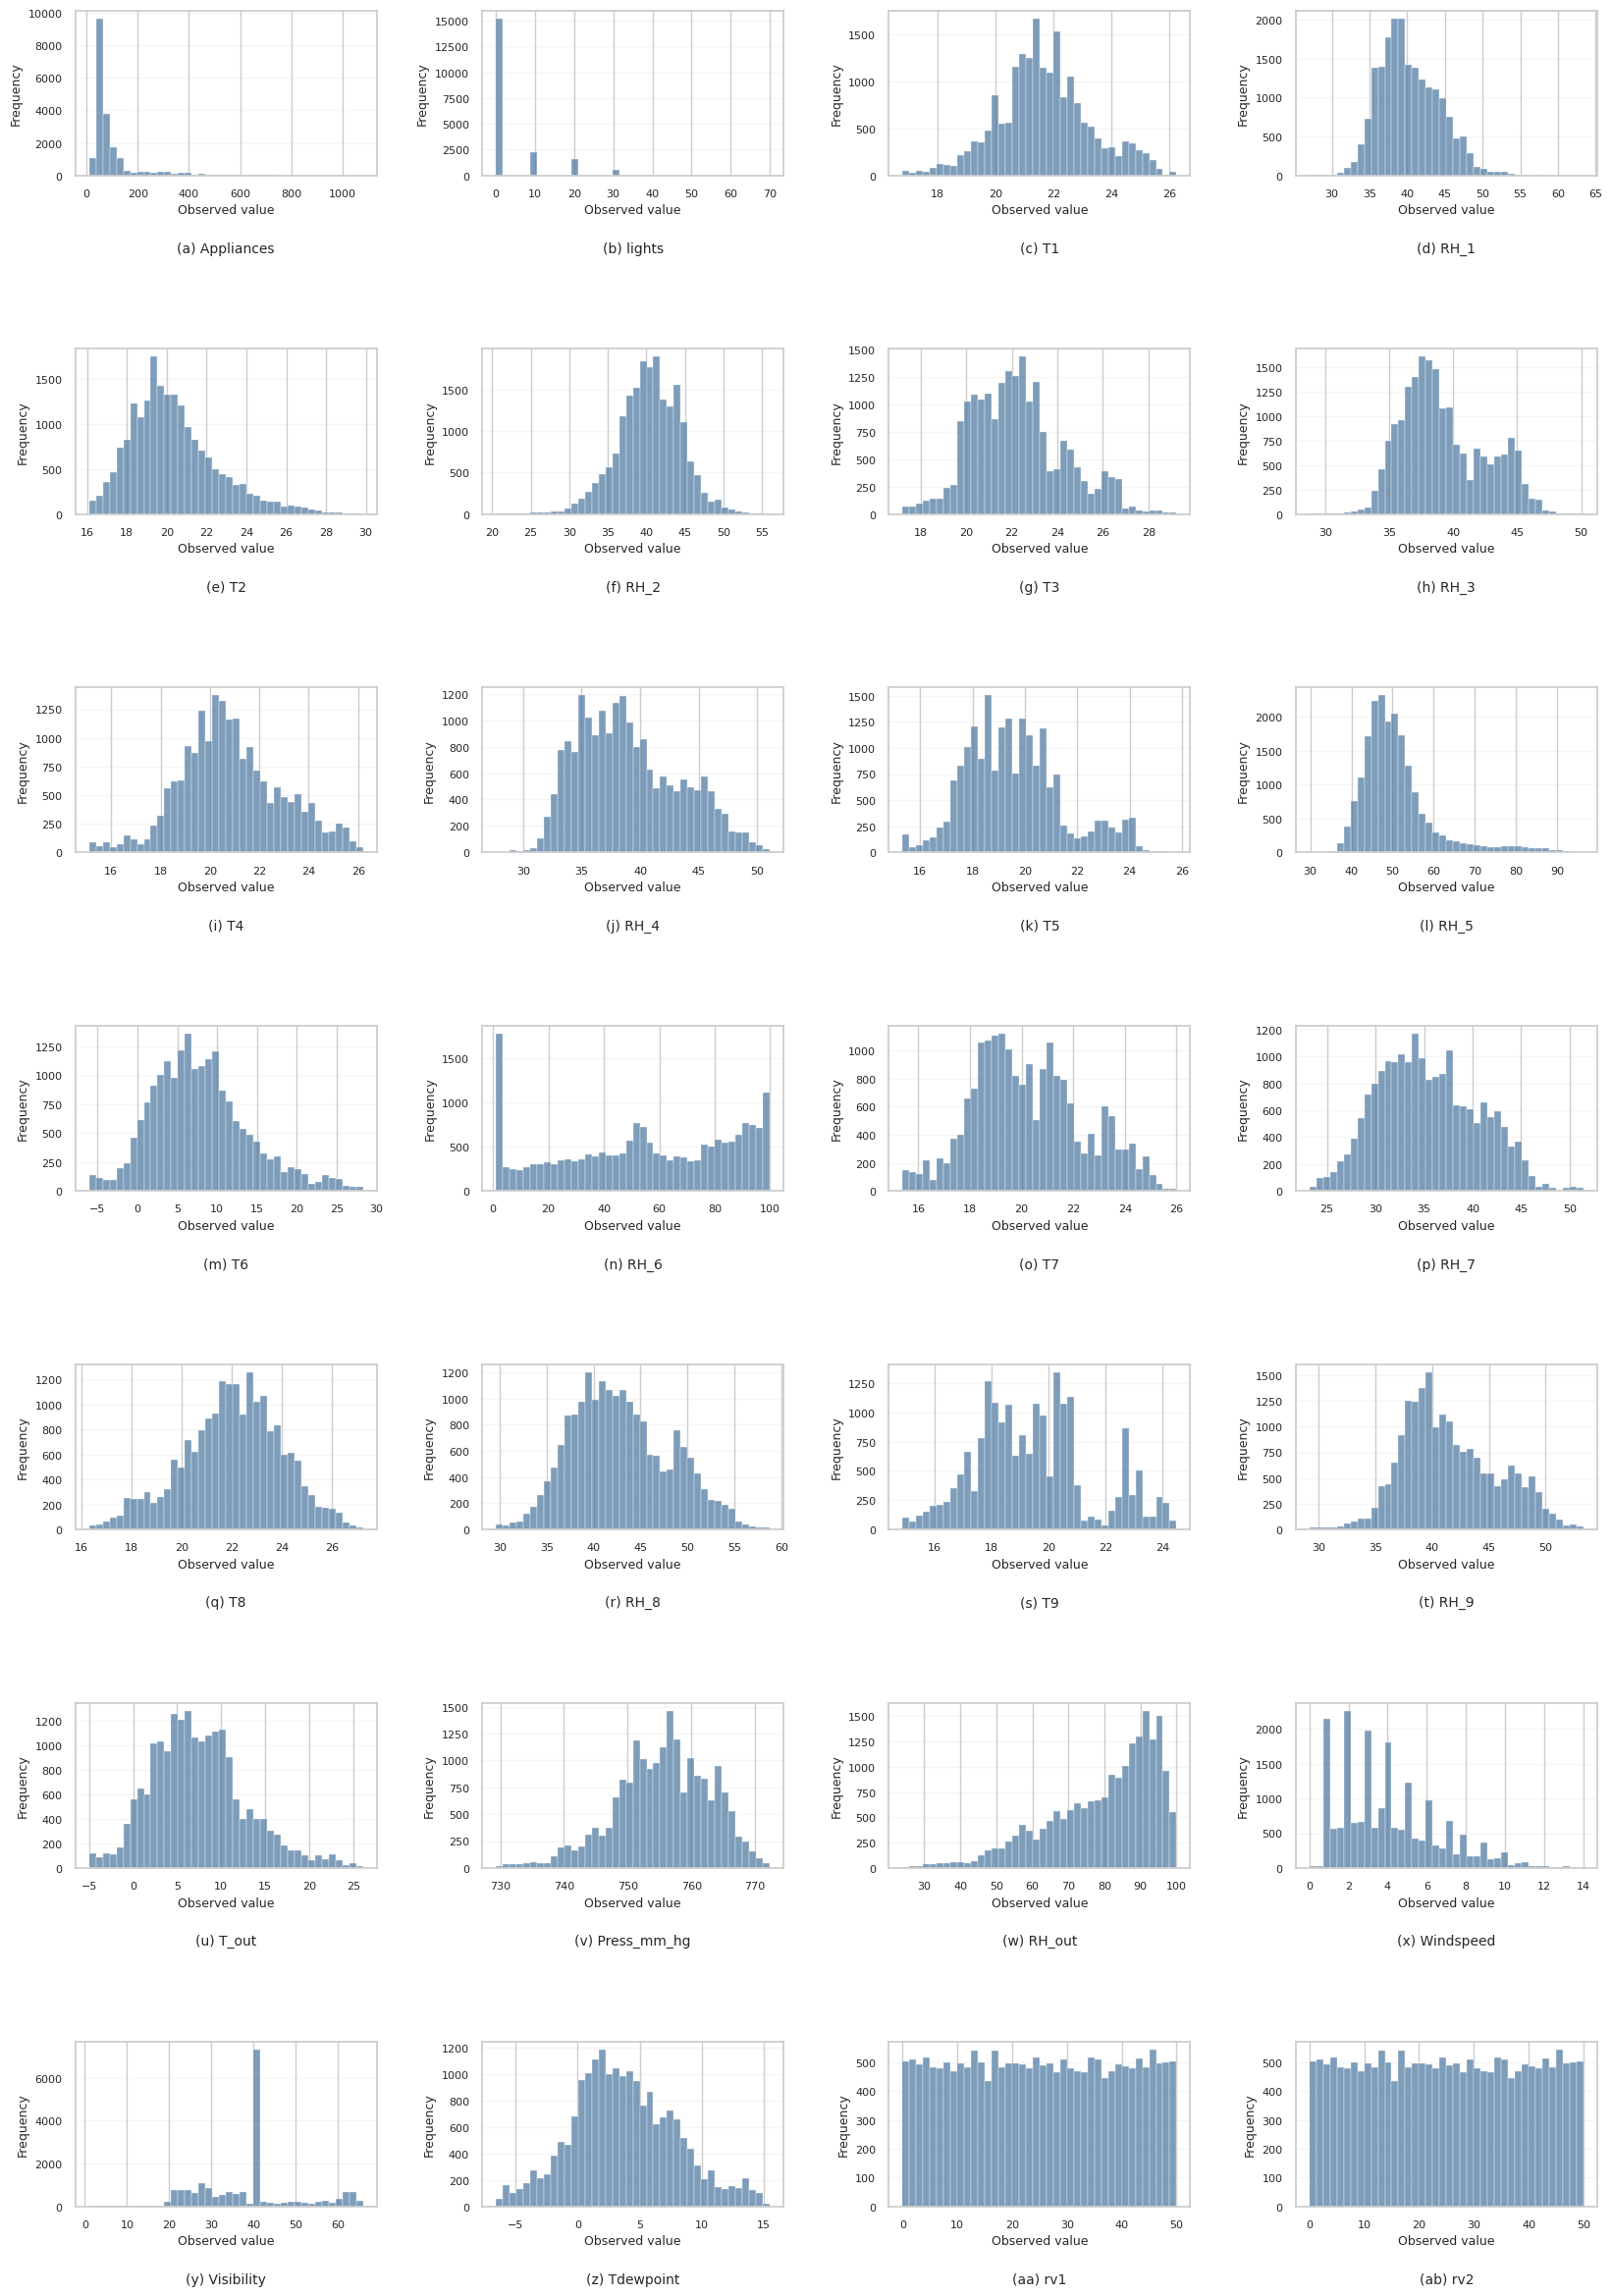

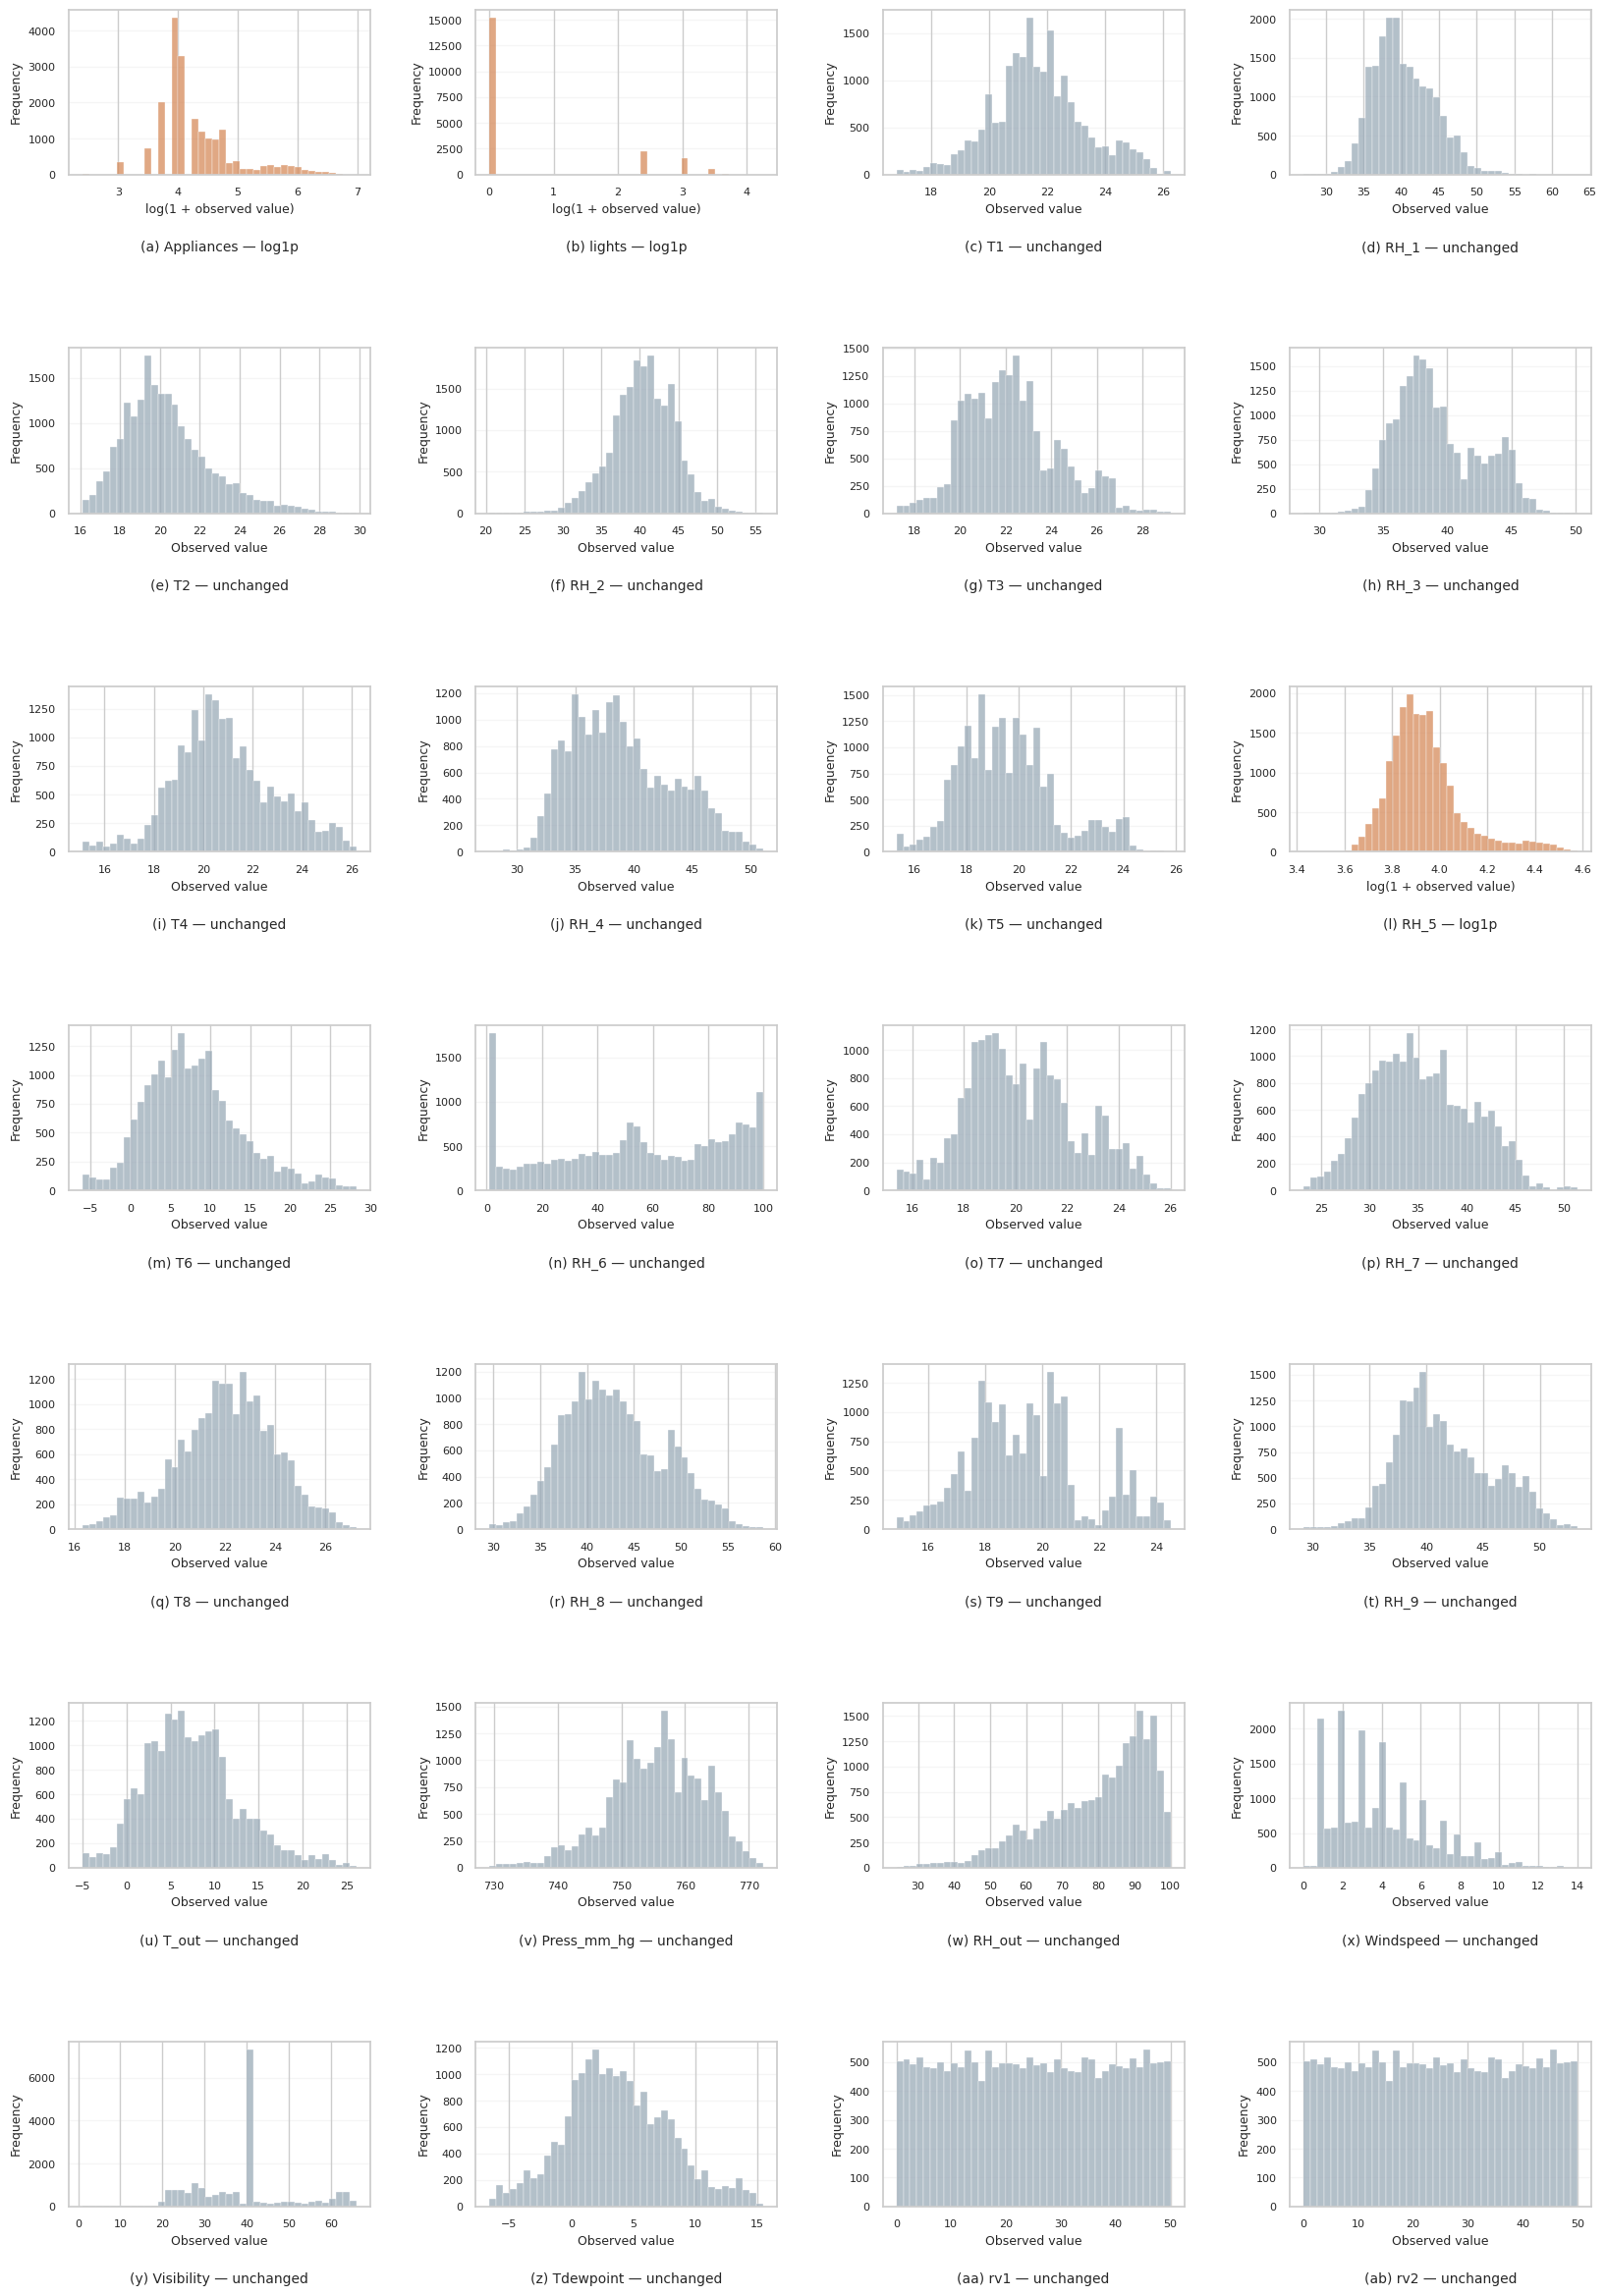

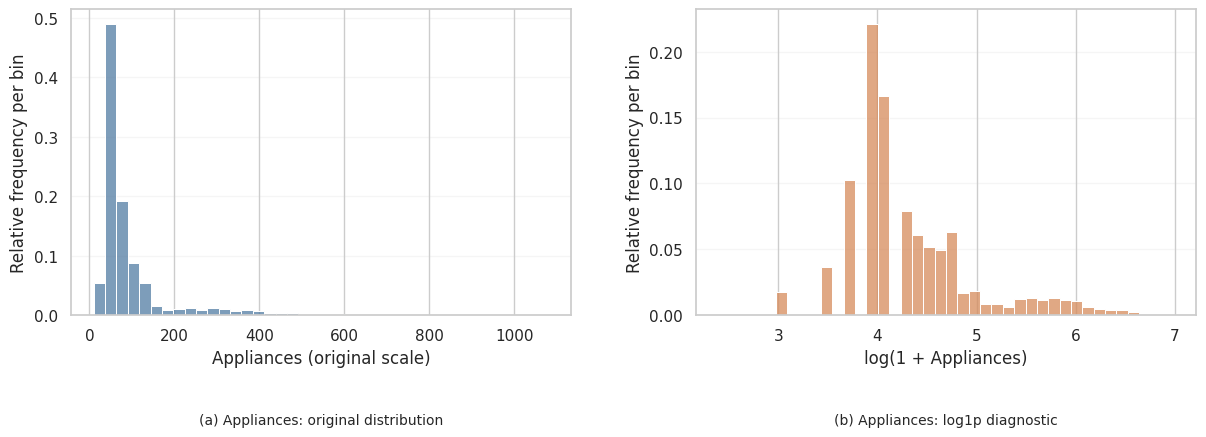

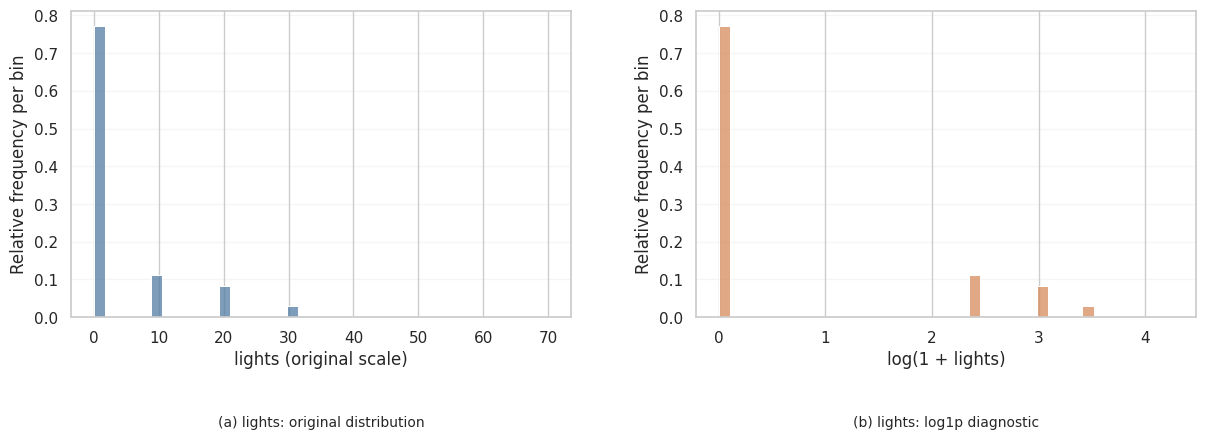

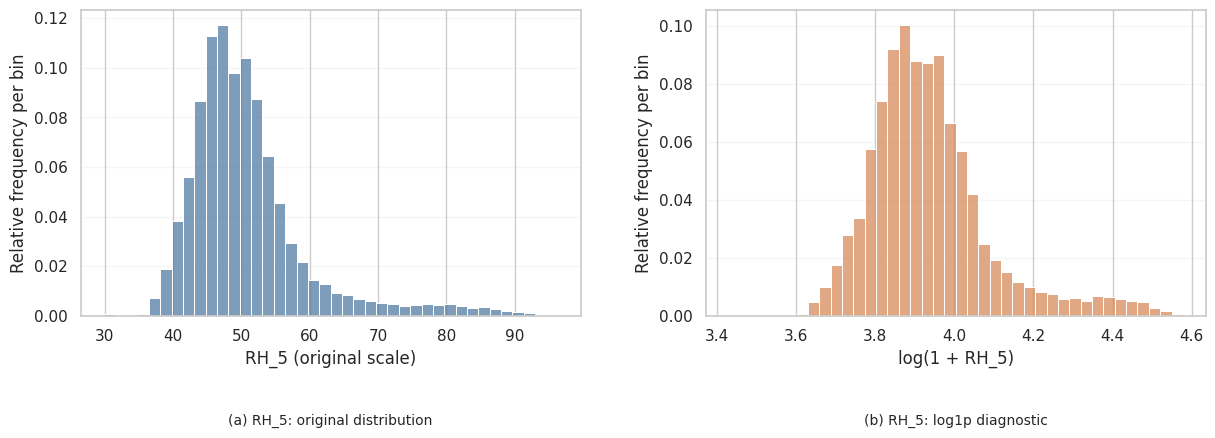


CELL 10A — COMPLETED
All original numerical variables audited: 28
Log1p diagnostic candidates: 3

Variables evaluated:
['Appliances', 'lights', 'RH_5']

Saved figures:
- 10A_01_original_distributions.png
- 10A_02_diagnostic_distributions.png
- 3 individual comparison figures

Saved tables:
- 10A_original_distribution_statistics.csv
- 10A_distribution_screening.csv
- 10A_transformation_comparison.csv

Metadata:
- notebook01_transformation_diagnostics.json

Original dataframe unchanged.
Candidate Feature Sets A and B unchanged.
No final transformations selected.
No model training performed.


In [17]:

# ============================================================
# CELL 10A — DISTRIBUTION & TRANSFORMATION DIAGNOSTICS
# Stability-Driven Appliance Energy Evaluation
# ============================================================

import json
import math
import string
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# ------------------------------------------------------------
# 1. Configuration and data validation
# ------------------------------------------------------------

OUTDIR = PATHS["eda"]
OUTDIR.mkdir(parents=True, exist_ok=True)

TARGET = "Appliances"

# Audit all original numeric columns:
# 1 target + 27 original predictors.
# Engineered time features are audited separately in Cell 10.
df_dist = df_raw.select_dtypes(
    include=[np.number]
).copy()

variables = df_dist.columns.tolist()

assert TARGET in variables
assert len(variables) == 28
assert len(df_dist) == len(df_raw)
assert df_dist.notna().all().all()
assert np.isfinite(df_dist.to_numpy(dtype=float)).all().all()

print("=" * 70)
print("CELL 10A — DISTRIBUTION & TRANSFORMATION DIAGNOSTICS")
print("=" * 70)

print("Observations:", len(df_dist))
print("Numerical variables:", len(variables))
print("Target variables: 1")
print("Original predictors: 27")
print("No data modification performed.")

# ------------------------------------------------------------
# 2. Descriptive distribution statistics
# ------------------------------------------------------------

def distribution_stats(series):

    s = pd.Series(series, dtype=float)

    q1 = float(s.quantile(0.25))
    q3 = float(s.quantile(0.75))
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    iqr_flags = (s < lower) | (s > upper)

    return {
        "n": int(s.notna().sum()),
        "mean": float(s.mean()),
        "median": float(s.median()),
        "std": float(s.std()),
        "min": float(s.min()),
        "q1": q1,
        "q3": q3,
        "max": float(s.max()),
        "skewness": float(s.skew()),
        "excess_kurtosis": float(s.kurt()),
        "zero_pct": float((s == 0).mean() * 100),
        "negative_pct": float((s < 0).mean() * 100),
        "iqr": float(iqr),
        "iqr_zero": bool(np.isclose(iqr, 0.0)),
        "iqr_flag_pct": float(iqr_flags.mean() * 100)
    }


raw_records = []

for col in variables:
    stats = distribution_stats(df_dist[col])

    raw_records.append({
        "variable": col,
        "role": "Target" if col == TARGET else "Predictor",
        **stats
    })

raw_stats = pd.DataFrame(raw_records)

print("\nA. DISTRIBUTION STATISTICS — ALL VARIABLES")

display(
    raw_stats[[
        "variable",
        "role",
        "mean",
        "median",
        "std",
        "skewness",
        "excess_kurtosis",
        "zero_pct",
        "iqr_zero",
        "iqr_flag_pct"
    ]].round(4)
)

# ------------------------------------------------------------
# 3. Diagnostic screening
# ------------------------------------------------------------

# Screening threshold is descriptive, not a final
# rule for choosing preprocessing.
SKEW_SCREEN_THRESHOLD = 1.0

screening_records = []

for _, row in raw_stats.iterrows():

    col = row["variable"]

    positive_skew = (
        row["skewness"] >= SKEW_SCREEN_THRESHOLD
    )

    negative_skew = (
        row["skewness"] <= -SKEW_SCREEN_THRESHOLD
    )

    nonnegative = row["min"] >= 0

    zero_concentrated = row["zero_pct"] >= 50

    # A log1p demonstration is mathematically permitted
    # only for nonnegative values.
    #
    # This is NOT automatic preprocessing selection.
    log1p_diagnostic = (
        nonnegative and (
            positive_skew or col == TARGET
        )
    )

    screening_records.append({
        "variable": col,
        "positive_skew_flag": bool(positive_skew),
        "negative_skew_flag": bool(negative_skew),
        "zero_concentration_flag": bool(zero_concentrated),
        "zero_iqr_flag": bool(row["iqr_zero"]),
        "log1p_diagnostic_eligible": bool(
            log1p_diagnostic
        ),
        "screening_status": (
            "Log1p diagnostic"
            if log1p_diagnostic
            else "Original only"
        )
    })

screening_table = pd.DataFrame(screening_records)

print("\nB. DISTRIBUTION SCREENING — ALL VARIABLES")
display(screening_table)

# ------------------------------------------------------------
# 4. Generate exploratory log1p transformations
# ------------------------------------------------------------

# IMPORTANT:
# This dictionary is for visual/statistical diagnostics.
# It will NOT overwrite the original datasets.
# No transformer is fitted on the full dataset.

diagnostic_transforms = {}

eligible_variables = screening_table.loc[
    screening_table["log1p_diagnostic_eligible"],
    "variable"
].tolist()

for col in eligible_variables:

    s = df_dist[col].astype(float)

    if (s < 0).any():
        raise ValueError(
            f"Cannot apply log1p to negative values: {col}"
        )

    diagnostic_transforms[col] = np.log1p(s)

print("\nC. LOG1P DIAGNOSTIC CANDIDATES")
print(eligible_variables)
print("Number of candidates:", len(eligible_variables))

# ------------------------------------------------------------
# 5. Compare original and diagnostic transformations
# ------------------------------------------------------------

comparison_records = []

for col in variables:

    original = distribution_stats(df_dist[col])

    record = {
        "variable": col,
        "transformation": (
            "log1p" if col in diagnostic_transforms
            else "Not evaluated"
        ),
        "original_skewness": original["skewness"],
        "original_kurtosis": original["excess_kurtosis"],
        "original_iqr_flag_pct": original["iqr_flag_pct"],
        "original_zero_pct": original["zero_pct"],
        "transformed_skewness": np.nan,
        "transformed_kurtosis": np.nan,
        "transformed_iqr_flag_pct": np.nan,
        "skewness_abs_reduction": np.nan
    }

    if col in diagnostic_transforms:

        transformed = distribution_stats(
            diagnostic_transforms[col]
        )

        record["transformed_skewness"] = (
            transformed["skewness"]
        )

        record["transformed_kurtosis"] = (
            transformed["excess_kurtosis"]
        )

        record["transformed_iqr_flag_pct"] = (
            transformed["iqr_flag_pct"]
        )

        record["skewness_abs_reduction"] = (
            abs(original["skewness"])
            - abs(transformed["skewness"])
        )

    comparison_records.append(record)

transformation_comparison = pd.DataFrame(
    comparison_records
)

print("\nD. ORIGINAL VS LOG1P — DIAGNOSTIC COMPARISON")

display(
    transformation_comparison.round(4)
)

# ------------------------------------------------------------
# 6. Helper for panel labels
# ------------------------------------------------------------

def panel_letter(index):

    letters = ""
    n = int(index)

    while True:
        letters = (
            string.ascii_lowercase[n % 26] + letters
        )
        n = n // 26 - 1

        if n < 0:
            break

    return letters

# ------------------------------------------------------------
# 7. Visualization 1 — all original distributions
# ------------------------------------------------------------

ncols = 4
nrows = math.ceil(len(variables) / ncols)

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(20, nrows * 3.4)
)

axes = np.asarray(axes).ravel()

for i, col in enumerate(variables):

    ax = axes[i]

    sns.histplot(
        data=df_dist,
        x=col,
        bins=40,
        stat="count",
        color="#527CA3",
        edgecolor="white",
        linewidth=0.25,
        ax=ax
    )

    ax.set_xlabel("Observed value", fontsize=9)
    ax.set_ylabel("Frequency", fontsize=9)

    ax.tick_params(axis="both", labelsize=8)

    ax.text(
        0.5, -0.40,
        f"({panel_letter(i)}) {col}",
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=10
    )

    ax.grid(axis="y", alpha=0.18)
    ax.set_axisbelow(True)

for j in range(len(variables), len(axes)):
    axes[j].set_visible(False)

fig.subplots_adjust(
    hspace=1.05,
    wspace=0.35,
    top=0.985,
    bottom=0.045
)

raw_fig_path = (
    OUTDIR / "10A_01_original_distributions.png"
)

fig.savefig(
    raw_fig_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 8. Visualization 2 — diagnostic representations
# ------------------------------------------------------------

# Same variable order as Visualization 1.
# Eligible variables show exploratory log1p values.
# Other variables remain on the original scale.

fig, axes = plt.subplots(
    nrows,
    ncols,
    figsize=(20, nrows * 3.4)
)

axes = np.asarray(axes).ravel()

for i, col in enumerate(variables):

    ax = axes[i]

    is_transformed = col in diagnostic_transforms

    series = (
        diagnostic_transforms[col]
        if is_transformed
        else df_dist[col]
    )

    color = (
        "#D68B5B"
        if is_transformed
        else "#9AABB8"
    )

    sns.histplot(
        x=series,
        bins=40,
        stat="count",
        color=color,
        edgecolor="white",
        linewidth=0.25,
        ax=ax
    )

    ax.set_xlabel(
        "log(1 + observed value)"
        if is_transformed
        else "Observed value",
        fontsize=9
    )

    ax.set_ylabel("Frequency", fontsize=9)

    ax.tick_params(axis="both", labelsize=8)

    caption = (
        f"({panel_letter(i)}) {col} — log1p"
        if is_transformed
        else f"({panel_letter(i)}) {col} — unchanged"
    )

    ax.text(
        0.5, -0.40,
        caption,
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=10
    )

    ax.grid(axis="y", alpha=0.18)
    ax.set_axisbelow(True)

for j in range(len(variables), len(axes)):
    axes[j].set_visible(False)

fig.subplots_adjust(
    hspace=1.05,
    wspace=0.35,
    top=0.985,
    bottom=0.045
)

diagnostic_fig_path = (
    OUTDIR / "10A_02_diagnostic_distributions.png"
)

fig.savefig(
    diagnostic_fig_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 9. Visualization 3 — individual before/after comparisons
# ------------------------------------------------------------

# Each eligible variable gets a separate figure.
# No main title. Labels (a) and (b) appear below panels.

individual_figure_paths = []

for col in eligible_variables:

    original = df_dist[col].astype(float)

    transformed = diagnostic_transforms[col]

    fig, axes = plt.subplots(
        1, 2,
        figsize=(12.5, 4.5)
    )

    sns.histplot(
        x=original,
        bins=40,
        stat="probability",
        color="#527CA3",
        edgecolor="white",
        ax=axes[0]
    )

    sns.histplot(
        x=transformed,
        bins=40,
        stat="probability",
        color="#D68B5B",
        edgecolor="white",
        ax=axes[1]
    )

    axes[0].set_xlabel(
        f"{col} (original scale)"
    )

    axes[1].set_xlabel(
        f"log(1 + {col})"
    )

    for ax in axes:
        ax.set_ylabel(
            "Relative frequency per bin"
        )
        ax.grid(axis="y", alpha=0.18)
        ax.set_axisbelow(True)

    axes[0].text(
        0.5, -0.32,
        f"(a) {col}: original distribution",
        transform=axes[0].transAxes,
        ha="center",
        va="top",
        fontsize=10
    )

    axes[1].text(
        0.5, -0.32,
        f"(b) {col}: log1p diagnostic",
        transform=axes[1].transAxes,
        ha="center",
        va="top",
        fontsize=10
    )

    fig.subplots_adjust(
        left=0.08,
        right=0.98,
        top=0.96,
        bottom=0.28,
        wspace=0.25
    )

    fig_path = (
        OUTDIR /
        f"10A_03_comparison_{col}.png"
    )

    fig.savefig(
        fig_path,
        dpi=300,
        bbox_inches="tight"
    )

    individual_figure_paths.append(
        str(fig_path)
    )

    plt.show()
    plt.close(fig)

# ------------------------------------------------------------
# 10. Save audit tables
# ------------------------------------------------------------

raw_stats.to_csv(
    OUTDIR / "10A_original_distribution_statistics.csv",
    index=False
)

screening_table.to_csv(
    OUTDIR / "10A_distribution_screening.csv",
    index=False
)

transformation_comparison.to_csv(
    OUTDIR / "10A_transformation_comparison.csv",
    index=False
)

# ------------------------------------------------------------
# 11. Save diagnostic metadata
# ------------------------------------------------------------

diagnostic_metadata = {
    "cell": "10A",
    "stage": "Exploratory transformation diagnostics",
    "n_observations": int(len(df_dist)),
    "n_numeric_variables": int(len(variables)),
    "variables": variables,
    "screening_skewness_threshold": (
        SKEW_SCREEN_THRESHOLD
    ),
    "screening_rule": (
        "Positive skewness >= 1 and nonnegative "
        "observed values; target included"
    ),
    "diagnostic_transformation": "log1p",
    "evaluated_variables": eligible_variables,
    "transformations_are_exploratory": True,
    "transformed_datasets_saved": False,
    "feature_sets_modified": False,
    "final_transformations_selected": False,
    "scaling_applied": False,
    "outliers_removed": False,
    "model_training_performed": False,
    "next_stage": (
        "Extreme-value and temporal-distribution audit"
    )
}

metadata_path = (
    PATHS["metadata"] /
    "notebook01_transformation_diagnostics.json"
)

with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        diagnostic_metadata,
        f,
        indent=4
    )

# ------------------------------------------------------------
# 12. Final validation and summary
# ------------------------------------------------------------

assert len(raw_stats) == 28
assert len(screening_table) == 28
assert len(transformation_comparison) == 28

assert df_raw.shape[1] == 29

assert df_raw["rv1"].equals(df_raw["rv2"])

print("\n" + "=" * 70)
print("CELL 10A — COMPLETED")
print("=" * 70)

print("All original numerical variables audited:", 28)
print("Log1p diagnostic candidates:", len(eligible_variables))

print("\nVariables evaluated:")
print(eligible_variables)

print("\nSaved figures:")
print("-", raw_fig_path.name)
print("-", diagnostic_fig_path.name)
print("-", len(individual_figure_paths),
      "individual comparison figures")

print("\nSaved tables:")
print("- 10A_original_distribution_statistics.csv")
print("- 10A_distribution_screening.csv")
print("- 10A_transformation_comparison.csv")

print("\nMetadata:")
print("-", metadata_path.name)

print("\nOriginal dataframe unchanged.")
print("Candidate Feature Sets A and B unchanged.")
print("No final transformations selected.")
print("No model training performed.")


# Extreme Value & Temporal Distribution Audit

CELL 10B — EXTREME VALUE & TEMPORAL DISTRIBUTION
Observations: 19735
Numerical variables: 28
First timestamp: 2016-01-11 17:00:00
Last timestamp: 2016-05-27 18:00:00
Temporal continuity: PASS

A. IQR DIAGNOSTIC — ALL VARIABLES


,variable,iqr,lower_fence,upper_fence,iqr_zero,n_below,n_above,flagged_pct
0,Appliances,50.0000,-25.0000,175.0000,False,0,2138,10.8335
1,lights,0.0000,0.0000,0.0000,True,0,4483,22.7160
2,T1,1.8400,18.0000,25.3600,False,249,266,2.6096
3,RH_1,5.7333,28.7333,51.6667,False,20,126,0.7398
4,T2,2.7100,14.7250,25.5650,False,0,546,2.7667
5,RH_2,5.3600,29.8600,51.3000,False,167,68,1.1908
6,T3,2.5000,17.0400,27.0400,False,0,217,1.0996
7,RH_3,4.8600,29.6100,49.0500,False,6,9,0.0760
8,T4,2.5700,15.6750,25.9550,False,145,41,0.9425
9,RH_4,6.6267,25.5900,52.0967,False,0,0,0.0000



B. APPLIANCES — EXTREME EVENT THRESHOLDS


,criterion,threshold_wh,n_exceeding,pct_exceeding
0,Upper IQR fence,175.0000,2138,10.8335
1,P95,330.0000,935,4.7378
2,P99,576.6000,198,1.0033



C. HIGH-CONSUMPTION EPISODE SUMMARY


,criterion,threshold_wh,n_episodes,single_interval_episodes,multi_interval_episodes,median_duration_minutes,maximum_duration_minutes,maximum_peak_wh
0,Upper IQR fence,175.0000,584,143,441,20.0000,180.0000,1080.0000
1,P95,330.0000,464,226,238,20.0000,90.0000,1080.0000
2,P99,576.6000,131,79,52,10.0000,60.0000,1080.0000


... (20 outputs left out)


Most frequent exact values — RH_5


,observed_value,frequency
0,49.0000,89
1,45.0000,81
2,46.7000,78
3,47.5000,76
4,45.9000,75
5,51.0000,74
6,43.4000,73
7,48.2900,71
8,46.0000,70
9,45.5900,70



I. MONTHLY BOUNDARY CONCENTRATION


,month,n,visibility_mode_pct,rh6_low_pct,rh6_high_pct,rhout_high_pct
0,2016-01,2922,26.0100,0.0000,48.0490,16.9750
1,2016-02,4176,29.6930,0.0000,9.7220,19.3250
2,2016-03,4464,25.4260,0.0000,0.0000,14.2920
3,2016-04,4320,51.0650,11.6200,0.0000,9.9310
4,2016-05,3853,48.8710,37.6070,0.0000,10.0700


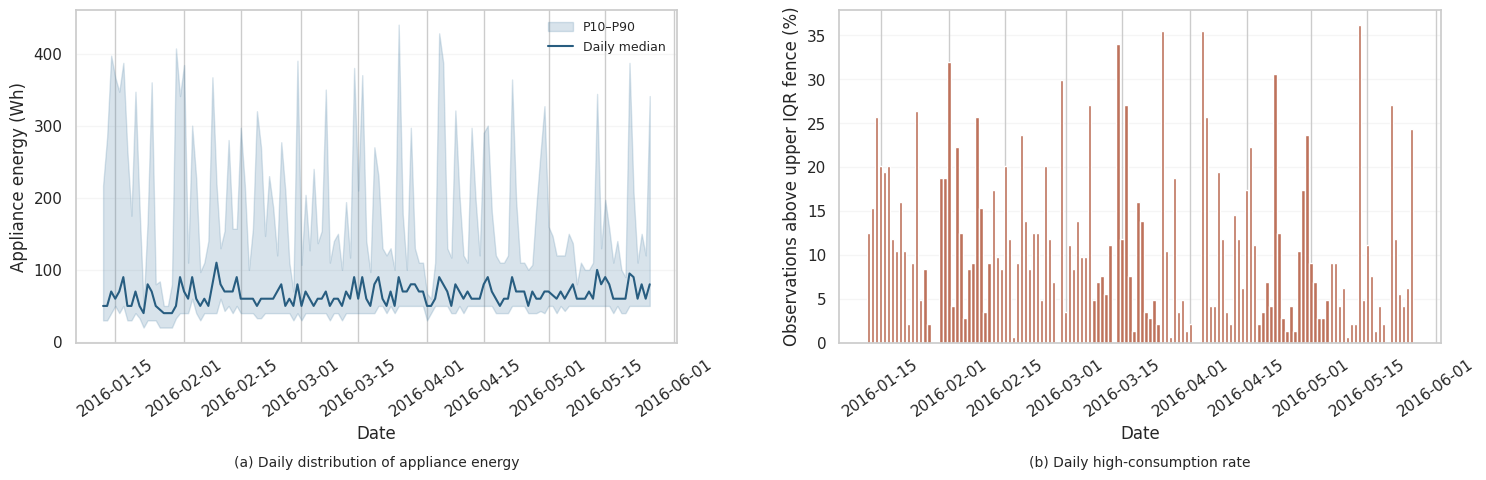

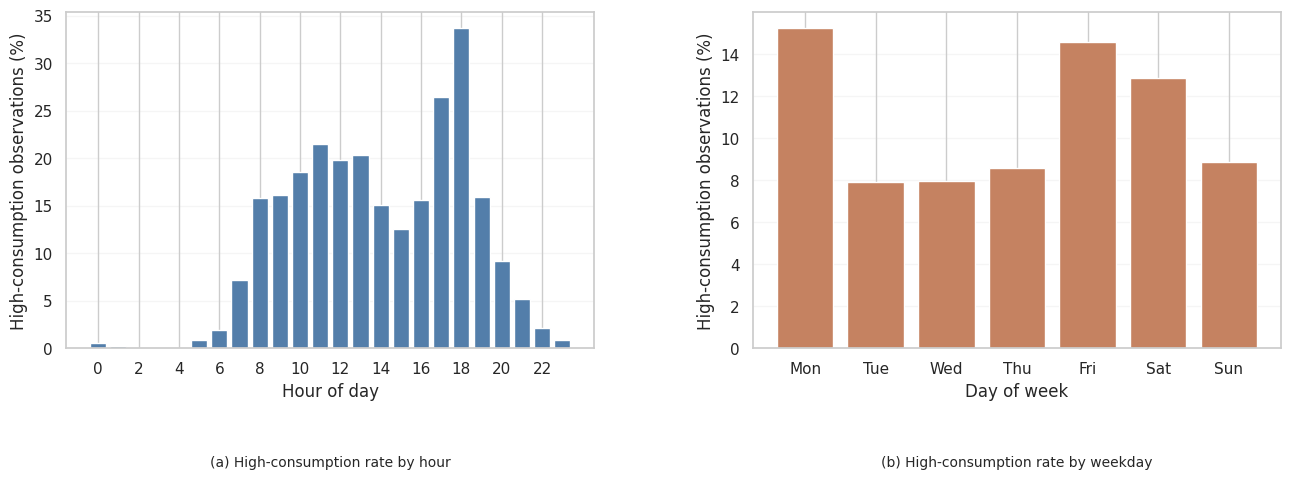

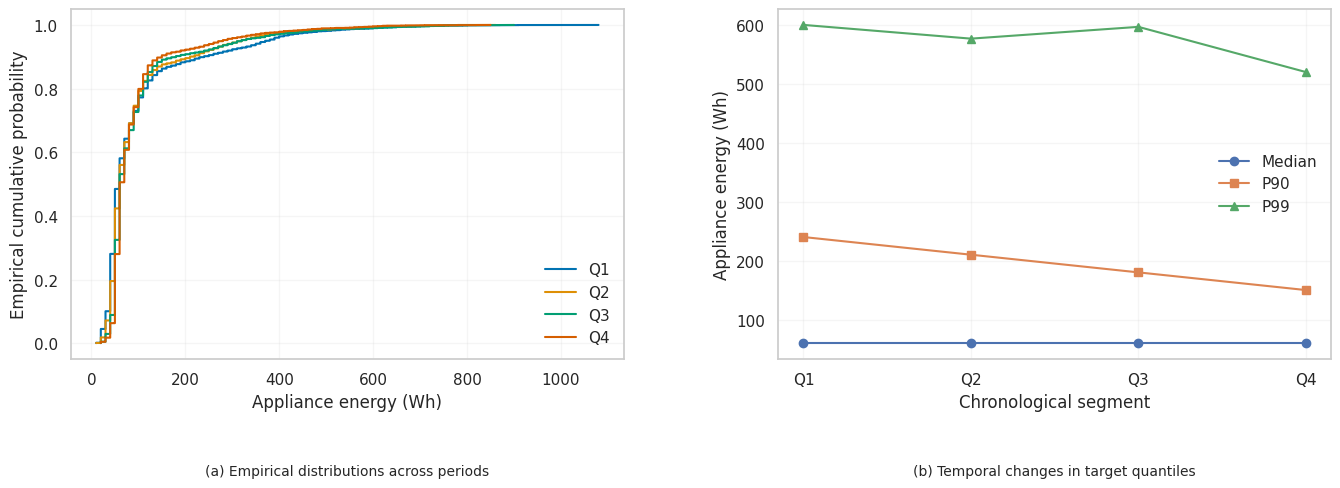

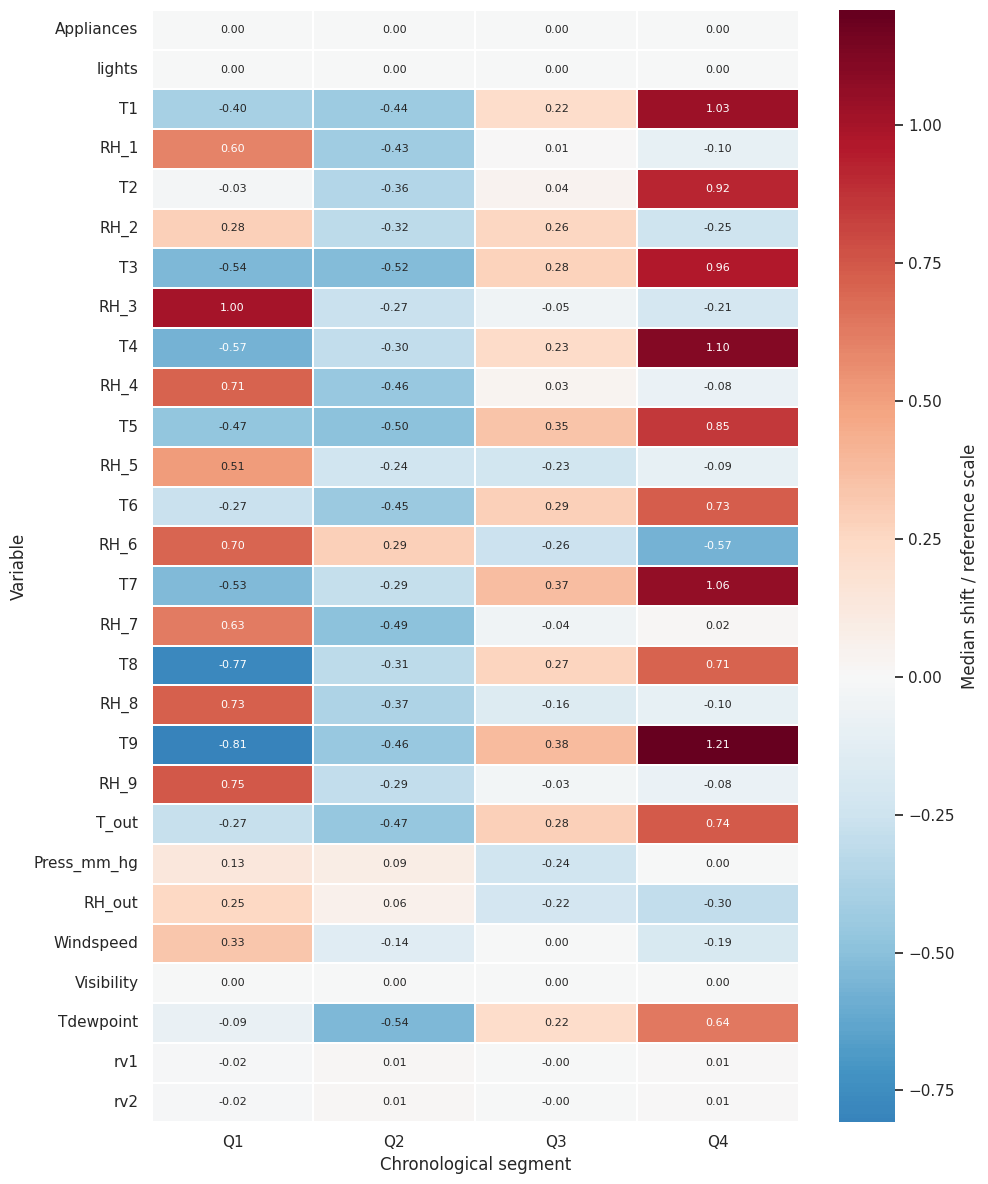

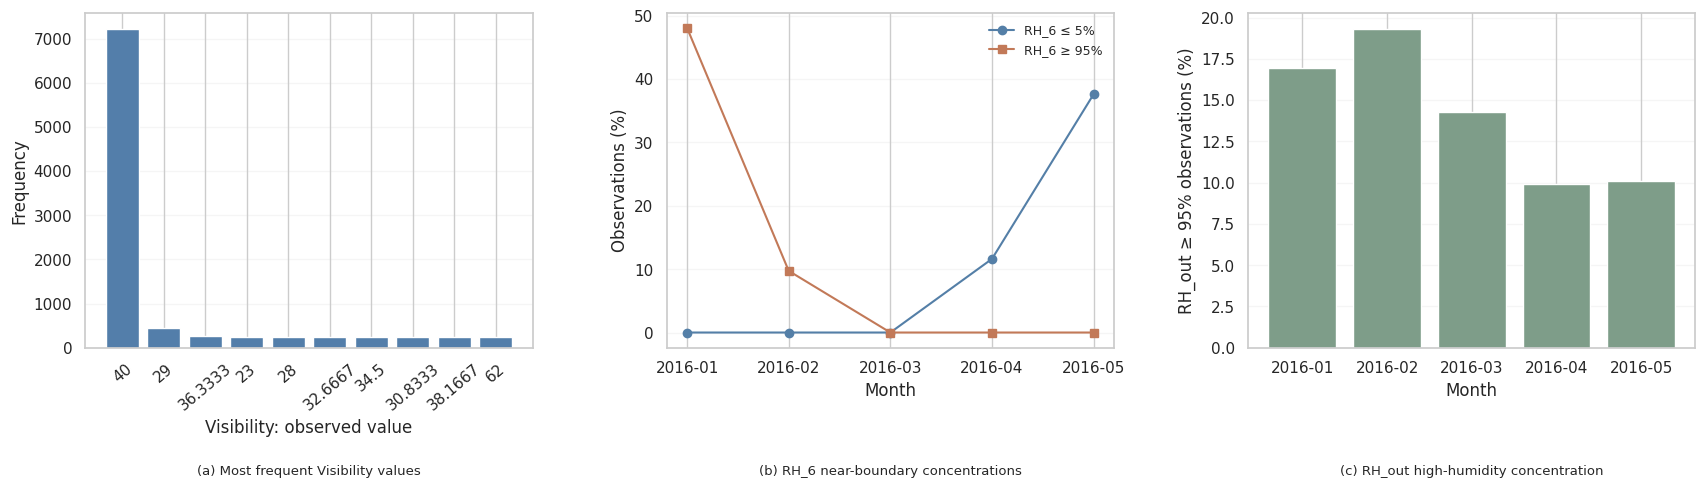

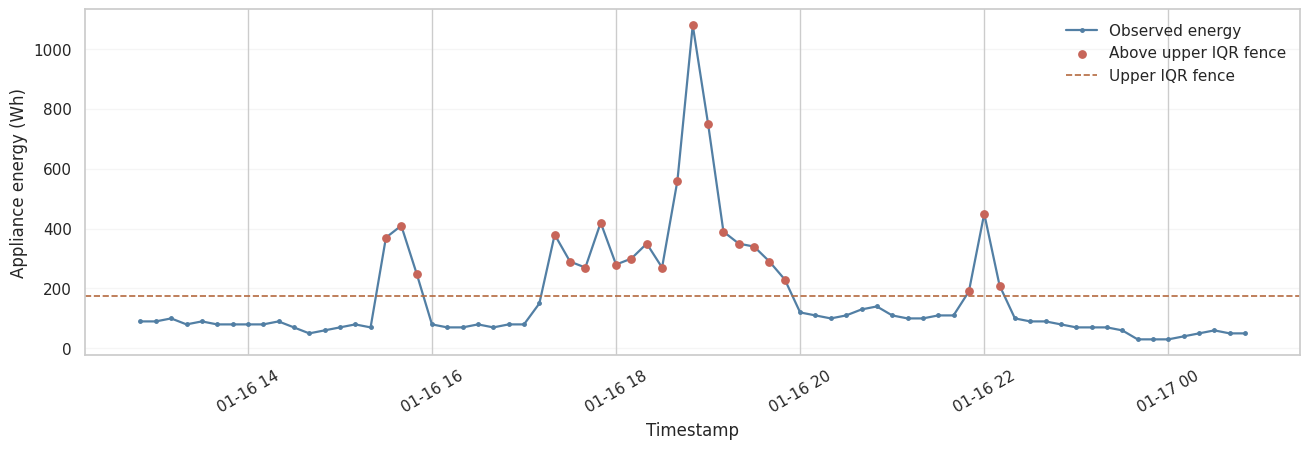


J. MAXIMUM EVENT
Timestamp: 2016-01-16 18:50:00
Peak energy (Wh): 1080.0
Observations in local window: 73

CELL 10B COMPLETED
Numerical variables audited: 28
Extreme-event thresholds examined: 3
Chronological segments: 4
Tables saved: 12
Figures saved: 6

No outliers removed.
No transformations applied.
No feature sets modified.
No model training performed.

Metadata saved:
/content/drive/MyDrive/Stability_Driven_Energy/09_experiment_metadata/notebook01_extreme_temporal_audit.json


In [18]:

# ============================================================
# CELL 10B — EXTREME VALUE & TEMPORAL DISTRIBUTION AUDIT
# Stability-Driven Appliance Energy Evaluation
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from datetime import datetime, timezone

# ------------------------------------------------------------
# 1. Configuration and validation
# ------------------------------------------------------------

OUTDIR = PATHS["eda"]
OUTDIR.mkdir(parents=True, exist_ok=True)

TARGET = "Appliances"
TIME_COL = "date"
INTERVAL_MINUTES = 10

numeric_cols = df_raw.select_dtypes(
    include=[np.number]
).columns.tolist()

audit = df_raw[
    [TIME_COL] + numeric_cols
].copy()

audit[TIME_COL] = pd.to_datetime(
    audit[TIME_COL],
    errors="raise"
)

audit = audit.sort_values(
    TIME_COL
).reset_index(drop=True)

assert len(audit) == 19735
assert len(numeric_cols) == 28
assert audit[TIME_COL].is_unique
assert audit[numeric_cols].notna().all().all()
assert np.isfinite(
    audit[numeric_cols].to_numpy(dtype=float)
).all()

time_differences = audit[TIME_COL].diff().dropna()

assert (
    time_differences ==
    pd.Timedelta(minutes=INTERVAL_MINUTES)
).all()

print("=" * 70)
print("CELL 10B — EXTREME VALUE & TEMPORAL DISTRIBUTION")
print("=" * 70)

print("Observations:", len(audit))
print("Numerical variables:", len(numeric_cols))
print("First timestamp:", audit[TIME_COL].min())
print("Last timestamp:", audit[TIME_COL].max())
print("Temporal continuity: PASS")

# ------------------------------------------------------------
# 2. IQR diagnostic for ALL 28 numerical variables
# ------------------------------------------------------------

fences = {}
fence_records = []

for col in numeric_cols:

    s = audit[col].astype(float)

    q1 = float(s.quantile(0.25))
    q3 = float(s.quantile(0.75))
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    low_flag = s < lower
    high_flag = s > upper

    fences[col] = {
        "lower": lower,
        "upper": upper,
        "iqr": iqr
    }

    fence_records.append({
        "variable": col,
        "q1": q1,
        "q3": q3,
        "iqr": iqr,
        "lower_fence": lower,
        "upper_fence": upper,
        "iqr_zero": bool(np.isclose(iqr, 0)),
        "n_below": int(low_flag.sum()),
        "n_above": int(high_flag.sum()),
        "n_flagged": int(
            (low_flag | high_flag).sum()
        ),
        "flagged_pct": float(
            (low_flag | high_flag).mean() * 100
        )
    })

fence_table = pd.DataFrame(fence_records)

print("\nA. IQR DIAGNOSTIC — ALL VARIABLES")

display(
    fence_table[[
        "variable",
        "iqr",
        "lower_fence",
        "upper_fence",
        "iqr_zero",
        "n_below",
        "n_above",
        "flagged_pct"
    ]].round(4)
)

# IQR flags indicate statistical unusualness,
# NOT confirmed measurement errors.

# ------------------------------------------------------------
# 3. Target extreme-event thresholds
# ------------------------------------------------------------

y = audit[TARGET].astype(float)

iqr_threshold = fences[TARGET]["upper"]
p95_threshold = float(y.quantile(0.95))
p99_threshold = float(y.quantile(0.99))

thresholds = {
    "Upper IQR fence": iqr_threshold,
    "P95": p95_threshold,
    "P99": p99_threshold
}

threshold_table = pd.DataFrame([
    {
        "criterion": name,
        "threshold_wh": value,
        "n_exceeding": int((y > value).sum()),
        "pct_exceeding": float(
            (y > value).mean() * 100
        )
    }
    for name, value in thresholds.items()
])

print("\nB. APPLIANCES — EXTREME EVENT THRESHOLDS")
display(threshold_table.round(4))

# The high-consumption flag below is descriptive.
# It will NOT be used to remove training observations.

audit["high_energy_flag"] = (
    audit[TARGET] > iqr_threshold
)

# ------------------------------------------------------------
# 4. Consecutive high-consumption episodes
# ------------------------------------------------------------

def extract_exceedance_episodes(
    frame,
    threshold,
    label
):

    mask = (
        frame[TARGET].to_numpy(dtype=float)
        > threshold
    )

    previous_not_flagged = np.r_[
        True,
        ~mask[:-1]
    ]

    temporal_gap = (
        frame[TIME_COL]
        .diff()
        .ne(pd.Timedelta(minutes=INTERVAL_MINUTES))
        .to_numpy()
    )

    new_episode = (
        previous_not_flagged | temporal_gap
    )

    episode_ids = np.cumsum(new_episode)

    selected = frame.loc[
        mask,
        [TIME_COL, TARGET]
    ].copy()

    if selected.empty:
        return pd.DataFrame(columns=[
            "criterion",
            "start",
            "end",
            "n_intervals",
            "duration_minutes",
            "peak_wh",
            "mean_wh"
        ])

    selected["episode_id"] = episode_ids[mask]

    episodes = (
        selected
        .groupby("episode_id")
        .agg(
            start=(TIME_COL, "min"),
            end=(TIME_COL, "max"),
            n_intervals=(TARGET, "size"),
            peak_wh=(TARGET, "max"),
            mean_wh=(TARGET, "mean")
        )
        .reset_index(drop=True)
    )

    episodes["duration_minutes"] = (
        episodes["n_intervals"] * INTERVAL_MINUTES
    )

    episodes.insert(0, "criterion", label)

    return episodes


episode_tables = []
episode_summary_records = []

for label, threshold in thresholds.items():

    episodes = extract_exceedance_episodes(
        audit,
        threshold,
        label
    )

    episode_tables.append(episodes)

    episode_summary_records.append({
        "criterion": label,
        "threshold_wh": threshold,
        "n_episodes": len(episodes),
        "single_interval_episodes": int(
            (episodes["n_intervals"] == 1).sum()
        ),
        "multi_interval_episodes": int(
            (episodes["n_intervals"] > 1).sum()
        ),
        "median_duration_minutes": (
            float(episodes["duration_minutes"].median())
            if len(episodes) else 0
        ),
        "maximum_duration_minutes": (
            float(episodes["duration_minutes"].max())
            if len(episodes) else 0
        ),
        "maximum_peak_wh": (
            float(episodes["peak_wh"].max())
            if len(episodes) else np.nan
        )
    })

episodes_all = pd.concat(
    episode_tables,
    ignore_index=True
)

episode_summary = pd.DataFrame(
    episode_summary_records
)

print("\nC. HIGH-CONSUMPTION EPISODE SUMMARY")
display(episode_summary.round(3))

print("\nLARGEST EPISODES — UPPER IQR FENCE")

display(
    episodes_all.loc[
        episodes_all["criterion"] == "Upper IQR fence"
    ].sort_values(
        ["peak_wh", "n_intervals"],
        ascending=False
    ).head(15)
)

# ------------------------------------------------------------
# 5. Daily distribution and extreme-event rates
# ------------------------------------------------------------

daily_series = audit.set_index(TIME_COL)[TARGET]

daily = daily_series.resample("D").agg(
    ["count", "mean", "median", "max"]
)

daily.columns = [
    "n_observations",
    "mean_wh",
    "median_wh",
    "max_wh"
]

daily["p10_wh"] = (
    daily_series.resample("D").quantile(0.10)
)

daily["p90_wh"] = (
    daily_series.resample("D").quantile(0.90)
)

daily["p99_wh"] = (
    daily_series.resample("D").quantile(0.99)
)

daily["n_high"] = (
    audit.set_index(TIME_COL)["high_energy_flag"]
    .resample("D").sum()
)

daily["high_rate_pct"] = (
    100 * daily["n_high"]
    / daily["n_observations"]
)

daily["full_day"] = (
    daily["n_observations"] == 144
)

daily = daily.reset_index()

print("\nD. DAILY COVERAGE")

print("Total calendar days:", len(daily))
print("Complete days:", int(daily["full_day"].sum()))
print("Partial days:", int((~daily["full_day"]).sum()))

display(
    daily.loc[
        ~daily["full_day"],
        [TIME_COL, "n_observations", "high_rate_pct"]
    ].round(3)
)

# Full days used for daily visual comparisons.
# All observations remain in the dataset.

daily_full = daily.loc[
    daily["full_day"]
].copy()

# ------------------------------------------------------------
# 6. Hourly and weekday event rates
# ------------------------------------------------------------

audit["hour"] = audit[TIME_COL].dt.hour
audit["weekday"] = audit[TIME_COL].dt.dayofweek
audit["month"] = (
    audit[TIME_COL].dt.to_period("M").astype(str)
)

hourly_rates = (
    audit.groupby("hour")
    .agg(
        n_observations=(TARGET, "size"),
        n_high=("high_energy_flag", "sum")
    )
    .reset_index()
)

hourly_rates["high_rate_pct"] = (
    100 * hourly_rates["n_high"]
    / hourly_rates["n_observations"]
)

weekday_rates = (
    audit.groupby("weekday")
    .agg(
        n_observations=(TARGET, "size"),
        n_high=("high_energy_flag", "sum")
    )
    .reset_index()
)

weekday_rates["high_rate_pct"] = (
    100 * weekday_rates["n_high"]
    / weekday_rates["n_observations"]
)

weekday_names = [
    "Mon", "Tue", "Wed", "Thu",
    "Fri", "Sat", "Sun"
]

weekday_rates["day_name"] = (
    weekday_rates["weekday"].map(
        dict(enumerate(weekday_names))
    )
)

print("\nE. HIGH-CONSUMPTION RATE BY HOUR")
display(hourly_rates.round(3))

print("\nF. HIGH-CONSUMPTION RATE BY WEEKDAY")
display(weekday_rates.round(3))

# ------------------------------------------------------------
# 7. Chronological distribution comparison
# ------------------------------------------------------------

# Four approximately equal-sized chronological segments.
# These are NOT train/validation/test partitions.

segment_labels = ["Q1", "Q2", "Q3", "Q4"]

segment_index = (
    np.arange(len(audit)) * 4 // len(audit)
)

audit["segment"] = pd.Categorical(
    [segment_labels[i] for i in segment_index],
    categories=segment_labels,
    ordered=True
)

segment_records = []

for segment, group in audit.groupby(
    "segment", observed=True
):

    s = group[TARGET]

    segment_records.append({
        "segment": str(segment),
        "start": group[TIME_COL].min(),
        "end": group[TIME_COL].max(),
        "n": len(group),
        "mean_wh": float(s.mean()),
        "median_wh": float(s.median()),
        "p90_wh": float(s.quantile(0.90)),
        "p95_wh": float(s.quantile(0.95)),
        "p99_wh": float(s.quantile(0.99)),
        "max_wh": float(s.max()),
        "skewness": float(s.skew()),
        "high_rate_pct": float(
            group["high_energy_flag"].mean() * 100
        )
    })

segment_summary = pd.DataFrame(segment_records)

print("\nG. TEMPORAL DISTRIBUTION — APPLIANCES")
display(segment_summary.round(4))

# ------------------------------------------------------------
# 8. Temporal distribution audit for ALL variables
# ------------------------------------------------------------

all_variable_segment_records = []
median_shift_records = []

for col in numeric_cols:

    overall_median = float(audit[col].median())
    overall_iqr = float(fences[col]["iqr"])
    overall_std = float(audit[col].std())

    # Normalization is solely for diagnostic visualization.
    scale = (
        overall_iqr if overall_iqr > 0
        else overall_std if overall_std > 0
        else 1.0
    )

    for segment, group in audit.groupby(
        "segment", observed=True
    ):

        s = group[col]

        lower = fences[col]["lower"]
        upper = fences[col]["upper"]

        flagged = (s < lower) | (s > upper)

        segment_median = float(s.median())

        all_variable_segment_records.append({
            "variable": col,
            "segment": str(segment),
            "n": len(s),
            "median": segment_median,
            "mean": float(s.mean()),
            "p05": float(s.quantile(0.05)),
            "p95": float(s.quantile(0.95)),
            "iqr_flag_pct": float(
                flagged.mean() * 100
            )
        })

        median_shift_records.append({
            "variable": col,
            "segment": str(segment),
            "normalized_median_shift": (
                (segment_median - overall_median)
                / scale
            )
        })

all_variable_segments = pd.DataFrame(
    all_variable_segment_records
)

median_shift_long = pd.DataFrame(
    median_shift_records
)

median_shift_matrix = (
    median_shift_long.pivot(
        index="variable",
        columns="segment",
        values="normalized_median_shift"
    )
    .reindex(
        index=numeric_cols,
        columns=segment_labels
    )
)

# ------------------------------------------------------------
# 9. Audit boundary concentrations and repeated values
# ------------------------------------------------------------

priority_variables = [
    "Visibility",
    "RH_6",
    "RH_out",
    "lights",
    "RH_5"
]

def longest_equal_run(series):

    s = series.reset_index(drop=True)

    run_id = s.ne(s.shift()).cumsum()

    run_sizes = s.groupby(run_id).size()

    return int(run_sizes.max())


boundary_records = []

for col in priority_variables:

    s = audit[col].astype(float)

    value_counts = s.value_counts()

    mode_value = float(value_counts.index[0])

    exact_mode_mask = np.isclose(
        s.to_numpy(),
        mode_value,
        atol=1e-10,
        rtol=0
    )

    repeated_previous_pct = (
        s.eq(s.shift()).iloc[1:].mean() * 100
    )

    record = {
        "variable": col,
        "min": float(s.min()),
        "max": float(s.max()),
        "n_unique": int(s.nunique()),
        "most_frequent_value": mode_value,
        "mode_pct": float(
            exact_mode_mask.mean() * 100
        ),
        "repeat_previous_pct": float(
            repeated_previous_pct
        ),
        "longest_identical_run_intervals": (
            longest_equal_run(s)
        ),
        "longest_identical_run_minutes": (
            longest_equal_run(s) * INTERVAL_MINUTES
        )
    }

    if col in ["RH_6", "RH_out", "RH_5"]:

        record["below_0_count"] = int(
            (s < 0).sum()
        )

        record["above_100_count"] = int(
            (s > 100).sum()
        )

        record["at_least_95_pct"] = float(
            (s >= 95).mean() * 100
        )

        record["at_most_5_pct"] = float(
            (s <= 5).mean() * 100
        )

    boundary_records.append(record)

boundary_audit = pd.DataFrame(
    boundary_records
)

print("\nH. BOUNDARY AND REPEATED-VALUE AUDIT")
display(boundary_audit.round(4))

for col in priority_variables:

    print(f"\nMost frequent exact values — {col}")

    display(
        audit[col].value_counts()
        .head(10)
        .rename_axis("observed_value")
        .reset_index(name="frequency")
    )

# ------------------------------------------------------------
# 10. Monthly boundary concentration
# ------------------------------------------------------------

visibility_mode = float(
    audit["Visibility"].mode().iloc[0]
)

monthly_boundaries = (
    audit.groupby("month")
    .agg(
        n=("Visibility", "size"),

        visibility_mode_pct=(
            "Visibility",
            lambda x: float(
                np.isclose(
                    x.to_numpy(),
                    visibility_mode,
                    atol=1e-10,
                    rtol=0
                ).mean() * 100
            )
        ),

        rh6_low_pct=(
            "RH_6",
            lambda x: float(
                (x <= 5).mean() * 100
            )
        ),

        rh6_high_pct=(
            "RH_6",
            lambda x: float(
                (x >= 95).mean() * 100
            )
        ),

        rhout_high_pct=(
            "RH_out",
            lambda x: float(
                (x >= 95).mean() * 100
            )
        )
    )
    .reset_index()
)

print("\nI. MONTHLY BOUNDARY CONCENTRATION")
display(monthly_boundaries.round(3))

# ------------------------------------------------------------
# 11. Figure 1 — daily distribution and extremes
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2, figsize=(15, 4.9)
)

axes[0].fill_between(
    daily_full[TIME_COL],
    daily_full["p10_wh"],
    daily_full["p90_wh"],
    alpha=0.22,
    color="#4F83A7",
    label="P10–P90"
)

axes[0].plot(
    daily_full[TIME_COL],
    daily_full["median_wh"],
    color="#285D80",
    linewidth=1.5,
    label="Daily median"
)

axes[0].set_xlabel("Date")
axes[0].set_ylabel("Appliance energy (Wh)")
axes[0].legend(frameon=False, fontsize=9)

axes[1].bar(
    daily_full[TIME_COL],
    daily_full["high_rate_pct"],
    width=0.85,
    color="#BE725B"
)

axes[1].set_xlabel("Date")
axes[1].set_ylabel(
    "Observations above upper IQR fence (%)"
)

for ax in axes:
    ax.grid(axis="y", alpha=0.18)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", rotation=35)

captions = [
    "(a) Daily distribution of appliance energy",
    "(b) Daily high-consumption rate"
]

for ax, caption in zip(axes, captions):
    ax.text(
        0.5, -0.34,
        caption,
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=10
    )

fig.subplots_adjust(
    left=0.07, right=0.98,
    top=0.97, bottom=0.29,
    wspace=0.27
)

fig.savefig(
    OUTDIR / "10B_01_daily_energy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 12. Figure 2 — temporal concentration of high events
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2, figsize=(13.5, 4.8)
)

axes[0].bar(
    hourly_rates["hour"],
    hourly_rates["high_rate_pct"],
    color="#537EAA"
)

axes[0].set_xticks(range(0, 24, 2))
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel(
    "High-consumption observations (%)"
)

axes[1].bar(
    weekday_rates["day_name"],
    weekday_rates["high_rate_pct"],
    color="#C58261"
)

axes[1].set_xlabel("Day of week")
axes[1].set_ylabel(
    "High-consumption observations (%)"
)

for ax in axes:
    ax.grid(axis="y", alpha=0.18)
    ax.set_axisbelow(True)

axes[0].text(
    0.5, -0.32,
    "(a) High-consumption rate by hour",
    transform=axes[0].transAxes,
    ha="center",
    va="top",
    fontsize=10
)

axes[1].text(
    0.5, -0.32,
    "(b) High-consumption rate by weekday",
    transform=axes[1].transAxes,
    ha="center",
    va="top",
    fontsize=10
)

fig.subplots_adjust(
    left=0.08, right=0.98,
    top=0.96, bottom=0.26,
    wspace=0.30
)

fig.savefig(
    OUTDIR / "10B_02_high_event_timing.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 13. Figure 3 — distribution shift over time
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2, figsize=(14, 5)
)

palette = sns.color_palette(
    "colorblind", n_colors=4
)

for i, segment in enumerate(segment_labels):

    values = np.sort(
        audit.loc[
            audit["segment"] == segment,
            TARGET
        ].to_numpy(dtype=float)
    )

    ecdf = (
        np.arange(1, len(values) + 1)
        / len(values)
    )

    axes[0].step(
        values,
        ecdf,
        where="post",
        color=palette[i],
        label=segment,
        linewidth=1.5
    )

axes[0].set_xlabel("Appliance energy (Wh)")
axes[0].set_ylabel("Empirical cumulative probability")
axes[0].legend(frameon=False)

for col, label, marker in [
    ("median_wh", "Median", "o"),
    ("p90_wh", "P90", "s"),
    ("p99_wh", "P99", "^")
]:

    axes[1].plot(
        segment_summary["segment"],
        segment_summary[col],
        marker=marker,
        linewidth=1.5,
        label=label
    )

axes[1].set_xlabel("Chronological segment")
axes[1].set_ylabel("Appliance energy (Wh)")
axes[1].legend(frameon=False)

for ax in axes:
    ax.grid(alpha=0.18)
    ax.set_axisbelow(True)

axes[0].text(
    0.5, -0.30,
    "(a) Empirical distributions across periods",
    transform=axes[0].transAxes,
    ha="center",
    va="top",
    fontsize=10
)

axes[1].text(
    0.5, -0.30,
    "(b) Temporal changes in target quantiles",
    transform=axes[1].transAxes,
    ha="center",
    va="top",
    fontsize=10
)

fig.subplots_adjust(
    left=0.08, right=0.98,
    top=0.96, bottom=0.26,
    wspace=0.28
)

fig.savefig(
    OUTDIR / "10B_03_distribution_shift.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 14. Figure 4 — ALL variables, temporal median changes
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(10, 12)
)

sns.heatmap(
    median_shift_matrix,
    cmap="RdBu_r",
    center=0,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 8},
    linewidths=0.35,
    cbar_kws={
        "label": "Median shift / reference scale"
    },
    ax=ax
)

ax.set_xlabel("Chronological segment")
ax.set_ylabel("Variable")

ax.tick_params(axis="x", rotation=0)
ax.tick_params(axis="y", rotation=0)

plt.tight_layout()

fig.savefig(
    OUTDIR / "10B_04_all_variable_temporal_shift.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 15. Figure 5 — suspicious-looking value concentrations
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3, figsize=(17.5, 5)
)

top_visibility = (
    audit["Visibility"]
    .value_counts()
    .head(10)
    .sort_values(ascending=False)
)

axes[0].bar(
    [f"{x:g}" for x in top_visibility.index],
    top_visibility.values,
    color="#537EAA"
)

axes[0].set_xlabel("Visibility: observed value")
axes[0].set_ylabel("Frequency")
axes[0].tick_params(axis="x", rotation=40)

axes[1].plot(
    monthly_boundaries["month"],
    monthly_boundaries["rh6_low_pct"],
    marker="o",
    label="RH_6 ≤ 5%",
    color="#547FA7"
)

axes[1].plot(
    monthly_boundaries["month"],
    monthly_boundaries["rh6_high_pct"],
    marker="s",
    label="RH_6 ≥ 95%",
    color="#C27958"
)

axes[1].set_xlabel("Month")
axes[1].set_ylabel("Observations (%)")
axes[1].legend(frameon=False, fontsize=9)

axes[2].bar(
    monthly_boundaries["month"],
    monthly_boundaries["rhout_high_pct"],
    color="#7E9D89"
)

axes[2].set_xlabel("Month")
axes[2].set_ylabel(
    "RH_out ≥ 95% observations (%)"
)

captions = [
    "(a) Most frequent Visibility values",
    "(b) RH_6 near-boundary concentrations",
    "(c) RH_out high-humidity concentration"
]

for ax, caption in zip(axes, captions):

    ax.grid(axis="y", alpha=0.18)
    ax.set_axisbelow(True)

    ax.text(
        0.5, -0.35,
        caption,
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=9.5
    )

fig.subplots_adjust(
    left=0.06, right=0.98,
    top=0.96, bottom=0.29,
    wspace=0.30
)

fig.savefig(
    OUTDIR / "10B_05_boundary_concentrations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 16. Figure 6 — context around maximum energy observation
# ------------------------------------------------------------

peak_idx = audit[TARGET].idxmax()
peak_time = audit.loc[peak_idx, TIME_COL]

window_start = peak_time - pd.Timedelta(hours=6)
window_end = peak_time + pd.Timedelta(hours=6)

peak_window = audit.loc[
    audit[TIME_COL].between(
        window_start, window_end
    )
].copy()

fig, ax = plt.subplots(
    figsize=(13.5, 4.8)
)

ax.plot(
    peak_window[TIME_COL],
    peak_window[TARGET],
    color="#527FA4",
    linewidth=1.6,
    marker="o",
    markersize=2.5,
    label="Observed energy"
)

high_window = peak_window.loc[
    peak_window[TARGET] > iqr_threshold
]

ax.scatter(
    high_window[TIME_COL],
    high_window[TARGET],
    color="#C76559",
    s=28,
    label="Above upper IQR fence",
    zorder=3
)

ax.axhline(
    iqr_threshold,
    color="#B46A40",
    linestyle="--",
    linewidth=1.2,
    label="Upper IQR fence"
)

ax.set_xlabel("Timestamp")
ax.set_ylabel("Appliance energy (Wh)")
ax.grid(axis="y", alpha=0.18)
ax.tick_params(axis="x", rotation=30)
ax.legend(frameon=False)

fig.subplots_adjust(
    left=0.08, right=0.98,
    top=0.97, bottom=0.25
)

fig.savefig(
    OUTDIR / "10B_06_maximum_event_context.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nJ. MAXIMUM EVENT")
print("Timestamp:", peak_time)
print("Peak energy (Wh):", float(audit.loc[peak_idx, TARGET]))
print("Observations in local window:", len(peak_window))

# ------------------------------------------------------------
# 17. Save tables
# ------------------------------------------------------------

tables_to_save = {
    "10B_all_variable_iqr_audit.csv":
        fence_table,

    "10B_energy_thresholds.csv":
        threshold_table,

    "10B_energy_episode_summary.csv":
        episode_summary,

    "10B_energy_episodes.csv":
        episodes_all,

    "10B_daily_energy_summary.csv":
        daily,

    "10B_hourly_high_rate.csv":
        hourly_rates,

    "10B_weekday_high_rate.csv":
        weekday_rates,

    "10B_chronological_segment_summary.csv":
        segment_summary,

    "10B_all_variable_segment_statistics.csv":
        all_variable_segments,

    "10B_boundary_value_audit.csv":
        boundary_audit,

    "10B_monthly_boundary_rates.csv":
        monthly_boundaries,

    "10B_all_variable_median_shift.csv":
        median_shift_matrix.reset_index()
}

for filename, table in tables_to_save.items():

    table.to_csv(
        OUTDIR / filename,
        index=False
    )

# ------------------------------------------------------------
# 18. Save audit metadata
# ------------------------------------------------------------

metadata = {
    "cell": "10B",
    "stage": "Extreme value and temporal audit",

    "n_observations": int(len(audit)),

    "target": TARGET,

    "target_thresholds": {
        key: float(value)
        for key, value in thresholds.items()
    },

    "temporal_resolution_minutes": INTERVAL_MINUTES,

    "chronological_segments": segment_labels,

    "segment_definition": (
        "Four approximately equal consecutive "
        "observation-count segments; descriptive only"
    ),

    "visibility_empirical_mode": visibility_mode,

    "rh_boundary_diagnostic_cutoffs": {
        "low": 5,
        "high": 95
    },

    "full_dataset_descriptive_audit": True,

    "outliers_removed": False,
    "winsorization_applied": False,
    "imputation_applied": False,
    "transformations_applied": False,
    "feature_sets_modified": False,
    "model_training_performed": False,

    "modeling_thresholds_frozen": False,

    "note": (
        "Full-series descriptive diagnostics only. "
        "Any data-dependent preprocessing decisions "
        "must be developed using training data."
    ),

    "audit_time_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

metadata_path = (
    PATHS["metadata"] /
    "notebook01_extreme_temporal_audit.json"
)

with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=4
    )

# ------------------------------------------------------------
# 19. Final validation
# ------------------------------------------------------------

assert len(fence_table) == 28
assert len(segment_summary) == 4
assert len(median_shift_matrix) == 28

assert len(df_raw) == 19735
assert df_raw.shape[1] == 29

assert df_raw["rv1"].equals(df_raw["rv2"])

print("\n" + "=" * 70)
print("CELL 10B COMPLETED")
print("=" * 70)

print("Numerical variables audited:", len(numeric_cols))
print("Extreme-event thresholds examined:", len(thresholds))
print("Chronological segments:", len(segment_labels))
print("Tables saved:", len(tables_to_save))
print("Figures saved: 6")

print("\nNo outliers removed.")
print("No transformations applied.")
print("No feature sets modified.")
print("No model training performed.")

print("\nMetadata saved:")
print(metadata_path)


# Sensor Consistency & Boundary Artifact Audit

CELL 10C — SENSOR CONSISTENCY & BOUNDARY AUDIT
Observations: 19735
Sensor variables: ['RH_6', 'RH_out', 'T6', 'T_out', 'Visibility', 'Windspeed', 'Press_mm_hg']
Original data preserved.

A. OBSERVED BOUNDARY CONCENTRATIONS


,condition,n_observations,percentage
0,RH6_exact_1,1452,7.3575
1,RH6_exact_99_9,751,3.8054
2,RH6_le_5,1951,9.8860
3,RH6_ge_95,1810,9.1715
4,Visibility_exact_40,7224,36.6050



B. CONSTANT-VALUE EPISODE SUMMARY


,condition,n_observations,n_episodes,single_interval_episodes,multi_interval_episodes,median_duration_hours,p90_duration_hours,maximum_duration_hours
0,RH6_exact_1,1452,52,5,47,2.9167,11.2500,13.1667
1,RH6_exact_99_9,751,10,0,10,8.0000,26.4333,58.8333
2,Visibility_exact_40,7224,324,128,196,1.1667,10.8667,34.1667



C. LONGEST OBSERVED EPISODES


,condition,start,end,n_intervals,duration_hours,RH_out_range,T6_range,T_out_range,Windspeed_range
0,RH6_exact_1,2016-05-08 08:40:00,2016-05-08 21:40:00,79,13.1670,40.3330,11.5000,8.3670,6.0000
1,RH6_exact_1,2016-05-05 08:20:00,2016-05-05 20:50:00,76,12.6670,33.6670,7.5300,10.3000,2.6670
2,RH6_exact_1,2016-05-07 08:40:00,2016-05-07 20:50:00,74,12.3330,33.0000,8.9710,8.9330,4.8330
3,RH6_exact_1,2016-05-14 08:50:00,2016-05-14 20:30:00,71,11.8330,18.0000,5.7930,3.1670,3.0000
4,RH6_exact_1,2016-05-04 09:10:00,2016-05-04 20:30:00,69,11.5000,33.1670,5.9000,6.6670,2.8330
5,RH6_exact_1,2016-05-06 09:10:00,2016-05-06 20:20:00,68,11.3330,32.3330,6.5560,8.2330,3.6670
6,RH6_exact_1,2016-05-09 08:20:00,2016-05-09 18:40:00,63,10.5000,25.0000,7.5590,8.0000,2.0000
7,RH6_exact_1,2016-05-26 10:20:00,2016-05-26 20:30:00,62,10.3330,36.3330,5.6900,6.2330,2.0000
8,RH6_exact_1,2016-04-21 11:20:00,2016-04-21 21:10:00,60,10.0000,24.0000,6.0270,5.6670,2.0000
9,RH6_exact_1,2016-05-03 10:50:00,2016-05-03 20:20:00,58,9.6670,24.8330,5.5230,3.6670,2.6670


... (2 outputs left out)


E. MONTHLY SENSOR CONCENTRATION


,month,n_observations,RH6_exact_1_pct,RH6_exact_99_9_pct,RH6_le_5_pct,RH6_ge_95_pct,Visibility_exact_40_pct,RH6_RHout_correlation,RH6_RHout_interior_correlation
0,2016-01,2922,0.0000,21.8001,0.0000,48.0493,26.0096,0.4221,0.2812
1,2016-02,4176,0.0000,2.7299,0.0000,9.7222,29.6935,0.8193,0.8169
2,2016-03,4464,0.0000,0.0000,0.0000,0.0000,25.4256,0.8329,0.8329
3,2016-04,4320,5.6944,0.0000,11.6204,0.0000,51.0648,0.8915,0.8795
4,2016-05,3853,31.3003,0.0000,37.6071,0.0000,48.8710,0.8640,0.8441



F. RH_6 STATES VS RELATED MEASUREMENTS


,RH6_state,n,RH_out_median,RH_out_p10,RH_out_p90,T6_median,T_out_median,RH6_minus_RHout_median
0,Exact 1.0%,1452,49.6670,35.0000,64.6670,18.8620,15.9670,-48.6670
1,Exact 99.9%,751,94.0000,89.0000,99.0000,8.1900,7.9670,5.9000
2,Other readings,17532,84.5000,63.0000,95.6670,6.5600,6.3000,-26.6380


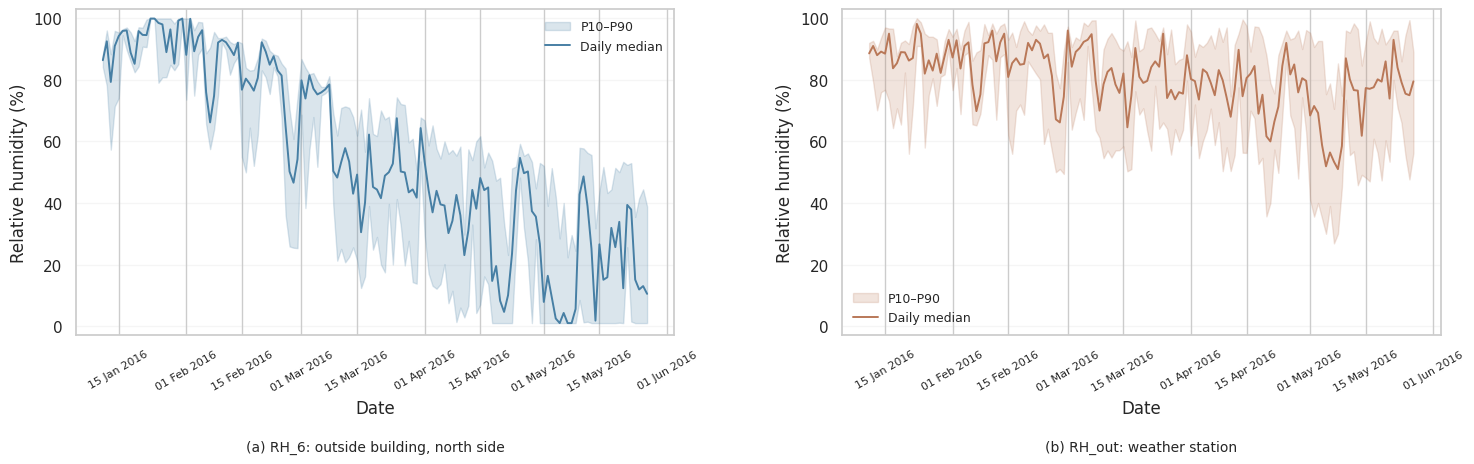

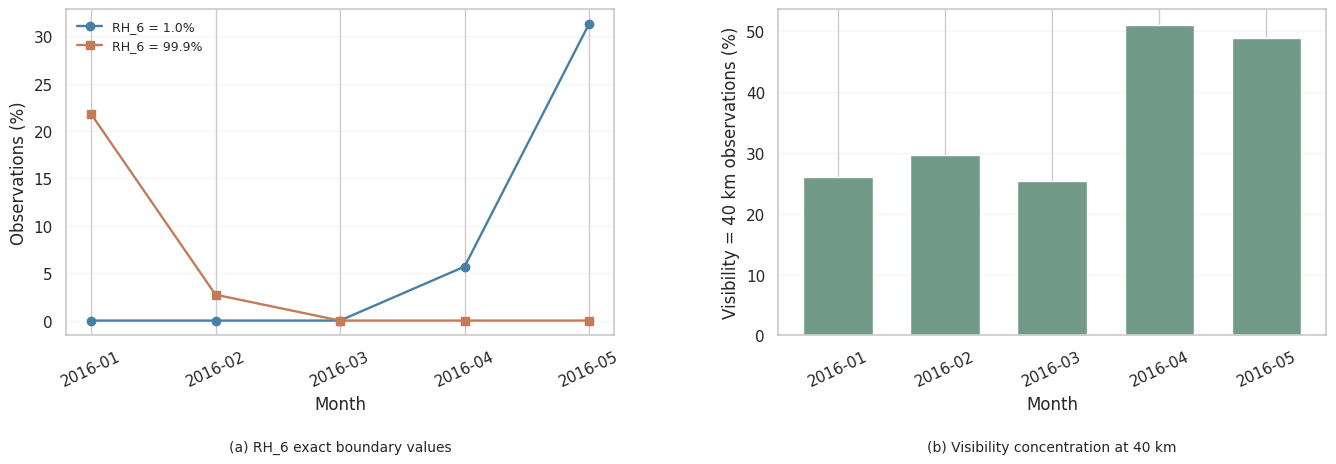

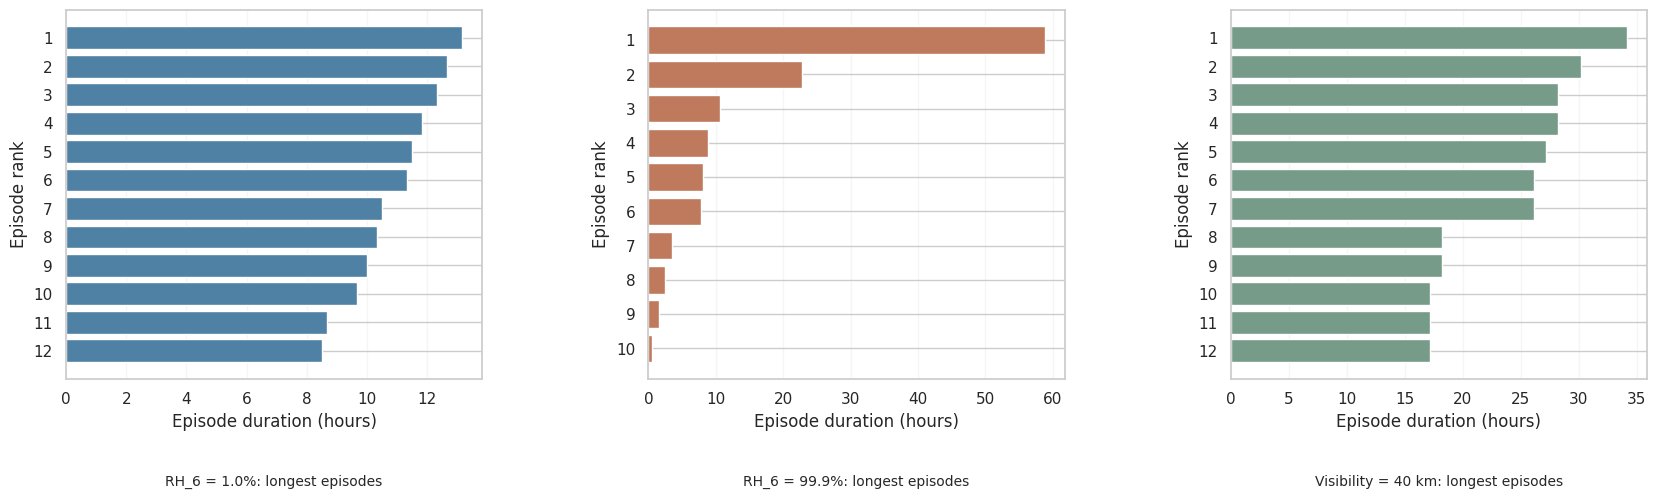

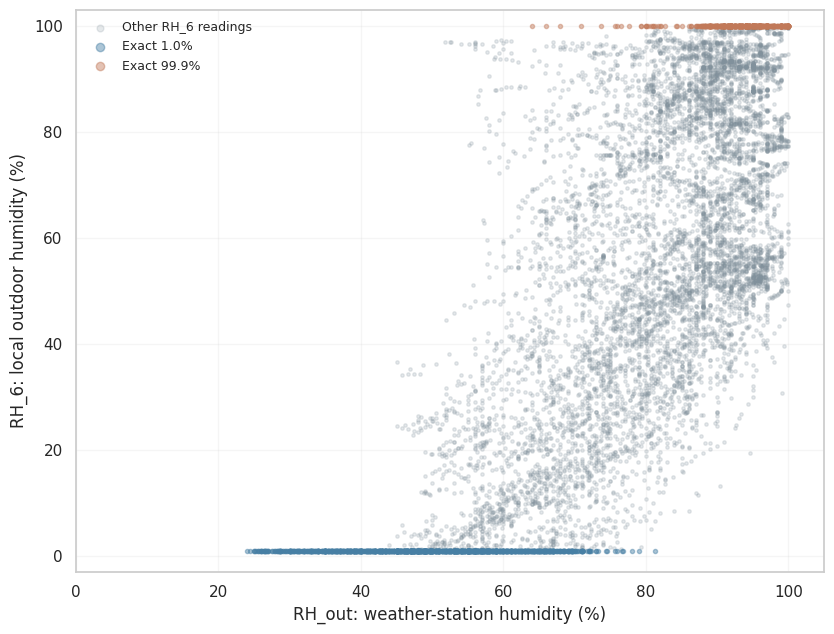

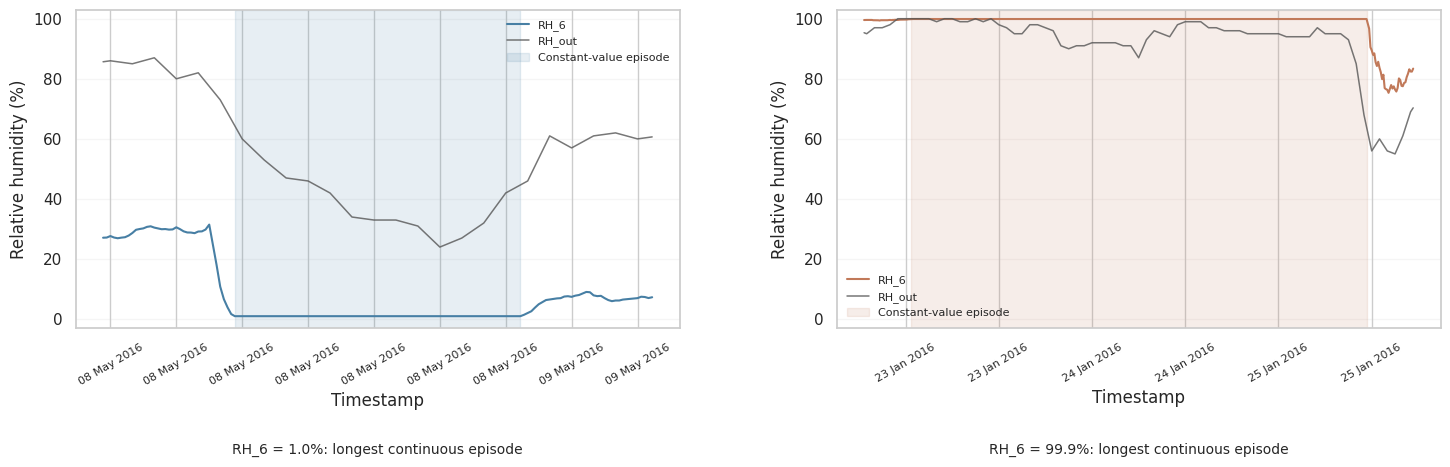

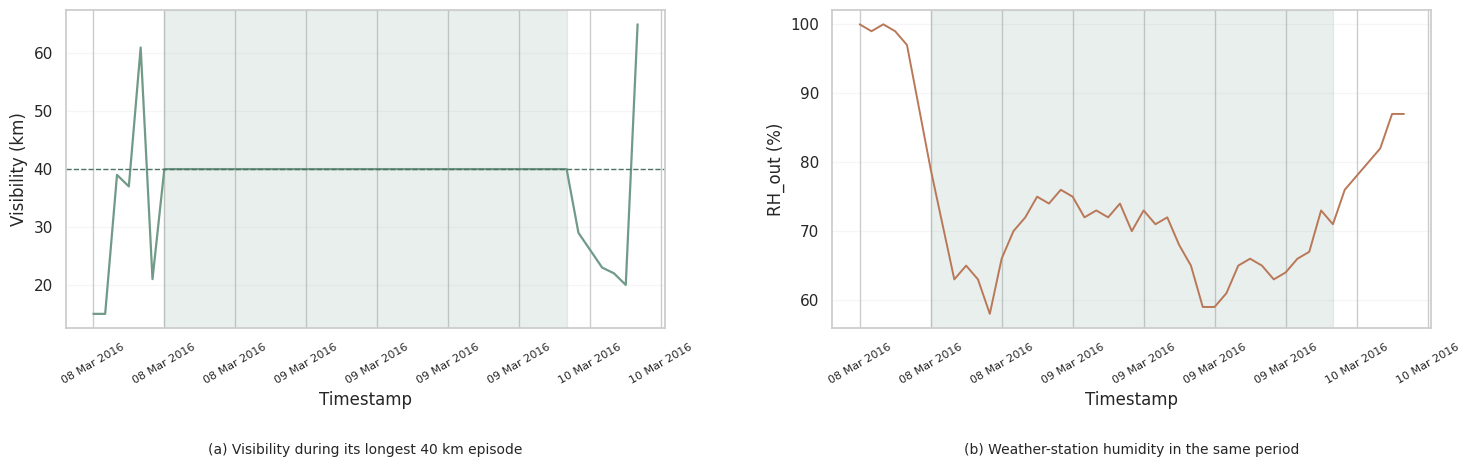


CELL 10C COMPLETED
Boundary conditions audited: 5
Exact-value episode categories: 3
Related sensor variables: 7
Tables saved: 8
Figures saved: 6

Original dataset unchanged.
No sensor fault automatically declared.
No observations removed or replaced.
No feature selection performed.
No final preprocessing decision made.

Metadata saved:
/content/drive/MyDrive/Stability_Driven_Energy/09_experiment_metadata/notebook01_sensor_consistency_audit.json


In [19]:

# ============================================================
# CELL 10C — SENSOR CONSISTENCY & BOUNDARY ARTIFACT AUDIT
# Stability-Driven Appliance Energy Evaluation
# ============================================================

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from datetime import datetime, timezone
from IPython.display import display

# ------------------------------------------------------------
# 1. Configuration and data validation
# ------------------------------------------------------------

OUTDIR = PATHS["eda"]
OUTDIR.mkdir(parents=True, exist_ok=True)

TIME_COL = "date"
INTERVAL_MIN = 10

SENSOR_COLS = [
    "RH_6", "RH_out",
    "T6", "T_out",
    "Visibility", "Windspeed",
    "Press_mm_hg"
]

work = df_raw[
    [TIME_COL] + SENSOR_COLS
].copy()

work[TIME_COL] = pd.to_datetime(
    work[TIME_COL], errors="raise"
)

work = work.sort_values(
    TIME_COL
).reset_index(drop=True)

assert len(work) == 19735
assert work[TIME_COL].is_unique
assert work[TIME_COL].is_monotonic_increasing
assert work[SENSOR_COLS].notna().all().all()

assert (
    work[TIME_COL].diff().dropna()
    == pd.Timedelta(minutes=INTERVAL_MIN)
).all()

print("=" * 70)
print("CELL 10C — SENSOR CONSISTENCY & BOUNDARY AUDIT")
print("=" * 70)
print("Observations:", len(work))
print("Sensor variables:", SENSOR_COLS)
print("Original data preserved.")

# ------------------------------------------------------------
# 2. Define observed boundary and concentration flags
# ------------------------------------------------------------

# Exact values are based on Cell 10B findings.
# They are NOT automatic rules for declaring errors.

def exact_value_flag(series, value):
    return np.isclose(
        series.to_numpy(dtype=float),
        value,
        rtol=0,
        atol=1e-9
    )

FLAG_DEFINITIONS = {
    "RH6_exact_1": exact_value_flag(work["RH_6"], 1.0),
    "RH6_exact_99_9": exact_value_flag(
        work["RH_6"], 99.9
    ),
    "RH6_le_5": (work["RH_6"] <= 5).to_numpy(),
    "RH6_ge_95": (work["RH_6"] >= 95).to_numpy(),
    "Visibility_exact_40": exact_value_flag(
        work["Visibility"], 40.0
    )
}

for flag_name, flag_values in FLAG_DEFINITIONS.items():
    work[flag_name] = flag_values.astype(bool)

work["month"] = (
    work[TIME_COL].dt.to_period("M").astype(str)
)

work["RH6_state"] = np.select(
    [
        work["RH6_exact_1"].to_numpy(),
        work["RH6_exact_99_9"].to_numpy()
    ],
    [
        "Exact 1.0%",
        "Exact 99.9%"
    ],
    default="Other readings"
)

flag_summary = pd.DataFrame([
    {
        "condition": flag_name,
        "n_observations": int(work[flag_name].sum()),
        "percentage": float(
            work[flag_name].mean() * 100
        )
    }
    for flag_name in FLAG_DEFINITIONS
])

print("\nA. OBSERVED BOUNDARY CONCENTRATIONS")
display(flag_summary.round(4))

# ------------------------------------------------------------
# 3. Extract consecutive constant-value episodes
# ------------------------------------------------------------

def extract_flag_episodes(frame, flag_col):

    mask = frame[flag_col].to_numpy(dtype=bool)

    starts = np.flatnonzero(
        mask & np.r_[True, ~mask[:-1]]
    )

    ends = np.flatnonzero(
        mask & np.r_[~mask[1:], True]
    )

    records = []

    for start_idx, end_idx in zip(starts, ends):

        episode = frame.iloc[
            start_idx:end_idx + 1
        ]

        n_intervals = end_idx - start_idx + 1

        record = {
            "condition": flag_col,
            "start_idx": int(start_idx),
            "end_idx": int(end_idx),
            "start": frame.loc[
                start_idx, TIME_COL
            ],
            "end": frame.loc[
                end_idx, TIME_COL
            ],
            "n_intervals": int(n_intervals),
            "duration_minutes": int(
                n_intervals * INTERVAL_MIN
            ),
            "duration_hours": float(
                n_intervals * INTERVAL_MIN / 60
            )
        }

        # Variation in related observations during
        # the flagged episode. Different sensors
        # measure different locations/sources.
        for reference in [
            "RH_out", "T6", "T_out", "Windspeed"
        ]:

            values = episode[reference]

            record[f"{reference}_range"] = float(
                values.max() - values.min()
            )

            record[f"{reference}_net_change"] = float(
                values.iloc[-1] - values.iloc[0]
            )

        records.append(record)

    return pd.DataFrame(records)


EXACT_EVENT_FLAGS = [
    "RH6_exact_1",
    "RH6_exact_99_9",
    "Visibility_exact_40"
]

episode_tables = [
    extract_flag_episodes(work, flag)
    for flag in EXACT_EVENT_FLAGS
]

episodes_all = pd.concat(
    episode_tables, ignore_index=True
)

episode_summary_records = []

for flag_name in EXACT_EVENT_FLAGS:

    ep = episodes_all.loc[
        episodes_all["condition"] == flag_name
    ]

    episode_summary_records.append({
        "condition": flag_name,
        "n_observations": int(work[flag_name].sum()),
        "n_episodes": int(len(ep)),
        "single_interval_episodes": int(
            (ep["n_intervals"] == 1).sum()
        ),
        "multi_interval_episodes": int(
            (ep["n_intervals"] > 1).sum()
        ),
        "median_duration_hours": float(
            ep["duration_hours"].median()
        ),
        "p90_duration_hours": float(
            ep["duration_hours"].quantile(0.90)
        ),
        "maximum_duration_hours": float(
            ep["duration_hours"].max()
        )
    })

episode_summary = pd.DataFrame(
    episode_summary_records
)

print("\nB. CONSTANT-VALUE EPISODE SUMMARY")
display(episode_summary.round(4))

print("\nC. LONGEST OBSERVED EPISODES")

longest_episodes = (
    episodes_all
    .sort_values(
        ["condition", "n_intervals"],
        ascending=[True, False]
    )
    .groupby("condition", group_keys=False)
    .head(10)
    .reset_index(drop=True)
)

display(
    longest_episodes[[
        "condition",
        "start",
        "end",
        "n_intervals",
        "duration_hours",
        "RH_out_range",
        "T6_range",
        "T_out_range",
        "Windspeed_range"
    ]].round(3)
)

# ------------------------------------------------------------
# 4. Compare exact repetition across related variables
# ------------------------------------------------------------

repeat_records = []

for col in SENSOR_COLS:

    values = work[col].to_numpy(dtype=float)

    same_previous = (
        values[1:] == values[:-1]
    )

    starts_new_run = np.r_[
        True,
        values[1:] != values[:-1]
    ]

    run_ids = np.cumsum(starts_new_run)

    run_sizes = (
        pd.Series(run_ids)
        .value_counts()
        .to_numpy()
    )

    mode_value = float(work[col].mode().iloc[0])

    repeat_records.append({
        "variable": col,
        "n_unique": int(work[col].nunique()),
        "mode_value": mode_value,
        "mode_pct": float(
            (work[col] == mode_value).mean() * 100
        ),
        "same_previous_pct": float(
            same_previous.mean() * 100
        ),
        "longest_exact_run_intervals": int(
            run_sizes.max()
        ),
        "longest_exact_run_hours": float(
            run_sizes.max() * INTERVAL_MIN / 60
        )
    })

repeat_comparison = pd.DataFrame(
    repeat_records
)

print("\nD. EXACT REPETITION ACROSS SENSORS")
display(
    repeat_comparison.sort_values(
        "longest_exact_run_hours",
        ascending=False
    ).round(4)
)

# ------------------------------------------------------------
# 5. Monthly concentration and sensor relationships
# ------------------------------------------------------------

monthly_records = []

for month, group in work.groupby("month"):

    interior = group.loc[
        group["RH6_state"] == "Other readings"
    ]

    monthly_records.append({
        "month": month,
        "n_observations": len(group),

        "RH6_exact_1_pct": float(
            group["RH6_exact_1"].mean() * 100
        ),

        "RH6_exact_99_9_pct": float(
            group["RH6_exact_99_9"].mean() * 100
        ),

        "RH6_le_5_pct": float(
            group["RH6_le_5"].mean() * 100
        ),

        "RH6_ge_95_pct": float(
            group["RH6_ge_95"].mean() * 100
        ),

        "Visibility_exact_40_pct": float(
            group["Visibility_exact_40"].mean() * 100
        ),

        "RH6_RHout_correlation": float(
            group["RH_6"].corr(group["RH_out"])
        ),

        "RH6_RHout_interior_correlation": (
            float(
                interior["RH_6"].corr(
                    interior["RH_out"]
                )
            )
            if len(interior) >= 3
            else np.nan
        )
    })

monthly_summary = pd.DataFrame(monthly_records)

print("\nE. MONTHLY SENSOR CONCENTRATION")
display(monthly_summary.round(4))

# Monthly correlations are descriptive only.
# RH_6 and RH_out represent different sources.

# ------------------------------------------------------------
# 6. Cross-sensor descriptive comparison
# ------------------------------------------------------------

state_records = []

for state, group in work.groupby("RH6_state"):

    state_records.append({
        "RH6_state": state,
        "n": len(group),
        "RH_out_median": float(
            group["RH_out"].median()
        ),
        "RH_out_p10": float(
            group["RH_out"].quantile(0.10)
        ),
        "RH_out_p90": float(
            group["RH_out"].quantile(0.90)
        ),
        "T6_median": float(
            group["T6"].median()
        ),
        "T_out_median": float(
            group["T_out"].median()
        ),
        "RH6_minus_RHout_median": float(
            (
                group["RH_6"] - group["RH_out"]
            ).median()
        )
    })

cross_sensor_summary = pd.DataFrame(
    state_records
)

print("\nF. RH_6 STATES VS RELATED MEASUREMENTS")
display(cross_sensor_summary.round(3))

# These groups occur at different times of year.
# Do not infer sensor correctness from raw group
# differences without accounting for temporal changes.

# ------------------------------------------------------------
# 7. Prepare daily descriptive summaries
# ------------------------------------------------------------

daily_index = work.set_index(TIME_COL)

daily_records = []

for date_value, group in daily_index.groupby(
    pd.Grouper(freq="D")
):

    if len(group) == 0:
        continue

    record = {
        "date": date_value,
        "n_observations": len(group)
    }

    for col in ["RH_6", "RH_out", "Visibility"]:

        record[f"{col}_median"] = float(
            group[col].median()
        )
        record[f"{col}_p10"] = float(
            group[col].quantile(0.10)
        )
        record[f"{col}_p90"] = float(
            group[col].quantile(0.90)
        )

    daily_records.append(record)

daily_sensor_summary = pd.DataFrame(
    daily_records
)

# ------------------------------------------------------------
# 8. Visualization helper
# ------------------------------------------------------------

def caption_below(ax, caption, y=-0.32):

    ax.text(
        0.5,
        y,
        caption,
        transform=ax.transAxes,
        ha="center",
        va="top",
        fontsize=10
    )


def format_date_axis(ax):

    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%d %b %Y")
    )

    ax.tick_params(
        axis="x",
        labelrotation=30,
        labelsize=8
    )

    ax.grid(
        axis="y",
        alpha=0.18
    )

    ax.set_axisbelow(True)


# ------------------------------------------------------------
# 9. Figure 1 — daily humidity behavior
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 4.8)
)

for ax, col, color in [
    (axes[0], "RH_6", "#477FA4"),
    (axes[1], "RH_out", "#B97858")
]:

    dates = daily_sensor_summary["date"]

    ax.fill_between(
        dates,
        daily_sensor_summary[f"{col}_p10"],
        daily_sensor_summary[f"{col}_p90"],
        color=color,
        alpha=0.20,
        label="P10–P90"
    )

    ax.plot(
        dates,
        daily_sensor_summary[f"{col}_median"],
        color=color,
        linewidth=1.4,
        label="Daily median"
    )

    ax.set_xlabel("Date")
    ax.set_ylabel("Relative humidity (%)")
    ax.set_ylim(-3, 103)
    ax.legend(frameon=False, fontsize=9)

    format_date_axis(ax)

caption_below(
    axes[0],
    "(a) RH_6: outside building, north side"
)

caption_below(
    axes[1],
    "(b) RH_out: weather station"
)

fig.subplots_adjust(
    left=0.07,
    right=0.98,
    top=0.97,
    bottom=0.29,
    wspace=0.28
)

fig.savefig(
    OUTDIR / "10C_01_daily_humidity_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 10. Figure 2 — monthly boundary concentrations
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 4.8)
)

x = np.arange(len(monthly_summary))

axes[0].plot(
    x,
    monthly_summary["RH6_exact_1_pct"],
    marker="o",
    linewidth=1.7,
    color="#487FA5",
    label="RH_6 = 1.0%"
)

axes[0].plot(
    x,
    monthly_summary["RH6_exact_99_9_pct"],
    marker="s",
    linewidth=1.7,
    color="#C47B5A",
    label="RH_6 = 99.9%"
)

axes[0].set_ylabel("Observations (%)")
axes[0].legend(frameon=False, fontsize=9)

axes[1].bar(
    x,
    monthly_summary["Visibility_exact_40_pct"],
    color="#719A88",
    width=0.65
)

axes[1].set_ylabel(
    "Visibility = 40 km observations (%)"
)

for ax in axes:

    ax.set_xticks(x)
    ax.set_xticklabels(
        monthly_summary["month"],
        rotation=25
    )

    ax.set_xlabel("Month")
    ax.grid(axis="y", alpha=0.18)
    ax.set_axisbelow(True)

caption_below(
    axes[0],
    "(a) RH_6 exact boundary values"
)

caption_below(
    axes[1],
    "(b) Visibility concentration at 40 km"
)

fig.subplots_adjust(
    left=0.08,
    right=0.98,
    top=0.97,
    bottom=0.29,
    wspace=0.30
)

fig.savefig(
    OUTDIR / "10C_02_monthly_boundary_rates.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 11. Figure 3 — longest constant-value episodes
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5.2)
)

event_settings = [
    ("RH6_exact_1", "#4F81A5", "RH_6 = 1.0%"),
    ("RH6_exact_99_9", "#BF795D", "RH_6 = 99.9%"),
    ("Visibility_exact_40", "#769B89", "Visibility = 40 km")
]

for ax, (event, color, event_label) in zip(
    axes, event_settings
):

    top = (
        episodes_all.loc[
            episodes_all["condition"] == event
        ]
        .nlargest(12, "n_intervals")
        .sort_values("duration_hours")
    )

    positions = np.arange(len(top))

    ax.barh(
        positions,
        top["duration_hours"],
        color=color
    )

    ax.set_yticks(positions)
    ax.set_yticklabels(
        [str(i) for i in range(len(top), 0, -1)]
    )

    ax.set_xlabel("Episode duration (hours)")
    ax.set_ylabel("Episode rank")
    ax.grid(axis="x", alpha=0.18)
    ax.set_axisbelow(True)

    caption_below(
        ax,
        f"{event_label}: longest episodes",
        y=-0.26
    )

fig.subplots_adjust(
    left=0.06,
    right=0.99,
    top=0.96,
    bottom=0.25,
    wspace=0.40
)

fig.savefig(
    OUTDIR / "10C_03_constant_episode_durations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 12. Figure 4 — RH_6 vs RH_out
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8.5, 6.5)
)

interior = work.loc[
    work["RH6_state"] == "Other readings"
]

# Fixed random seed only for reducing plot overdraw.
# All observations remain in statistical tables.

interior_plot = interior.sample(
    n=min(len(interior), 8000),
    random_state=42
)

ax.scatter(
    interior_plot["RH_out"],
    interior_plot["RH_6"],
    s=6,
    alpha=0.20,
    color="#81919C",
    label="Other RH_6 readings"
)

for state, color in [
    ("Exact 1.0%", "#477FA4"),
    ("Exact 99.9%", "#C17959")
]:

    selected = work.loc[
        work["RH6_state"] == state
    ]

    ax.scatter(
        selected["RH_out"],
        selected["RH_6"],
        s=9,
        alpha=0.45,
        color=color,
        label=state
    )

ax.set_xlabel("RH_out: weather-station humidity (%)")
ax.set_ylabel("RH_6: local outdoor humidity (%)")

ax.set_xlim(0, 105)
ax.set_ylim(-3, 103)

ax.legend(
    frameon=False,
    markerscale=2,
    fontsize=9
)

ax.grid(alpha=0.18)
ax.set_axisbelow(True)

fig.tight_layout()

fig.savefig(
    OUTDIR / "10C_04_humidity_cross_sensor_scatter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 13. Figure 5 — context of longest RH_6 boundary episodes
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 4.9)
)

for ax, (event, color, event_label) in zip(
    axes,
    [
        (
            "RH6_exact_1",
            "#477FA4",
            "RH_6 = 1.0%"
        ),
        (
            "RH6_exact_99_9",
            "#C17959",
            "RH_6 = 99.9%"
        )
    ]
):

    longest = (
        episodes_all.loc[
            episodes_all["condition"] == event
        ]
        .sort_values(
            "n_intervals",
            ascending=False
        )
        .iloc[0]
    )

    context_start = (
        longest["start"] - pd.Timedelta(hours=6)
    )

    context_end = (
        longest["end"] + pd.Timedelta(hours=6)
    )

    window = work.loc[
        work[TIME_COL].between(
            context_start,
            context_end
        )
    ]

    ax.plot(
        window[TIME_COL],
        window["RH_6"],
        color=color,
        linewidth=1.5,
        label="RH_6"
    )

    ax.plot(
        window[TIME_COL],
        window["RH_out"],
        color="#555555",
        linewidth=1.1,
        alpha=0.8,
        label="RH_out"
    )

    ax.axvspan(
        longest["start"],
        longest["end"],
        color=color,
        alpha=0.13,
        label="Constant-value episode"
    )

    ax.set_xlabel("Timestamp")
    ax.set_ylabel("Relative humidity (%)")
    ax.set_ylim(-3, 103)

    ax.legend(frameon=False, fontsize=8)

    format_date_axis(ax)

    caption_below(
        ax,
        f"{event_label}: longest continuous episode",
        y=-0.36
    )

fig.subplots_adjust(
    left=0.07,
    right=0.98,
    top=0.97,
    bottom=0.32,
    wspace=0.26
)

fig.savefig(
    OUTDIR / "10C_05_rh6_episode_context.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 14. Figure 6 — context of longest Visibility = 40 episode
# ------------------------------------------------------------

longest_visibility = (
    episodes_all.loc[
        episodes_all["condition"]
        == "Visibility_exact_40"
    ]
    .sort_values(
        "n_intervals",
        ascending=False
    )
    .iloc[0]
)

vis_start = (
    longest_visibility["start"]
    - pd.Timedelta(hours=6)
)

vis_end = (
    longest_visibility["end"]
    + pd.Timedelta(hours=6)
)

visibility_window = work.loc[
    work[TIME_COL].between(
        vis_start,
        vis_end
    )
]

fig, axes = plt.subplots(
    1, 2,
    figsize=(15, 4.9)
)

axes[0].plot(
    visibility_window[TIME_COL],
    visibility_window["Visibility"],
    color="#719A88",
    linewidth=1.6
)

axes[0].axhline(
    40,
    color="#4C7566",
    linestyle="--",
    linewidth=1.0
)

axes[0].set_xlabel("Timestamp")
axes[0].set_ylabel("Visibility (km)")

axes[1].plot(
    visibility_window[TIME_COL],
    visibility_window["RH_out"],
    color="#B97858",
    linewidth=1.4
)

axes[1].set_xlabel("Timestamp")
axes[1].set_ylabel("RH_out (%)")

for ax in axes:

    ax.axvspan(
        longest_visibility["start"],
        longest_visibility["end"],
        color="#719A88",
        alpha=0.15
    )

    format_date_axis(ax)

caption_below(
    axes[0],
    "(a) Visibility during its longest 40 km episode",
    y=-0.36
)

caption_below(
    axes[1],
    "(b) Weather-station humidity in the same period",
    y=-0.36
)

fig.subplots_adjust(
    left=0.07,
    right=0.98,
    top=0.97,
    bottom=0.32,
    wspace=0.28
)

fig.savefig(
    OUTDIR / "10C_06_visibility_episode_context.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 15. Save tables
# ------------------------------------------------------------

TABLES = {
    "10C_boundary_flag_summary.csv":
        flag_summary,

    "10C_constant_episode_summary.csv":
        episode_summary,

    "10C_all_constant_episodes.csv":
        episodes_all,

    "10C_longest_episodes.csv":
        longest_episodes,

    "10C_repetition_comparison.csv":
        repeat_comparison,

    "10C_monthly_sensor_summary.csv":
        monthly_summary,

    "10C_cross_sensor_summary.csv":
        cross_sensor_summary,

    "10C_daily_sensor_summary.csv":
        daily_sensor_summary
}

for filename, table in TABLES.items():

    table.to_csv(
        OUTDIR / filename,
        index=False
    )

# ------------------------------------------------------------
# 16. Save methodology metadata
# ------------------------------------------------------------

metadata = {
    "cell": "10C",
    "stage": "Sensor consistency and boundary audit",

    "n_observations": int(len(work)),

    "primary_variables": [
        "RH_6",
        "Visibility"
    ],

    "comparison_variables": [
        "RH_out",
        "T6",
        "T_out",
        "Windspeed",
        "Press_mm_hg"
    ],

    "boundary_conditions": {
        "RH6_exact_1": "RH_6 approximately 1.0",
        "RH6_exact_99_9": "RH_6 approximately 99.9",
        "RH6_le_5": "RH_6 <= 5",
        "RH6_ge_95": "RH_6 >= 95",
        "Visibility_exact_40": (
            "Visibility approximately 40"
        )
    },

    "data_source_notes": {
        "RH_6": (
            "Outdoor humidity measured on "
            "north side of building"
        ),
        "RH_out": (
            "Weather-station humidity; "
            "hourly source data interpolated"
        ),
        "Visibility": (
            "Weather-station visibility; "
            "hourly source data interpolated"
        )
    },

    "episode_definition": (
        "Consecutive 10-minute observations "
        "satisfying a diagnostic condition"
    ),

    "audit_is_descriptive": True,
    "sensor_failure_confirmed": False,
    "observations_removed": False,
    "values_imputed": False,
    "winsorization_applied": False,
    "feature_sets_modified": False,
    "model_training_performed": False,

    "preprocessing_decision_frozen": False,

    "source_url": (
        "https://archive.ics.uci.edu/dataset/374/"
        "appliances%2Benergy%2Bprediction"
    ),

    "audit_timestamp_utc": datetime.now(
        timezone.utc
    ).isoformat()
}

metadata_path = (
    PATHS["metadata"]
    / "notebook01_sensor_consistency_audit.json"
)

with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=4
    )

# ------------------------------------------------------------
# 17. Final verification
# ------------------------------------------------------------

assert len(flag_summary) == 5
assert len(episode_summary) == 3
assert len(repeat_comparison) == len(SENSOR_COLS)
assert len(monthly_summary) == 5

assert df_raw.shape == (19735, 29)

print("\n" + "=" * 70)
print("CELL 10C COMPLETED")
print("=" * 70)

print("Boundary conditions audited:", len(flag_summary))
print("Exact-value episode categories:", 3)
print("Related sensor variables:", len(SENSOR_COLS))

print("Tables saved:", len(TABLES))
print("Figures saved:", 6)

print("\nOriginal dataset unchanged.")
print("No sensor fault automatically declared.")
print("No observations removed or replaced.")
print("No feature selection performed.")
print("No final preprocessing decision made.")

print("\nMetadata saved:")
print(metadata_path)


# Preprocessing Decision Register & Strategy Specification

In [20]:

# ============================================================
# CELL 11 — PREPROCESSING STRATEGY & DECISION REGISTER
# Stability-Driven Appliance Energy Evaluation
# ============================================================

import json
import hashlib
import numpy as np
import pandas as pd

from datetime import datetime, timezone
from IPython.display import display

# ------------------------------------------------------------
# 1. Load candidate datasets and existing specifications
# ------------------------------------------------------------

TARGET = "Appliances"
TIME_COL = "date"

path_A = PATHS["processed"] / "candidate_feature_set_A.csv"
path_B = PATHS["processed"] / "candidate_feature_set_B.csv"

spec_path = (
    PATHS["metadata"] /
    "notebook01_feature_specification.json"
)

assert path_A.is_file()
assert path_B.is_file()
assert spec_path.is_file()

with open(spec_path, "r", encoding="utf-8") as f:
    feature_spec = json.load(f)

feature_A = feature_spec["feature_set_A"]
feature_B = feature_spec["feature_set_B"]

data_A = pd.read_csv(
    path_A, parse_dates=[TIME_COL]
)

data_B = pd.read_csv(
    path_B, parse_dates=[TIME_COL]
)

assert len(feature_A) == 25
assert len(feature_B) == 27

assert data_A.shape == (19735, 27)
assert data_B.shape == (19735, 29)

assert data_A.columns.tolist() == (
    [TIME_COL] + feature_A + [TARGET]
)

assert data_B.columns.tolist() == (
    [TIME_COL] + feature_B + [TARGET]
)

assert data_A[TIME_COL].equals(data_B[TIME_COL])
assert data_A[TARGET].equals(data_B[TARGET])

assert data_A[TIME_COL].is_monotonic_increasing
assert data_A[TIME_COL].is_unique

assert data_A.isna().sum().sum() == 0
assert data_B.isna().sum().sum() == 0

assert set(feature_B) - set(feature_A) == {
    "time_sin", "time_cos"
}

assert (data_A[TARGET] >= 0).all()

print("=" * 70)
print("CELL 11 — PREPROCESSING STRATEGY SPECIFICATION")
print("=" * 70)

print("Feature Set A:", len(feature_A), "predictors")
print("Feature Set B:", len(feature_B), "predictors")
print("Target:", TARGET)
print("Unit: Wh")
print("Candidate datasets: VALID")

# ------------------------------------------------------------
# 2. Read existing diagnostics
# ------------------------------------------------------------

eda_dir = PATHS["eda"]

audit_paths = {
    "transformation": (
        eda_dir / "10A_transformation_comparison.csv"
    ),
    "energy_episodes": (
        eda_dir / "10B_energy_episode_summary.csv"
    ),
    "sensor_flags": (
        eda_dir / "10C_boundary_flag_summary.csv"
    ),
    "sensor_episodes": (
        eda_dir / "10C_constant_episode_summary.csv"
    ),
    "vif": (
        eda_dir / "16_vif_all_predictors.csv"
    )
}

for name, file_path in audit_paths.items():
    assert file_path.is_file(), (
        f"Missing diagnostic file: {name} — {file_path}"
    )

transform_audit = pd.read_csv(
    audit_paths["transformation"]
)

energy_audit = pd.read_csv(
    audit_paths["energy_episodes"]
)

sensor_flags = pd.read_csv(
    audit_paths["sensor_flags"]
)

sensor_episodes = pd.read_csv(
    audit_paths["sensor_episodes"]
)

vif_audit = pd.read_csv(
    audit_paths["vif"]
)

print("\nDiagnostic files loaded:", len(audit_paths))

# ------------------------------------------------------------
# 3. Extract evidence from previous audits
# ------------------------------------------------------------

target_distribution = transform_audit.loc[
    transform_audit["variable"] == TARGET
].iloc[0]

rh6_one_count = int(
    sensor_flags.loc[
        sensor_flags["condition"] == "RH6_exact_1",
        "n_observations"
    ].iloc[0]
)

rh6_upper_count = int(
    sensor_flags.loc[
        sensor_flags["condition"] == "RH6_exact_99_9",
        "n_observations"
    ].iloc[0]
)

visibility_40_count = int(
    sensor_flags.loc[
        sensor_flags["condition"] == "Visibility_exact_40",
        "n_observations"
    ].iloc[0]
)

high_vif_count = int(
    (
        (vif_audit["vif"] >= 10) &
        np.isfinite(vif_audit["vif"])
    ).sum()
)

# ------------------------------------------------------------
# 4. Register quality and preprocessing decisions
# ------------------------------------------------------------

decision_records = [
    {
        "component": "Missing values",
        "decision": "No imputation",
        "status": "Fixed",
        "basis": "No missing observations in original data"
    },
    {
        "component": "Duplicate observations",
        "decision": "No row removal",
        "status": "Fixed",
        "basis": "No duplicate timestamps or duplicate rows"
    },
    {
        "component": "Target outliers",
        "decision": "Retain all observed values",
        "status": "Fixed",
        "basis": "High consumption occurs in temporal episodes"
    },
    {
        "component": "Target transformation",
        "decision": "Compare original and log1p",
        "status": "Pending training CV",
        "basis": "Strong positive skewness and heavy right tail"
    },
    {
        "component": "lights",
        "decision": "Retain original scale",
        "status": "Fixed for main analysis",
        "basis": "Zero concentration represents observed data structure"
    },
    {
        "component": "RH_5",
        "decision": "Retain original scale",
        "status": "Fixed for main analysis",
        "basis": "Skewness alone does not require transformation"
    },
    {
        "component": "RH_6",
        "decision": "Retain; pre-register sensitivity check",
        "status": "Main specification fixed",
        "basis": "Boundary concentrations; sensor failure unconfirmed"
    },
    {
        "component": "Visibility",
        "decision": "Retain original scale",
        "status": "Fixed for main analysis",
        "basis": "Repeated 40 km readings; reporting artifact unconfirmed"
    },
    {
        "component": "rv1 and rv2",
        "decision": "Exclude from main predictors",
        "status": "Fixed",
        "basis": "Random controls and exact duplicate columns"
    },
    {
        "component": "High-VIF predictors",
        "decision": "No automatic VIF filtering",
        "status": "Fixed",
        "basis": "Multicollinearity does not prove predictive redundancy"
    },
    {
        "component": "Daily temporal features",
        "decision": "Compare Feature Sets A and B",
        "status": "Pending training CV",
        "basis": "Daily consumption cycle and temporal diagnostics"
    },
    {
        "component": "SVR scaling",
        "decision": "StandardScaler inside training pipeline",
        "status": "Fixed initial strategy",
        "basis": "Distance-based algorithm with differently scaled inputs"
    },
    {
        "component": "Tree-based scaling",
        "decision": "No scaling",
        "status": "Fixed initial strategy",
        "basis": "Tree split rules do not require standardized predictors"
    },
    {
        "component": "Final feature selection",
        "decision": "One shared feature specification",
        "status": "Pending training CV",
        "basis": "Controlled comparison across six algorithms"
    }
]

decision_register = pd.DataFrame(
    decision_records
)

print("\nA. PREPROCESSING DECISION REGISTER")
display(decision_register)

# ------------------------------------------------------------
# 5. Define limited development candidates
# ------------------------------------------------------------

# 2 feature specifications x 2 target representations.
# This is a candidate registry, NOT model fitting.
#
# Original Wh remains the common metric scale.
# A log-target model must be inverse-transformed
# before RMSE, MAE and R2 are calculated.

candidate_configs = pd.DataFrame([
    {
        "configuration": "A_raw",
        "feature_set": "A",
        "n_predictors": 25,
        "target_treatment": "Original Wh",
        "inverse_transform": "None"
    },
    {
        "configuration": "A_log",
        "feature_set": "A",
        "n_predictors": 25,
        "target_treatment": "log1p",
        "inverse_transform": "expm1"
    },
    {
        "configuration": "B_raw",
        "feature_set": "B",
        "n_predictors": 27,
        "target_treatment": "Original Wh",
        "inverse_transform": "None"
    },
    {
        "configuration": "B_log",
        "feature_set": "B",
        "n_predictors": 27,
        "target_treatment": "log1p",
        "inverse_transform": "expm1"
    }
])

print("\nB. LIMITED MODEL-DEVELOPMENT CANDIDATES")
display(candidate_configs)

# ------------------------------------------------------------
# 6. Define algorithm-specific preprocessing
# ------------------------------------------------------------

model_preprocessing = pd.DataFrame([
    {
        "algorithm": "Decision Tree",
        "scaling": "None",
        "target": "Original / log1p candidate"
    },
    {
        "algorithm": "Random Forest",
        "scaling": "None",
        "target": "Original / log1p candidate"
    },
    {
        "algorithm": "Bagging Regressor",
        "scaling": "None",
        "target": "Original / log1p candidate"
    },
    {
        "algorithm": "SVR",
        "scaling": "StandardScaler",
        "target": "Original / log1p candidate"
    },
    {
        "algorithm": "XGBoost",
        "scaling": "None",
        "target": "Original / log1p candidate"
    },
    {
        "algorithm": "LightGBM",
        "scaling": "None",
        "target": "Original / log1p candidate"
    }
])

print("\nC. ALGORITHM PREPROCESSING PROTOCOL")
display(model_preprocessing)

# ------------------------------------------------------------
# 7. Register optional sensor-quality sensitivity
# ------------------------------------------------------------

# RH_6 is retained in both primary feature sets.
# Removing it is an auxiliary sensitivity scenario,
# not an automatic selection decision.

sensitivity_register = pd.DataFrame([
    {
        "scenario": "Primary",
        "RH_6": "Retained",
        "Visibility": "Retained",
        "purpose": "Main controlled comparison"
    },
    {
        "scenario": "RH6_exclusion",
        "RH_6": "Excluded",
        "Visibility": "Retained",
        "purpose": (
            "Assess sensitivity to suspected "
            "RH_6 boundary artifacts"
        )
    }
])

print("\nD. SENSOR-QUALITY SENSITIVITY REGISTER")
display(sensitivity_register)

# ------------------------------------------------------------
# 8. Save decision tables
# ------------------------------------------------------------

decision_register.to_csv(
    eda_dir / "11_preprocessing_decision_register.csv",
    index=False
)

candidate_configs.to_csv(
    eda_dir / "11_development_candidates.csv",
    index=False
)

model_preprocessing.to_csv(
    eda_dir / "11_model_preprocessing_protocol.csv",
    index=False
)

sensitivity_register.to_csv(
    eda_dir / "11_sensor_sensitivity_register.csv",
    index=False
)

# ------------------------------------------------------------
# 9. Dataset checksums
# ------------------------------------------------------------

def sha256_file(path):

    digest = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()

# ------------------------------------------------------------
# 10. Save complete preprocessing metadata
# ------------------------------------------------------------

protocol = {
    "project": (
        "Stability-Driven Evaluation of Machine "
        "Learning Models for Appliance Energy Estimation"
    ),

    "notebook": "01_Data_Exploration_and_Preparation",

    "stage": "Preprocessing strategy specification",

    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),

    "target": TARGET,
    "target_unit": "Wh",

    "data_quality": {
        "missing_value_imputation": False,
        "row_deduplication": False,
        "outlier_removal": False,
        "winsorization": False,
        "sensor_value_replacement": False
    },

    "diagnostic_evidence": {
        "target_original_skewness": float(
            target_distribution["original_skewness"]
        ),

        "target_log1p_skewness": float(
            target_distribution["transformed_skewness"]
        ),

        "RH6_exact_1_count": rh6_one_count,
        "RH6_exact_99_9_count": rh6_upper_count,
        "Visibility_exact_40_count": visibility_40_count,
        "finite_VIF_ge_10_count": high_vif_count
    },

    "feature_sets": {
        "A": feature_A,
        "B": feature_B,
        "excluded_random_controls": [
            "rv1", "rv2"
        ],
        "final_selected": None
    },

    "target_treatment": {
        "baseline": "Original Wh",
        "candidate": "log1p",
        "inverse": "expm1",
        "final_selected": None,
        "evaluation_scale": "Original Wh"
    },

    "predictor_transformation": {
        "lights": "Original",
        "RH_5": "Original",
        "RH_6": "Original",
        "Visibility": "Original",
        "other_predictors": "Original"
    },

    "scaling": {
        "SVR": "StandardScaler",
        "tree_based_algorithms": "None",
        "fit_scope": "Training portion of each CV fold",
        "bootstrap_scope": (
            "Refit on each bootstrap training sample "
            "when the estimator is retrained"
        )
    },

    "sensor_sensitivity": {
        "feature": "RH_6",
        "main_analysis": "Retained",
        "auxiliary_scenario": "Exclude RH_6",
        "replaces_main_analysis": False,
        "test_based_selection_allowed": False
    },

    "development_design": {
        "candidate_configurations": (
            candidate_configs["configuration"].tolist()
        ),

        "comparison_method": (
            "Training-only expanding-window CV"
        ),

        "comparison_metric": "RMSE in original Wh",

        "same_temporal_folds_for_candidates": True,

        "comparison_selection_rule": (
            "To be finalized before CV results are inspected"
        ),

        "chronological_split_proportions": None,

        "hyperparameter_tuning": (
            "Grid Search after preprocessing selection"
        ),

        "nested_cv": False,

        "test_used_for_model_selection": False
    },

    "shap_protocol_note": (
        "If a log-target model is selected, SHAP values "
        "computed for the transformed output must not "
        "be interpreted directly in Wh. The explanation "
        "scale and method must be standardized before "
        "the main SHAP experiment."
    ),

    "status": {
        "diagnostic_audits_completed": True,
        "preprocessing_strategy_documented": True,
        "final_feature_set_selected": False,
        "final_target_treatment_selected": False,
        "chronological_split_completed": False,
        "model_training_completed": False,
        "bootstrap_completed": False,
        "final_test_completed": False
    },

    "source_data_checksums": {
        "candidate_A_sha256": sha256_file(path_A),
        "candidate_B_sha256": sha256_file(path_B)
    },

    "methodological_note": (
        "Whole-series diagnostics are descriptive. "
        "Subsequent fitted preprocessing, feature "
        "selection and model comparison must use "
        "training-only data. Validation is reserved "
        "for the fixed evaluation protocol, and the "
        "test period remains untouched for model "
        "selection and tuning."
    )
}

protocol_path = (
    PATHS["metadata"] /
    "notebook01_preprocessing_strategy.json"
)

with open(
    protocol_path, "w", encoding="utf-8"
) as f:
    json.dump(
        protocol,
        f,
        indent=4,
        ensure_ascii=False,
        allow_nan=False
    )

# ------------------------------------------------------------
# 11. Final checkpoint
# ------------------------------------------------------------

assert len(decision_register) == 14
assert len(candidate_configs) == 4
assert len(model_preprocessing) == 6
assert len(sensitivity_register) == 2

assert protocol["feature_sets"]["final_selected"] is None
assert protocol["target_treatment"]["final_selected"] is None

print("\n" + "=" * 70)
print("CELL 11 COMPLETED")
print("=" * 70)

print("Preprocessing decisions:", len(decision_register))
print("Candidate configurations:", len(candidate_configs))
print("Algorithms:", len(model_preprocessing))

print("\nFeature Set A:", len(feature_A), "predictors")
print("Feature Set B:", len(feature_B), "predictors")

print("\nOriginal candidate datasets preserved.")
print("No transformations applied to saved datasets.")
print("No observations removed.")
print("No models trained.")
print("No final feature configuration selected.")

print("\nMetadata saved:")
print(protocol_path)


CELL 11 — PREPROCESSING STRATEGY SPECIFICATION
Feature Set A: 25 predictors
Feature Set B: 27 predictors
Target: Appliances
Unit: Wh
Candidate datasets: VALID

Diagnostic files loaded: 5

A. PREPROCESSING DECISION REGISTER


,component,decision,status,basis
0,Missing values,No imputation,Fixed,No missing observations in original data
1,Duplicate observations,No row removal,Fixed,No duplicate timestamps or duplicate rows
2,Target outliers,Retain all observed values,Fixed,High consumption occurs in temporal episodes
3,Target transformation,Compare original and log1p,Pending training CV,Strong positive skewness and heavy right tail
4,lights,Retain original scale,Fixed for main analysis,Zero concentration represents observed data st...
5,RH_5,Retain original scale,Fixed for main analysis,Skewness alone does not require transformation
6,RH_6,Retain; pre-register sensitivity check,Main specification fixed,Boundary concentrations; sensor failure unconf...
7,Visibility,Retain original scale,Fixed for main analysis,Repeated 40 km readings; reporting artifact un...
8,rv1 and rv2,Exclude from main predictors,Fixed,Random controls and exact duplicate columns
9,High-VIF predictors,No automatic VIF filtering,Fixed,Multicollinearity does not prove predictive re...



B. LIMITED MODEL-DEVELOPMENT CANDIDATES


,configuration,feature_set,n_predictors,target_treatment,inverse_transform
0,A_raw,A,25,Original Wh,None
1,A_log,A,25,log1p,expm1
2,B_raw,B,27,Original Wh,None
3,B_log,B,27,log1p,expm1



C. ALGORITHM PREPROCESSING PROTOCOL


,algorithm,scaling,target
0,Decision Tree,None,Original / log1p candidate
1,Random Forest,None,Original / log1p candidate
2,Bagging Regressor,None,Original / log1p candidate
3,SVR,StandardScaler,Original / log1p candidate
4,XGBoost,None,Original / log1p candidate
5,LightGBM,None,Original / log1p candidate



D. SENSOR-QUALITY SENSITIVITY REGISTER


,scenario,RH_6,Visibility,purpose
0,Primary,Retained,Retained,Main controlled comparison
1,RH6_exclusion,Excluded,Retained,Assess sensitivity to suspected RH_6 boundary ...



CELL 11 COMPLETED
Preprocessing decisions: 14
Candidate configurations: 4
Algorithms: 6

Feature Set A: 25 predictors
Feature Set B: 27 predictors

Original candidate datasets preserved.
No transformations applied to saved datasets.
No observations removed.
No models trained.
No final feature configuration selected.

Metadata saved:
/content/drive/MyDrive/Stability_Driven_Energy/09_experiment_metadata/notebook01_preprocessing_strategy.json


# Preparation Checkpoint & Temporal Split Feasibility

CELL 12 — PREPARATION CHECKPOINT
Saved dataset integrity: PASS
Checksum verification: PASS
Timestamp continuity: PASS
Feature consistency: PASS
Target alignment: PASS

A. TEMPORAL SPLIT FEASIBILITY


,candidate,n_train,n_validation,n_test,train_pct,validation_pct,test_pct,train_start,train_end,validation_start,validation_end,test_start,test_end,train_days,validation_days,test_days
0,60/20/20,11850,4032,3853,60.0460,20.4310,19.5240,2016-01-11 17:00:00,2016-04-02 23:50:00,2016-04-03,2016-04-30 23:50:00,2016-05-01,2016-05-27 18:00:00,82.2920,28.0000,26.7570
1,65/17.5/17.5,12858,3456,3421,65.1530,17.5120,17.3350,2016-01-11 17:00:00,2016-04-09 23:50:00,2016-04-10,2016-05-03 23:50:00,2016-05-04,2016-05-27 18:00:00,89.2920,24.0000,23.7570
2,70/15/15,13866,3024,2845,70.2610,15.3230,14.4160,2016-01-11 17:00:00,2016-04-16 23:50:00,2016-04-17,2016-05-07 23:50:00,2016-05-08,2016-05-27 18:00:00,96.2920,21.0000,19.7570


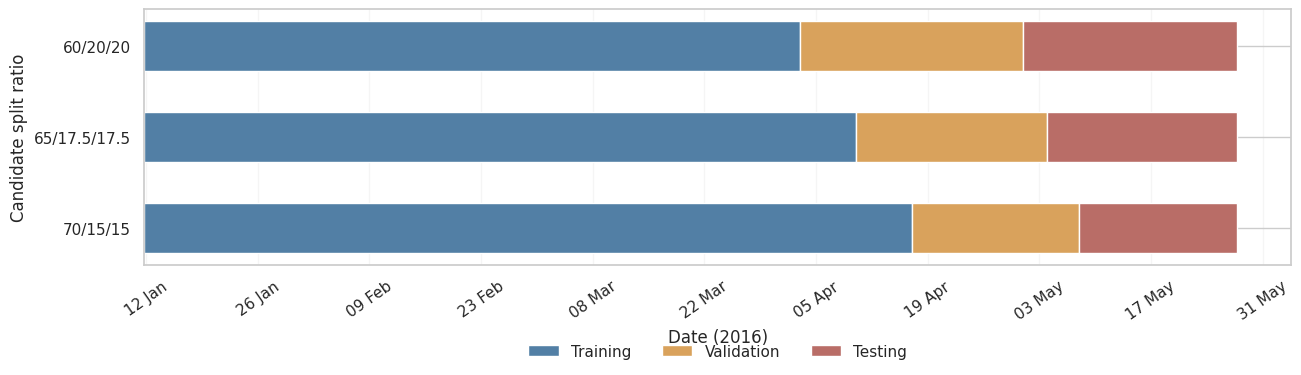


CELL 12 COMPLETED
Dataset integrity: PASS
Split alternatives examined: 3
Final split selected: NO
Final preprocessing selected: NO
Model training performed: NO

Saved:
- /content/drive/MyDrive/Stability_Driven_Energy/09_experiment_metadata/notebook01_split_feasibility.csv
- /content/drive/MyDrive/Stability_Driven_Energy/01_eda/12_temporal_split_feasibility.png
- /content/drive/MyDrive/Stability_Driven_Energy/09_experiment_metadata/notebook01_final_checkpoint.json


In [21]:

# ============================================================
# CELL 12 — PREPARATION CHECKPOINT & SPLIT FEASIBILITY
# Stability-Driven Appliance Energy Evaluation
# ============================================================

import json
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from matplotlib.patches import Patch
from IPython.display import display

# ------------------------------------------------------------
# 1. Load saved datasets and metadata
# ------------------------------------------------------------

TARGET = "Appliances"
TIME_COL = "date"

path_A = PATHS["processed"] / "candidate_feature_set_A.csv"
path_B = PATHS["processed"] / "candidate_feature_set_B.csv"

protocol_path = (
    PATHS["metadata"] /
    "notebook01_preprocessing_strategy.json"
)

with open(protocol_path, "r", encoding="utf-8") as f:
    protocol = json.load(f)

A = pd.read_csv(path_A, parse_dates=[TIME_COL])
B = pd.read_csv(path_B, parse_dates=[TIME_COL])

# ------------------------------------------------------------
# 2. Check saved dataset integrity
# ------------------------------------------------------------

def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(
            lambda: f.read(1024 * 1024), b""
        ):
            digest.update(chunk)
    return digest.hexdigest()


assert A.shape == (19735, 27)
assert B.shape == (19735, 29)

assert A[TIME_COL].equals(B[TIME_COL])
assert A[TARGET].equals(B[TARGET])

assert A[TIME_COL].is_unique
assert A[TIME_COL].is_monotonic_increasing

assert (
    A[TIME_COL].diff().dropna()
    == pd.Timedelta(minutes=10)
).all()

assert A.isna().sum().sum() == 0
assert B.isna().sum().sum() == 0

assert (
    file_sha256(path_A)
    == protocol["source_data_checksums"]["candidate_A_sha256"]
)

assert (
    file_sha256(path_B)
    == protocol["source_data_checksums"]["candidate_B_sha256"]
)

feature_A = protocol["feature_sets"]["A"]
feature_B = protocol["feature_sets"]["B"]

assert A.columns.tolist() == (
    [TIME_COL] + feature_A + [TARGET]
)

assert B.columns.tolist() == (
    [TIME_COL] + feature_B + [TARGET]
)

assert set(feature_B) - set(feature_A) == {
    "time_sin", "time_cos"
}

np.testing.assert_allclose(
    A[feature_A].to_numpy(dtype=float),
    B[feature_A].to_numpy(dtype=float),
    rtol=1e-10,
    atol=1e-10
)

print("=" * 70)
print("CELL 12 — PREPARATION CHECKPOINT")
print("=" * 70)

print("Saved dataset integrity: PASS")
print("Checksum verification: PASS")
print("Timestamp continuity: PASS")
print("Feature consistency: PASS")
print("Target alignment: PASS")

# ------------------------------------------------------------
# 3. Chronological split feasibility
# ------------------------------------------------------------

# These alternatives are only design previews.
# No model training, target inspection by split,
# or final partitioning is performed here.

split_options = {
    "60/20/20": (0.60, 0.20, 0.20),
    "65/17.5/17.5": (0.65, 0.175, 0.175),
    "70/15/15": (0.70, 0.15, 0.15)
}

dates = A[TIME_COL]
N = len(A)

records = []

for name, (p_train, p_val, p_test) in split_options.items():

    assert np.isclose(
        p_train + p_val + p_test, 1.0
    )

    # Tentative boundaries based on observation positions
    first_boundary_index = int(N * p_train)
    second_boundary_index = int(
        N * (p_train + p_val)
    )

    # Move boundaries to the beginning of a new day
    train_val_boundary = (
        dates.iloc[first_boundary_index].ceil("D")
    )

    val_test_boundary = (
        dates.iloc[second_boundary_index].ceil("D")
    )

    # Purely positional chronological partition preview
    idx_1 = int(
        dates.searchsorted(train_val_boundary)
    )

    idx_2 = int(
        dates.searchsorted(val_test_boundary)
    )

    assert 0 < idx_1 < idx_2 < N

    train_dates = dates.iloc[:idx_1]
    val_dates = dates.iloc[idx_1:idx_2]
    test_dates = dates.iloc[idx_2:]

    def coverage_days(series):
        return (
            (
                series.iloc[-1]
                - series.iloc[0]
                + pd.Timedelta(minutes=10)
            ).total_seconds() / 86400
        )

    records.append({
        "candidate": name,
        "n_train": len(train_dates),
        "n_validation": len(val_dates),
        "n_test": len(test_dates),
        "train_pct": len(train_dates) / N * 100,
        "validation_pct": len(val_dates) / N * 100,
        "test_pct": len(test_dates) / N * 100,
        "train_start": train_dates.iloc[0],
        "train_end": train_dates.iloc[-1],
        "validation_start": val_dates.iloc[0],
        "validation_end": val_dates.iloc[-1],
        "test_start": test_dates.iloc[0],
        "test_end": test_dates.iloc[-1],
        "train_days": coverage_days(train_dates),
        "validation_days": coverage_days(val_dates),
        "test_days": coverage_days(test_dates)
    })

split_feasibility = pd.DataFrame(records)

print("\nA. TEMPORAL SPLIT FEASIBILITY")
display(
    split_feasibility.round(3)
)

# ------------------------------------------------------------
# 4. Visualize candidate split timelines
# ------------------------------------------------------------

colors = {
    "train": "#527FA5",
    "validation": "#D9A25C",
    "test": "#B96D67"
}

fig, ax = plt.subplots(figsize=(13.5, 4))

for i, row in split_feasibility.iterrows():

    segments = [
        (
            row["train_start"],
            row["validation_start"],
            colors["train"]
        ),
        (
            row["validation_start"],
            row["test_start"],
            colors["validation"]
        ),
        (
            row["test_start"],
            row["test_end"] + pd.Timedelta(minutes=10),
            colors["test"]
        )
    ]

    for start, end, color in segments:

        left = mdates.date2num(start)
        right = mdates.date2num(end)

        ax.barh(
            i,
            right - left,
            left=left,
            height=0.55,
            color=color,
            edgecolor="white"
        )

ax.set_yticks(
    range(len(split_feasibility))
)

ax.set_yticklabels(
    split_feasibility["candidate"]
)

ax.invert_yaxis()

ax.set_xlabel("Date (2016)")
ax.set_ylabel("Candidate split ratio")

ax.xaxis.set_major_locator(
    mdates.WeekdayLocator(interval=2)
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%d %b")
)

ax.tick_params(axis="x", rotation=35)
ax.grid(axis="x", alpha=0.18)
ax.set_axisbelow(True)

ax.legend(
    handles=[
        Patch(
            facecolor=colors["train"],
            label="Training"
        ),
        Patch(
            facecolor=colors["validation"],
            label="Validation"
        ),
        Patch(
            facecolor=colors["test"],
            label="Testing"
        )
    ],
    loc="lower center",
    bbox_to_anchor=(0.5, -0.42),
    ncol=3,
    frameon=False
)

fig.subplots_adjust(
    left=0.13,
    right=0.98,
    top=0.96,
    bottom=0.32
)

figure_path = (
    PATHS["eda"] /
    "12_temporal_split_feasibility.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 5. Save feasibility report and checkpoint
# ------------------------------------------------------------

split_path = (
    PATHS["metadata"] /
    "notebook01_split_feasibility.csv"
)

split_feasibility.to_csv(
    split_path,
    index=False
)

checkpoint = {
    "notebook": "01_Data_Exploration_and_Preparation",
    "original_observations": int(N),
    "feature_set_A_count": len(feature_A),
    "feature_set_B_count": len(feature_B),

    "data_integrity_verified": True,
    "preprocessing_strategy_documented": True,

    "split_candidates": list(split_options.keys()),
    "final_split_selected": None,

    "final_feature_set_selected": None,
    "final_target_transform_selected": None,

    "model_fitting_completed": False,
    "validation_used": False,
    "test_used_for_model_selection": False
}

checkpoint_path = (
    PATHS["metadata"] /
    "notebook01_final_checkpoint.json"
)

with open(
    checkpoint_path,
    "w",
    encoding="utf-8"
) as f:
    json.dump(checkpoint, f, indent=4)

print("\n" + "=" * 70)
print("CELL 12 COMPLETED")
print("=" * 70)

print("Dataset integrity: PASS")
print("Split alternatives examined:", len(split_options))
print("Final split selected: NO")
print("Final preprocessing selected: NO")
print("Model training performed: NO")

print("\nSaved:")
print("-", split_path)
print("-", figure_path)
print("-", checkpoint_path)
